# Guía PC2 · Regresión y series de tiempo en Colab

Guía basada en RapiMenú, agentes y recaudación de la carpeta referencias. **No necesitas ejecutar ambas rutas**: si tu objetivo es un número por registro, usa regresión; si debes pronosticar periodos futuros, usa series.

| Tiempo orientativo | Actividad |
|---|---|
| 10 min | Carga, objetivo y configuración |
| 20 min | Calidad, correcciones y exploración |
| 40 min | Preparación, modelos y métricas |
| 20 min | Elección, prueba y explicación |
| 20 min | Datos nuevos y conclusiones |

1. Sube tus archivos al panel **Archivos** de Colab y copia su ruta.
2. Edita las celdas **EDITAR AQUÍ**. Ejecuta las celdas **EJECUTAR** en orden y la ruta que corresponda.
3. Las celdas **OPCIONAL** solo se activan si el enunciado las solicita.
4. Descarga los CSV de la carpeta de salidas y guarda el notebook. Los tiempos dependen de tu base.

## 1. Entorno y configuración
Ejecuta la instalación una vez. Si Colab pide reiniciar la sesión, reinicia y vuelve a importar. No se instalan AutoML, TensorFlow ni SHAP durante el recorrido básico.

In [2]:
%pip install -q "pandas>=2.2,<3" "numpy>=1.26,<2.3" "scikit-learn>=1.5,<1.7" "matplotlib>=3.8,<4" "seaborn>=0.13,<1" "xgboost>=2.1.4,<3" "lightgbm>=4.6,<5" openpyxl

In [3]:
# EJECUTAR
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
sns.set_theme(style="whitegrid")

### EDITAR AQUÍ · Datos y parámetros del caso

Cambia la ruta y copia los nombres de columnas exactamente como aparecen en la base. CATEGORICAS vacía detecta tipos automáticamente; añade códigos numéricos que en realidad sean categorías, por ejemplo ["codigo_zona"]. Excluye identificadores, fechas no transformadas y datos que no estén disponibles al momento de predecir.

**Lectura:** SEPARADOR = None intenta detectar coma o punto y coma; también puedes escribir "," o ";". DECIMAL = "," sirve si los decimales son comas. HOJA_EXCEL puede ser 0 (primera hoja) o el nombre de una hoja. Ajusta codificación si tu CSV no usa UTF-8.

En series, un horizonte de 21 con frecuencia diaria son 21 días. Especifica el formato de fechas de tu archivo y adapta rezagos, media y feriados a la frecuencia. Una frecuencia semanal o mensual necesita rezagos apropiados, por ejemplo [1, 2, 3] y ventana 3.

**Feriados de Perú:** con USAR_FERIADOS_PERU = True se generan automáticamente los feriados nacionales para cada año de la historia y las fechas pronosticadas. FERIADOS queda disponible para añadir fechas regionales, extraordinarias o días no laborables si afectan a tu caso. Si tu serie corresponde a otro país, usa False e ingresa las fechas necesarias en FERIADOS.

In [6]:
RUTA_ARCHIVO = "/content/PD_recaudos_trx.csv"

df = pd.read_csv(RUTA_ARCHIVO)

# Identificación automática de variables
columnas_numericas = df.select_dtypes(include=['number']).columns.tolist()
columnas_categoricas = df.select_dtypes(exclude=['number']).columns.tolist()

print("Variables Numéricas:", columnas_numericas)
print("Variables Categóricas:", columnas_categoricas)

df.head()

Variables Numéricas: ['cant_trx']
Variables Categóricas: ['fecha']


,fecha,cant_trx
0,2024-01-01,12889
1,2024-01-02,73435
2,2024-01-03,77030
3,2024-01-04,72748
4,2024-01-05,78184


In [7]:
# EDITAR AQUÍ: datos de tu examen
TIPO_PROBLEMA = "serie_tiempo"  # "regresion", "serie_tiempo" o "clasificacion" (anexo)
TARGET = "cant_trx"  # Columna numérica que deseas predecir
UNIDAD = "soles"  # Unidad de TARGET para interpretar gráficos; no convierte valores
COLUMNAS_EXCLUIR = []  # Ejemplo: ["id_pedido", "fecha_hora"]
CATEGORICAS = []  # Opcional: columnas numéricas que son códigos, no cantidades
SEPARADOR = None  # None detecta el separador; también acepta "," o ";"
CODIFICACION = "utf-8-sig"  # Prueba "latin1" si el CSV tiene otra codificación
DECIMAL = "."  # Usa "," si el archivo escribe 2,5 en lugar de 2.5
HOJA_EXCEL = 0  # Índice de hoja (0 es la primera) o nombre de la hoja
SEMILLA = 42  # Repite la misma partición aleatoria

# EDITAR AQUÍ: solo si TIPO_PROBLEMA = "serie_tiempo"
FECHA = "fecha"
FORMATO_FECHA = "%Y-%m-%d"  # Por ejemplo: "%d/%m/%Y"
FRECUENCIA = "D"  # "D" diaria, "W-MON" semanal o "MS" inicio de mes
HORIZONTE = 21  # Número de periodos para validación, prueba y futuro por defecto
REZAGOS = [1, 7, 14]  # Valores de 1, 7 y 14 periodos anteriores
VENTANA = 7  # Cantidad de valores anteriores para la media móvil
USAR_FERIADOS_PERU = True  # True genera automáticamente los feriados nacionales del Perú
FERIADOS = []  # Opcional: agrega fechas extraordinarias o regionales, ej. ["2026-01-02"]
CRITERIO_SERIES = "MAPE_pct"  # "MAPE_pct", "MAE" o "RMSE": menor es mejor

# EDITAR AQUÍ: indicadores de negocio opcionales
TOLERANCIA = None  # Ejemplo: 500. None omite los porcentajes basados en umbral
META_RELATIVA = None  # Ejemplo: 0.5 significa reducir la tasa base al 50 %
COSTO_POR_CASO = None  # Ejemplo: 40.0, costo de una subestimación fuera de tolerancia
CASOS_POR_MES = None  # Ejemplo: 27000; cantidad mensual estimada de decisiones
COLUMNA_SEGMENTO = None  # Ejemplo: "zona"; nombre de columna para agrupar el error


### ¿Qué significa cada parámetro de la configuración?

En Python, el texto va entre comillas; los números y los valores especiales como **None**, **True** y **False** van sin comillas. Una lista vacía se escribe **[]**. Por ejemplo, usa TARGET = "tiempo_entrega_min" y HORIZONTE = 21.

| Parámetro | Qué debes poner y para qué sirve |
|---|---|
| **RUTA_ARCHIVO** | Ruta de la base histórica con la que vas a entrenar. Si subes pedidos.csv a Archivos en Colab, usa "/content/pedidos.csv". Es el archivo original, no la base nueva que quieras predecir. |
| **TIPO_PROBLEMA** | Usa "regresion" cuando cada fila sea un pedido, cliente u otro caso y quieras predecir un número. Usa "serie_tiempo" cuando quieras pronosticar valores futuros a partir de una fecha y su historia. "clasificacion" activa el anexo cuando la respuesta son categorías. |
| **TARGET** | Nombre exacto de la columna cuyo valor deseas predecir; debe existir en la base histórica. Ejemplo: "tiempo_entrega_min", "monto_retiros" o "cant_trx". El notebook separa esta columna de los predictores. |
| **UNIDAD** | Unidad en que está expresado **TARGET**, no alguna otra columna. Para "tiempo_entrega_min" usa "minutos"; para un monto en soles, "S/"; para "cant_trx", "transacciones". Es una etiqueta para leer gráficos: no convierte los datos ni cambia el entrenamiento o las predicciones. |
| **COLUMNAS_EXCLUIR** | Lista de columnas que existen en la base pero no deben alimentar el modelo, como ["id_pedido", "fecha_hora"]. Excluye identificadores y datos que solo se conocen después del resultado. No pongas TARGET aquí: ya se separa automáticamente. Con [] no excluyes ninguna. |
| **CATEGORICAS** | Lista de columnas numéricas que son códigos o grupos y no cantidades, por ejemplo ["codigo_zona"] si 1 y 2 identifican zonas. El texto y las categorías ya se detectan automáticamente. Con [] no fuerzas columnas adicionales. Estas columnas no deben estar en COLUMNAS_EXCLUIR. |
| **SEPARADOR** | Carácter que separa columnas del CSV. None intenta detectarlo; usa ";" si ves columnas separadas por punto y coma o "," si usan comas. No afecta los archivos Excel. |
| **CODIFICACION** | Forma en que se guardaron las letras del CSV. Deja "utf-8-sig" por defecto; si aparecen errores de lectura por caracteres, prueba "latin1". No cambia el contenido numérico a otra escala. |
| **DECIMAL** | Símbolo que indica los decimales en un CSV: "." para 12.5 o "," para 12,5. No es necesariamente el mismo carácter que separa columnas; por ejemplo, un CSV puede usar punto y coma entre columnas y coma decimal. |
| **HOJA_EXCEL** | Hoja del archivo Excel: 0 es la primera, 1 la segunda o puedes escribir un nombre como "Ventas". Se ignora para CSV. |
| **SEMILLA** | Número que controla la división aleatoria en regresión y la aleatoriedad de algunos modelos. Dejar 42 facilita repetir los mismos resultados con los mismos datos y configuración; no representa una columna de la base. |

**Ejemplo de lectura de resultados:** si TARGET es tiempo de entrega en minutos, un MAE de 5 significa que la diferencia absoluta entre la predicción y el valor real es de **5 minutos en promedio**. El RMSE también se expresa en minutos; el MSE se expresa en minutos al cuadrado. MAPE es un porcentaje y R² no tiene unidad.

### ¿Qué significan los parámetros de series de tiempo?

Solo necesitas esta parte si TIPO_PROBLEMA = "serie_tiempo". Una serie usa una fecha y un valor de TARGET por periodo, por ejemplo, una fila por día con la cantidad diaria de transacciones.

| Parámetro | Qué debes poner y para qué sirve |
|---|---|
| **FECHA** | Nombre exacto de la columna que contiene las fechas, por ejemplo "fecha". Es distinta de TARGET: FECHA indica **cuándo**, TARGET indica **cuánto ocurrió**. |
| **FORMATO_FECHA** | Cómo está escrita cada fecha de tu archivo. "%Y-%m-%d" interpreta 2026-11-03; "%d/%m/%Y" interpreta 03/11/2026. Debe coincidir con la base histórica y con las observaciones nuevas. |
| **FRECUENCIA** | Distancia entre filas consecutivas: "D" para cada día, "W-MON" para cada lunes, "MS" para el primer día de cada mes. La serie debe tener una fila por periodo y no debe tener fechas duplicadas ni huecos. |
| **HORIZONTE** | Cantidad de periodos que se desean pronosticar y que se reservan **por separado** para validación y prueba. Con HORIZONTE = 21 y frecuencia diaria, los últimos 21 días son prueba, los 21 anteriores validación y, por defecto, se pronostican los próximos 21 días. Para semanas o meses, 21 son 21 semanas o 21 meses. |
| **REZAGOS** | Valores de TARGET de periodos anteriores que se usan para estimar el siguiente. En datos diarios, [1, 7, 14] usa el valor de ayer, de hace 7 días y de hace 14 días. En datos mensuales, [1, 2, 3] son los tres meses anteriores. Los números cuentan periodos de FRECUENCIA. |
| **VENTANA** | Cantidad de valores anteriores que se promedian para crear la media móvil. Con frecuencia diaria y VENTANA = 7 se usa el promedio de los 7 días previos; en una serie mensual, 3 significa los 3 meses previos. El valor de la fila que se intenta predecir no se incluye. |
| **USAR_FERIADOS_PERU** | True agrega automáticamente la marca de feriados nacionales peruanos. False la desactiva; puedes conservar fechas adicionales en FERIADOS. Es una variable de calendario que puede ayudar al modelo, no una orden de eliminar filas. |
| **FERIADOS** | Fechas adicionales a las nacionales automáticas, por ejemplo ["2026-01-02", "2026-06-24"] para días extraordinarios o regionales pertinentes. [] no agrega fechas extra. Escríbelas como año-mes-día, incluso si FORMATO_FECHA para la base es distinto. |
| **CRITERIO_SERIES** | Métrica de validación para elegir automáticamente el modelo: "MAPE_pct", "MAE" o "RMSE". Se escoge el valor más bajo. MAPE_pct representa porcentaje de error en reales distintos de cero; MAE y RMSE están en la unidad de TARGET. |

El horizonte, los rezagos y la ventana deben poder calcularse con la cantidad de historia disponible. Ejemplo: si solo tienes 30 días, reservar dos ventanas de 21 días deja sin datos para entrenar; necesitas más historia o un horizonte menor.

### Parámetros de negocio: ¿cuándo necesito completarlos?

Son opcionales. Déjalos en **None** si el examen no proporciona esos datos. Estos indicadores usan las mismas unidades que TARGET y no sustituyen a MAE o RMSE.

| Parámetro | Significado y ejemplo |
|---|---|
| **TOLERANCIA** | Tamaño del error que el negocio considera relevante, expresado en la unidad de TARGET. Si TARGET es un monto en soles y TOLERANCIA = 500, se calcula el porcentaje de casos con real − predicho mayor a S/ 500, y también el porcentaje con error absoluto mayor a S/ 500. Si TARGET es tiempo en minutos, la tolerancia se interpreta en minutos. |
| **META_RELATIVA** | Fracción de la tasa de subestimación de la regla actual que se acepta como meta. Si la regla tiene 20 % de casos fuera de tolerancia y META_RELATIVA = 0.5, la meta es 10 % o menos. Para compararla, activa USAR_REGLA_ACTUAL y define la regla en su sección. |
| **COSTO_POR_CASO** | Costo monetario estimado por cada caso donde real − predicho supera TOLERANCIA. Ejemplo: 40.0 significa S/ 40 por caso si tus datos de costo están en soles; no es el costo por cada unidad de error. |
| **CASOS_POR_MES** | Cantidad estimada de decisiones por mes, por ejemplo 27000 operaciones. Con la regla, la tolerancia y COSTO_POR_CASO permite proyectar un costo mensual y una diferencia estimada frente al modelo. |
| **COLUMNA_SEGMENTO** | Nombre de una columna de la base para calcular el MAE por grupo, como "zona" o "tipo_restaurante". Sirve para observar dónde se equivoca más el modelo. Con None no se calcula el desglose. |

**Ejemplo:** si se pronostica un retiro de S/ 1,000 y el retiro real es S/ 1,600, el modelo subestimó S/ 600. Si la tolerancia es S/ 500, este caso supera el umbral. Si el valor real fuera S/ 400, el error absoluto también sería S/ 600, pero sería una **sobreestimación**, no una subestimación.

### 1.1 Herramientas comunes · EJECUTAR PARA AMBAS RUTAS
Ejecuta la siguiente celda después de las importaciones y la configuración, tanto para regresión como para series de tiempo. Define metricas, mostrar_modelo y el diccionario modelos. Luego puedes saltar la ruta de regresión si trabajas con series. Si reinicias la sesión, vuelve a ejecutar este bloque antes de entrenar modelos.

- **MAE:** error absoluto promedio, en la unidad del objetivo; menor es mejor.
- **MSE:** promedio de errores al cuadrado; castiga errores grandes y está en unidades al cuadrado.
- **RMSE:** raíz del MSE, en la unidad del objetivo; menor es mejor.
- **MAPE:** error porcentual promedio para valores reales distintos de cero; se informa cuántos ceros se excluyeron. Si todos son cero, queda sin definir.
- **R²:** mejora frente a predecir el promedio del conjunto evaluado; 1 es perfecto, 0 equivale al promedio y puede ser negativo. Con una sola observación no se calcula.

La diagonal en real/predicho representa predicción perfecta. En residuos, cero es ausencia de error y real − predicho positivo indica subestimación. Las importancias muestran influencia asociada al modelo, no causalidad. Las cifras de train y validación permiten detectar brechas; prueba se reserva hasta la elección.

**Ejemplo de error:** si el valor real es 60 minutos y el modelo predice 55, el residuo es 60 − 55 = 5 minutos: el modelo subestimó en 5 minutos. Si predice 65, el residuo es −5: sobreestimó en 5 minutos. El error absoluto en ambos casos es 5.

**Qué es cada conjunto:** train o entrenamiento son los datos con los que el modelo aprende; validación sirve para comparar modelos y elegir; prueba son datos reservados para comprobar el elegido al final. Un valor de train mucho mejor que validación puede señalar sobreajuste: el modelo se adaptó demasiado a los datos con los que aprendió.

In [45]:
# EJECUTAR
def metricas(reales, predicciones):
    """Calcula indicadores de error para comparar una predicción con la realidad.

    Parámetros:
        reales (lista, array o Series): valores observados, ordenados igual que las predicciones.
        predicciones (lista, array o Series): valores estimados para esas mismas filas o fechas.
    Retorna: diccionario con número de observaciones, MAE, MSE, RMSE, MAPE_pct, R2 y ceros_MAPE.
        Si se configuró TOLERANCIA también devuelve porcentajes de subestimación y error absoluto.
        MAPE omite reales cero; cuando todos son cero es NaN. R2 requiere al menos dos filas.
    Ejemplo: metricas([10, 20], [12, 18]) compara las dos filas en orden;
        los errores absolutos son 2 y 2, por lo que el MAE es 2 unidades de TARGET.
    """
    real, pred = np.asarray(reales, dtype=float), np.asarray(predicciones, dtype=float)
    if real.ndim != 1 or pred.ndim != 1 or len(real) == 0 or len(real) != len(pred):
        raise ValueError("Reales y predicciones deben ser vectores no vacíos del mismo tamaño.")
    if not np.isfinite(real).all() or not np.isfinite(pred).all():
        raise ValueError("Reales y predicciones deben ser valores numéricos finitos.")
    no_cero = real != 0
    mse = mean_squared_error(real, pred)
    resultado = {"n_obs": len(real), "MAE": mean_absolute_error(real, pred), "MSE": mse,
        "RMSE": np.sqrt(mse), "MAPE_pct": np.mean(np.abs((real[no_cero] - pred[no_cero]) / real[no_cero])) * 100 if no_cero.any() else np.nan,
        "R2": r2_score(real, pred) if len(real) > 1 else np.nan, "ceros_MAPE": int((~no_cero).sum())}
    if TOLERANCIA is not None:
        if not np.isfinite(TOLERANCIA) or TOLERANCIA < 0:
            raise ValueError("TOLERANCIA debe ser un número no negativo o None.")
        resultado["subestimacion_pct"] = np.mean(real - pred > TOLERANCIA) * 100
        resultado["error_fuera_pct"] = np.mean(np.abs(real - pred) > TOLERANCIA) * 100
    return resultado


def crear_preparacion(X):
    """Construye, sin ajustar, las transformaciones para los predictores de una base.

    Parámetro:
        X (DataFrame): filas y columnas predictoras; no debe incluir el objetivo.
        CATEGORICAS, definida en configuración, fuerza como categoría los nombres indicados.
    Retorna: ColumnTransformer sin ajustar; el Pipeline lo ajusta solo con entrenamiento.
    Las cantidades reciben mediana y escalado; las categorías, moda y one-hot tolerante a valores nuevos.
        La mediana y la moda se calculan con las filas usadas en fit. One-hot crea indicadores
        para cada categoría aprendida; una categoría no vista se acepta sin crear nuevas columnas.
    Ejemplo: preparador = crear_preparacion(X_train); preparador.fit(X_train).
    """
    numericas = [c for c in X.select_dtypes(include="number").columns if c not in CATEGORICAS]
    categoricas = [c for c in X.columns if c not in numericas]
    return ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median", keep_empty_features=True)),
                          ("escalar", StandardScaler())]), numericas),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
                          ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categoricas)])


def mostrar_modelo(nombre, modelo, reales_train, pred_train, reales_validacion, pred_validacion, temporal=False):
    """Presenta métricas y gráficos de un modelo ya ajustado, sin volver a entrenarlo.

    Parámetros:
        nombre (str): etiqueta que identifica el modelo en títulos y tabla.
        modelo (Pipeline, estimador o None): modelo ya entrenado; None representa persistencia sin variables.
        reales_train (Series o array): valores reales de entrenamiento alineados con pred_train.
        pred_train (Series o array): estimaciones de entrenamiento, una por cada valor real.
        reales_validacion (Series o array): valores reales de validación, en el mismo orden que sus predicciones. En series usa una Series con índice de fechas.
        pred_validacion (Series o array): predicciones para validación; en series deben ser recursivas.
        temporal (bool): True dibuja la curva por fechas; False usa gráfico de residuos. Por defecto False.
            Por ejemplo, usa temporal=True para un pronóstico de transacciones por día.
    Retorna: None. Muestra tabla, dispersión, residuos/curva e importancia si existe.
    Ejemplo: mostrar_modelo('Lineal', modelo_lineal, y_train, pred_train, y_validacion, pred_val).
    """
    tabla = pd.DataFrame([metricas(reales_train, pred_train), metricas(reales_validacion, pred_validacion)],
                         index=["Train: un paso" if temporal else "Train", "Validación recursiva" if temporal else "Validación"])
    print(nombre)
    display(tabla.round(3))
    real, pred = np.asarray(reales_validacion), np.asarray(pred_validacion)
    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
    ejes[0].scatter(real, pred, alpha=0.5, s=18)
    limites = [min(real.min(), pred.min()), max(real.max(), pred.max())]
    ejes[0].plot(limites, limites, '--', color='gray')
    ejes[0].set(xlabel=f'Real ({UNIDAD})', ylabel=f'Predicho ({UNIDAD})', title=f'{nombre}: real vs. predicho')
    if temporal:
        ejes[1].plot(reales_validacion.index, real, label='Real')
        ejes[1].plot(reales_validacion.index, pred, '--', label='Pronóstico recursivo')
        ejes[1].tick_params(axis='x', rotation=30)
        ejes[1].set_title('Validación a través del tiempo')
        ejes[1].legend()
    else:
        ejes[1].scatter(pred, real - pred, alpha=0.5, s=18)
        ejes[1].axhline(0, color='gray', linestyle='--')
        ejes[1].set(xlabel='Predicho', ylabel='Real − predicho', title='Residuos de validación')
    plt.tight_layout()
    plt.show()
    if not temporal:
        sns.histplot(real - pred, bins=30)
        plt.title(f'{nombre}: distribución de residuos de validación')
        plt.xlabel(f'Real − predicho ({UNIDAD})')
        plt.show()
    if modelo is not None:
        estimador = modelo.named_steps['modelo'] if isinstance(modelo, Pipeline) else modelo
        if hasattr(estimador, 'feature_importances_') or hasattr(estimador, 'coef_'):
            nombres = modelo.named_steps['preparacion'].get_feature_names_out() if isinstance(modelo, Pipeline) else X_train_temporal.columns
            valores = estimador.feature_importances_ if hasattr(estimador, 'feature_importances_') else np.abs(estimador.coef_)
            pd.Series(valores, index=nombres).nlargest(12).sort_values().plot.barh(title=f'{nombre}: variables principales', figsize=(8, 4))
            plt.tight_layout()
            plt.show()

modelos = {}


## 2. Carga y calidad · EJECUTAR
La función leer_archivo abre CSV o Excel y recibe las opciones configuradas arriba. Revisa nombres, tipos, nulos y duplicados antes de decidir cualquier corrección. Las mismas opciones se usan con la base nueva.

In [8]:
# EJECUTAR
def leer_archivo(ruta, separador=None, codificacion="utf-8-sig", decimal=".", hoja=0):
    """Abre un CSV o Excel y devuelve su contenido como DataFrame.

    Parámetros:
        ruta (str o Path): ubicación del archivo. Ejemplo: '/content/datos.csv'.
        separador (str o None): separa columnas de CSV; None lo detecta. Por defecto None.
        codificacion (str): codificación del CSV; por defecto 'utf-8-sig'. Prueba 'latin1' si falla.
        decimal (str): símbolo decimal de números del CSV; por defecto '.', alternativamente ','.
        hoja (int o str): índice desde cero o nombre de la hoja Excel; por defecto 0.
    Retorna: DataFrame con las filas y columnas originales.
    Ejemplo: leer_archivo('/content/ventas.csv', separador=';', decimal=',').
    """
    archivo = Path(ruta)
    if archivo.suffix.lower() in {".xlsx", ".xls"}:
        return pd.read_excel(archivo, sheet_name=hoja)
    if archivo.suffix.lower() == ".csv":
        return pd.read_csv(archivo, sep=separador, engine="python", encoding=codificacion, decimal=decimal)
    raise ValueError("Usa un archivo .csv o .xlsx. Para .xls puede ser necesario instalar xlrd.")

df_original = leer_archivo(RUTA_ARCHIVO, SEPARADOR, CODIFICACION, DECIMAL, HOJA_EXCEL)
if df_original.empty or not df_original.columns.is_unique:
    raise ValueError("La base está vacía o tiene columnas repetidas.")
if TIPO_PROBLEMA not in {"regresion", "serie_tiempo", "clasificacion"}:
    raise ValueError("Elige regresion, serie_tiempo o clasificacion.")
if TARGET not in df_original or set(COLUMNAS_EXCLUIR + CATEGORICAS) - set(df_original.columns):
    raise ValueError("Revisa TARGET, COLUMNAS_EXCLUIR y CATEGORICAS: deben existir en el archivo.")
if TARGET in CATEGORICAS or set(CATEGORICAS) & set(COLUMNAS_EXCLUIR):
    raise ValueError("CATEGORICAS solo debe contener predictores que no estén excluidos.")
if TIPO_PROBLEMA == "serie_tiempo" and FECHA not in df_original:
    raise ValueError("La columna FECHA no existe en tu archivo.")
print("Archivo cargado. Continúa con la inspección de la siguiente celda.")

Archivo cargado. Continúa con la inspección de la siguiente celda.


### 2.1 Inspeccionar los datos · EJECUTAR

Esta celda muestra la forma de la base original, sus primeras y últimas filas, los nombres, tipos, nulos y duplicados. **No limpia ni modifica la base**: sirve para decidir qué conversiones o correcciones necesitas. La tabla original siempre permanece disponible como df_original.

In [9]:
# EJECUTAR · Inspección inicial: no modifica df_original
def inspeccionar_datos(datos):
    """Muestra la estructura y calidad inicial de una tabla sin modificarla.

    Parámetro:
        datos (DataFrame): base que deseas revisar, por ejemplo df_original.
    Retorna: None. Muestra primeras/últimas filas, columnas, tipos, nulos y duplicados.
    Ejemplo: inspeccionar_datos(df_original).
    """
    print("Filas y columnas:", datos.shape)
    print("Columnas:", datos.columns.tolist())
    print("Primeras filas:")
    display(datos.head())
    print("Últimas filas:")
    display(datos.tail())
    display(pd.DataFrame({"tipo": datos.dtypes, "nulos": datos.isna().sum(),
                          "nulos_pct": datos.isna().mean().mul(100)}))
    print("Filas completamente duplicadas:", datos.duplicated().sum())

inspeccionar_datos(df_original)

Filas y columnas: (653, 2)
Columnas: ['fecha', 'cant_trx']
Primeras filas:


,fecha,cant_trx
0,2024-01-01,12889
1,2024-01-02,73435
2,2024-01-03,77030
3,2024-01-04,72748
4,2024-01-05,78184


Últimas filas:


,fecha,cant_trx
648,2025-10-10,78420
649,2025-10-11,64342
650,2025-10-12,45892
651,2025-10-13,90889
652,2025-10-14,80558


,tipo,nulos,nulos_pct
fecha,object,0,0.0
cant_trx,int64,0,0.0


Filas completamente duplicadas: 0


### 2.2 Cambiar tipos de datos · EJECUTAR

La siguiente celda genera **df_tipos** a partir de una copia de df_original. Detecta columnas de texto cuyos valores presentes son todos numéricos; respeta las columnas declaradas como CATEGORICAS, los identificadores excluidos y los códigos con ceros iniciales. Para series convierte FECHA usando FORMATO_FECHA.

Después se muestran los tipos y la cantidad de valores que quedaron nulos durante las conversiones. Si una columna mezcla números y texto, se muestra un aviso para que decidas si corresponde forzarla a numérica. La lista de columnas numéricas se conserva para aplicar las mismas conversiones a una base nueva.

### EDITAR AQUÍ solo si el caso lo necesita

- **TIPOS_MANUALES = {}** deja actuar la detección automática. Para indicar columnas concretas, por ejemplo, usa {"monto": "numerico", "zona": "categoria", "fecha_registro": "fecha"}. Las fechas usan FORMATO_FECHA de la configuración inicial. Una conversión numérica o de fecha explícita muestra cuántos valores no se pudieron convertir; para TARGET numérico un valor inválido detiene la ejecución.
- **ELIMINAR_DUPLICADOS = True** elimina filas completamente iguales en la historia. Cambia a False si filas iguales pueden ser operaciones distintas. Se muestra cuántas se eliminaron; las filas de la base nueva se conservan.
- **RELLENAR_SERIE_ANTERIOR = False** deja pendiente cualquier TARGET nulo de una serie. Si el enunciado lo justifica, usa True para rellenar un nulo con el último valor anterior. No se crean fechas ausentes y rellenar valores reales puede afectar las métricas de evaluación.

Para una regla especial del caso, como convertir el código 999 en nulo, activa el ejemplo comentado dentro de convertir_tipos. Si una columna de texto tiene códigos como "001", consérvala como categoría. Cada función recibe la tabla del paso anterior y trabaja con una copia.

In [10]:
# EDITAR AQUÍ solo si tu caso lo necesita; {} usa la detección automática.
TIPOS_MANUALES = {"fecha":"fecha"}  # Ej.: {"monto": "numerico", "zona": "categoria", "fecha_registro": "fecha"}
ELIMINAR_DUPLICADOS = True  # False conserva filas históricas completamente iguales
RELLENAR_SERIE_ANTERIOR = False  # Solo series: True usa el último valor real anterior
COLUMNAS_NUMERICAS_DETECTADAS = []  # Se completa automáticamente con la historia


def convertir_tipos(datos, es_nueva=False):
    """Crea una copia con columnas numéricas, categóricas y fechas preparadas.

    Parámetros:
        datos (DataFrame): tabla original, por ejemplo df_original; no se modifica.
        es_nueva (bool): False, por defecto, detecta y guarda las columnas numéricas a partir
            de la historia. True reutiliza la lista histórica, conserva todas las filas y acepta
            que no exista TARGET. Los campos indicados en TIPOS_MANUALES también se reutilizan.
    Retorna: un DataFrame nuevo; informa conversiones y valores inválidos convertidos a nulos.
    TIPOS_MANUALES es un diccionario opcional: "numerico", "categoria" o "fecha" por columna.
    Las fechas usan FORMATO_FECHA. Un TARGET numérico inválido detiene la ejecución.
    Ejemplos: convertir_tipos(df_original) y convertir_tipos(df_nueva_original, es_nueva=True).
    """
    global COLUMNAS_NUMERICAS_DETECTADAS
    permitidos = {"numerico", "categoria", "fecha"}
    if any(tipo not in permitidos for tipo in TIPOS_MANUALES.values()):
        raise ValueError("TIPOS_MANUALES solo admite numerico, categoria o fecha.")
    if TIPO_PROBLEMA in {"regresion", "serie_tiempo"} and TARGET in TIPOS_MANUALES and TIPOS_MANUALES[TARGET] != "numerico":
        raise ValueError("El TARGET de regresión o series debe ser numérico.")
    if TIPO_PROBLEMA == "serie_tiempo" and FECHA in TIPOS_MANUALES and TIPOS_MANUALES[FECHA] != "fecha":
        raise ValueError("La columna FECHA de la serie debe ser de tipo fecha.")
    if any(c in CATEGORICAS and tipo != "categoria" for c, tipo in TIPOS_MANUALES.items()):
        raise ValueError("Una columna de CATEGORICAS solo puede indicarse como categoria en TIPOS_MANUALES.")
    ausentes = set(TIPOS_MANUALES) - set(datos.columns)
    if ausentes and not es_nueva:
        raise ValueError(f"TIPOS_MANUALES contiene columnas que no existen: {sorted(ausentes)}")
    datos_convertidos = datos.copy()
    for columna in datos_convertidos.select_dtypes(include=["object", "string"]).columns:
        datos_convertidos[columna] = datos_convertidos[columna].map(
            lambda valor: np.nan if isinstance(valor, str) and not valor.strip() else valor)

    # OPCIONAL · Copia una regla solo si tu enunciado la requiere. Se aplicará también a datos nuevos.
    # if "antiguedad_meses" in datos_convertidos:
    #     datos_convertidos.loc[datos_convertidos["antiguedad_meses"].isin([999, "999"]), "antiguedad_meses"] = np.nan
    # if "dia_semana" in datos_convertidos:
    #     datos_convertidos["fin_de_semana"] = datos_convertidos["dia_semana"].isin(["Sábado", "Domingo"]).astype(int)

    columnas_categoricas = set(CATEGORICAS) | {c for c, tipo in TIPOS_MANUALES.items() if tipo == "categoria"}
    for columna in columnas_categoricas:
        if columna in datos_convertidos:
            datos_convertidos[columna] = datos_convertidos[columna].map(
                lambda valor: np.nan if pd.isna(valor) else
                    str(int(valor)) if isinstance(valor, (float, np.floating)) and np.isfinite(valor) and float(valor).is_integer()
                    else str(valor)).astype(object)

    # Las conversiones explícitas se aplican antes de detectar los tipos automáticos.
    for columna, tipo in TIPOS_MANUALES.items():
        if columna not in datos_convertidos or tipo == "categoria":
            continue
        nulos_antes = int(datos_convertidos[columna].isna().sum())
        if tipo == "numerico":
            errores = "raise" if columna == TARGET and TIPO_PROBLEMA != "clasificacion" else "coerce"
            datos_convertidos[columna] = pd.to_numeric(datos_convertidos[columna], errors=errores)
        else:
            datos_convertidos[columna] = pd.to_datetime(datos_convertidos[columna], format=FORMATO_FECHA, errors="coerce")
        nuevos_nulos = int(datos_convertidos[columna].isna().sum()) - nulos_antes
        print(f"Conversión explícita de {columna} a {tipo}: {nuevos_nulos} valores inválidos convertidos a nulo.")

    if not es_nueva:
        COLUMNAS_NUMERICAS_DETECTADAS = [c for c in datos_convertidos.select_dtypes(include="number").columns
            if c not in columnas_categoricas and c not in COLUMNAS_EXCLUIR and c != FECHA
            and not (c == TARGET and TIPO_PROBLEMA == "clasificacion")]
        for columna in datos_convertidos.select_dtypes(include=["object", "string"]).columns:
            if columna in columnas_categoricas or columna in COLUMNAS_EXCLUIR or columna == FECHA:
                continue
            if columna == TARGET and TIPO_PROBLEMA == "clasificacion":
                continue
            presentes = datos_convertidos[columna].dropna()
            if presentes.empty:
                continue
            ceros_iniciales = presentes.astype(str).str.strip().str.match(r"^[+-]?0\d+").any()
            valores_numericos = pd.to_numeric(presentes, errors="coerce")
            if valores_numericos.notna().all() and (columna == TARGET or not ceros_iniciales):
                COLUMNAS_NUMERICAS_DETECTADAS.append(columna)
            elif valores_numericos.notna().any() and not valores_numericos.notna().all():
                print(f"Revisa '{columna}': mezcla números y texto. Si es numérica, agrégala a TIPOS_MANUALES.")
        print("Columnas numéricas identificadas:", COLUMNAS_NUMERICAS_DETECTADAS)

    for columna in COLUMNAS_NUMERICAS_DETECTADAS:
        if columna in datos_convertidos:
            nulos_antes = int(datos_convertidos[columna].isna().sum())
            errores = "raise" if columna == TARGET and TIPO_PROBLEMA != "clasificacion" else "coerce"
            datos_convertidos[columna] = pd.to_numeric(datos_convertidos[columna], errors=errores)
            nuevos_nulos = int(datos_convertidos[columna].isna().sum()) - nulos_antes
            if nuevos_nulos:
                print(f"Aviso: {columna} tiene {nuevos_nulos} valores inválidos convertidos a nulos.")
    if TIPO_PROBLEMA in {"regresion", "serie_tiempo"} and TARGET in datos_convertidos:
        datos_convertidos[TARGET] = pd.to_numeric(datos_convertidos[TARGET], errors="raise")
    if TIPO_PROBLEMA == "serie_tiempo" and FECHA in datos_convertidos:
        datos_convertidos[FECHA] = pd.to_datetime(datos_convertidos[FECHA], format=FORMATO_FECHA, errors="raise")
    return datos_convertidos


df_tipos = convertir_tipos(df_original)
print("Tipos antes y después:")
display(pd.DataFrame({"antes": df_original.dtypes, "despues": df_tipos.dtypes,
                      "nulos_antes": df_original.isna().sum(), "nulos_despues": df_tipos.isna().sum()}))

Conversión explícita de fecha a fecha: 0 valores inválidos convertidos a nulo.
Columnas numéricas identificadas: ['cant_trx']
Tipos antes y después:


,antes,despues,nulos_antes,nulos_despues
fecha,object,datetime64[ns],0,0
cant_trx,int64,int64,0,0


### 2.3 Revisar y tratar nulos · EJECUTAR

Esta celda recibe df_tipos y crea **df_sin_nulos**. Muestra cuántos nulos tiene cada columna. En regresión o clasificación retira de la historia las filas sin TARGET; los nulos de predictores permanecen para que el Pipeline aprenda mediana o moda con entrenamiento. En series, los nulos de TARGET se conservan salvo que actives RELLENAR_SERIE_ANTERIOR.

In [11]:
# EJECUTAR · Crea df_sin_nulos sin cambiar df_tipos
def tratar_nulos(datos, es_nueva=False, umbral_borrado_pct=5.0):
    """Revisa nulos y prepara una copia de la tabla para el siguiente paso.

    Parámetros:
        datos (DataFrame): tabla ya convertida, por ejemplo df_tipos; no se modifica.
        es_nueva (bool): False, por defecto, permite retirar filas históricas sin TARGET y,
            en series, rellenar con el valor anterior si la opción está activa. True conserva
            todas las filas nuevas y no rellena el objetivo para poder evaluar valores reales.
        umbral_borrado_pct (float): Si el porcentaje de filas con nulos es menor o igual
            a este valor, se eliminan todas las filas con algún nulo. Si es mayor, se
            conserva la lógica original de solo borrar nulos en el TARGET.
    Retorna: DataFrame nuevo. Los predictores nulos se mantienen para la imputación del Pipeline,
             salvo que se cumpla el criterio del umbral.
    Ejemplos: tratar_nulos(df_tipos) y tratar_nulos(datos_nuevos_tipos, es_nueva=True).
    """
    datos_copiados = datos.copy()
    print("Nulos antes del tratamiento:")
    display(pd.DataFrame({"nulos": datos_copiados.isna().sum(),
                          "nulos_pct": datos_copiados.isna().mean().mul(100)}))
    if es_nueva:
        print("Base nueva: se conservan todas las filas y sus valores reales disponibles.")
        return datos_copiados
    if TARGET not in datos_copiados:
        raise ValueError("La base histórica debe contener TARGET.")

    if TIPO_PROBLEMA == "serie_tiempo":
        if FECHA not in datos_copiados or datos_copiados[FECHA].isna().any():
            raise ValueError("Revisa las fechas vacías o inválidas antes de continuar.")
        datos_ordenados = datos_copiados.sort_values(FECHA).copy()
        if RELLENAR_SERIE_ANTERIOR and datos_ordenados[TARGET].isna().any():
            if datos_ordenados[FECHA].duplicated().any():
                raise ValueError("Hay fechas duplicadas. Resuélvelas antes de rellenar nulos temporales.")
            cantidad_antes = int(datos_ordenados[TARGET].isna().sum())
            datos_rellenados = datos_ordenados.assign(**{TARGET: datos_ordenados[TARGET].ffill()})
            print("Nulos de TARGET rellenados con el valor anterior:", cantidad_antes - int(datos_rellenados[TARGET].isna().sum()))
            return datos_rellenados
        print("Nulos de TARGET conservados:", datos_ordenados[TARGET].isna().sum())
        return datos_ordenados

    # Lógica condicional de borrado por umbral
    filas_totales = len(datos_copiados)
    datos_sin_ningun_nulo = datos_copiados.dropna()
    filas_perdidas_pct = ((filas_totales - len(datos_sin_ningun_nulo)) / filas_totales) * 100

    if filas_perdidas_pct <= umbral_borrado_pct and filas_perdidas_pct > 0:
        print(f"Se eliminaron {filas_totales - len(datos_sin_ningun_nulo)} filas ({filas_perdidas_pct:.2f}%) al aplicar borrado estricto de nulos, ya que es menor o igual al umbral del {umbral_borrado_pct}%.")
        return datos_sin_ningun_nulo
    else:
        print(f"El porcentaje de filas con algún nulo es {filas_perdidas_pct:.2f}%. Se supera el umbral de {umbral_borrado_pct}%. Se aplicará la lógica original.")
        datos_con_objetivo = datos_copiados.dropna(subset=[TARGET]).copy()
        print("Filas históricas sin TARGET eliminadas:", len(datos_copiados) - len(datos_con_objetivo))
        return datos_con_objetivo

# Puedes ajustar el umbral_borrado_pct aquí (por ejemplo, 5.0 significa 5%)
df_sin_nulos = tratar_nulos(df_tipos, umbral_borrado_pct=5.0)
print("Filas antes:", len(df_tipos), "| después:", len(df_sin_nulos))
display(pd.DataFrame({"nulos_restantes": df_sin_nulos.isna().sum()}))


Nulos antes del tratamiento:


,nulos,nulos_pct
fecha,0,0.0
cant_trx,0,0.0


Nulos de TARGET conservados: 0
Filas antes: 653 | después: 653


,nulos_restantes
fecha,0
cant_trx,0


In [12]:
df_sin_nulos.head(2)

,fecha,cant_trx
0,2024-01-01,12889
1,2024-01-02,73435


### 2.4 Revisar y tratar duplicados · EJECUTAR

Esta celda recibe df_sin_nulos y crea **df_sin_duplicados**. Por defecto elimina de la historia solo filas completamente iguales; cambia ELIMINAR_DUPLICADOS a False en la sección de tipos si esas filas son operaciones distintas. Para datos nuevos siempre conserva todas las filas.

In [13]:
# EJECUTAR · Crea df_sin_duplicados sin cambiar df_sin_nulos
def tratar_duplicados(datos, es_nueva=False):
    """Cuenta duplicados completos y devuelve una copia con el tratamiento elegido.

    Parámetros:
        datos (DataFrame): tabla del paso anterior, por ejemplo df_sin_nulos; no se modifica.
        es_nueva (bool): False, por defecto, permite eliminar duplicados de la historia cuando
            ELIMINAR_DUPLICADOS es True. True conserva todas las filas de una base nueva.
    Retorna: DataFrame nuevo; imprime cuántas filas se encontraron y eliminaron.
    Ejemplos: tratar_duplicados(df_sin_nulos) y tratar_duplicados(datos_nuevos, es_nueva=True).
    """
    cantidad_duplicados = int(datos.duplicated().sum())
    print("Filas completamente duplicadas:", cantidad_duplicados)
    if not es_nueva and ELIMINAR_DUPLICADOS:
        datos_unicos = datos.drop_duplicates().copy()
        print("Filas duplicadas eliminadas:", len(datos) - len(datos_unicos))
        return datos_unicos
    print("Filas duplicadas eliminadas: 0")
    return datos.copy()


df_sin_duplicados = tratar_duplicados(df_sin_nulos)
print("Filas antes:", len(df_sin_nulos), "| después:", len(df_sin_duplicados))

Filas completamente duplicadas: 0
Filas duplicadas eliminadas: 0
Filas antes: 653 | después: 653


### 2.5 Comprobar resultado y continuar · EJECUTAR

Esta celda crea **df_limpio**, comprueba que exista el objetivo y muestra su calidad antes del análisis univariado. Podrás seguir consultando df_original, df_tipos, df_sin_nulos y df_sin_duplicados: cada una conserva el resultado de su paso.

In [14]:
# EJECUTAR · Crea df_limpio y define cómo aplicar los pasos a bases nuevas
def resumir_limpieza(datos):
    """Comprueba y muestra las características de la tabla final para modelar.

    Parámetro:
        datos (DataFrame): tabla luego de tratar tipos, nulos y duplicados.
    Retorna: None. Muestra dimensiones, tipos y nulos; informa si TARGET no es válido.
    Ejemplo: resumir_limpieza(df_limpio).
    """
    if datos.empty or TARGET not in datos or datos[TARGET].isna().any():
        raise ValueError("La base está vacía o TARGET tiene nulos. Revisa la sección de nulos.")
    if TIPO_PROBLEMA != "clasificacion" and (not pd.api.types.is_numeric_dtype(datos[TARGET])
            or not np.isfinite(datos[TARGET].to_numpy(dtype=float)).all()):
        raise ValueError("TARGET debe contener números finitos. Revisa la conversión de tipos.")
    print("Filas y columnas finales:", datos.shape)
    display(pd.DataFrame({"tipo": datos.dtypes, "nulos": datos.isna().sum(),
                          "nulos_pct": datos.isna().mean().mul(100)}))
    display(datos.head())


def preparar_datos(datos, es_nueva=False):
    """Aplica en orden los pasos de limpieza a una base histórica o nueva.

    Parámetros:
        datos (DataFrame): tabla que deseas preparar; se conserva sin cambios.
        es_nueva (bool): False identifica tipos y aplica las opciones de la historia. True
            reutiliza las conversiones históricas y conserva todas las filas nuevas. Por defecto False.
    Retorna: DataFrame nuevo. Para datos nuevos es necesario haber ejecutado antes la sección de tipos.
    Ejemplo: preparar_datos(df_nueva_original, es_nueva=True).
    """
    datos_con_tipos = convertir_tipos(datos, es_nueva=es_nueva)
    datos_sin_nulos = tratar_nulos(datos_con_tipos, es_nueva=es_nueva)
    datos_sin_duplicados = tratar_duplicados(datos_sin_nulos, es_nueva=es_nueva)
    return datos_sin_duplicados


df_limpio = df_sin_duplicados.copy()
resumir_limpieza(df_limpio)

Filas y columnas finales: (653, 2)


,tipo,nulos,nulos_pct
fecha,datetime64[ns],0,0.0
cant_trx,int64,0,0.0


,fecha,cant_trx
0,2024-01-01,12889
1,2024-01-02,73435
2,2024-01-03,77030
3,2024-01-04,72748
4,2024-01-05,78184


## 3. Análisis exploratorio · EDA

Ejecuta las celdas en orden y revisa cada tabla o gráfico antes de continuar. **Univariado** estudia una variable a la vez; **bivariado o multivariado** compara dos o más. Los bloques opcionales de perfilamiento, pairplot y reglas de negocio pueden tardar o necesitar información del caso.

Las funciones trabajan con copias o lecturas de df_limpio: no alteran las bases de la limpieza. Una relación o correlación describe el conjunto observado y no demuestra causalidad. Anota tus hallazgos como: patrón + evidencia numérica + implicación.

In [15]:
# EJECUTAR · Opcionalmente cambia las listas; None detecta las columnas disponibles.
NUMERICAS_EDA = None  # Ejemplo: ["edad", "monto_retiros"]
CATEGORICAS_EDA = None  # Ejemplo: ["zona", "vehiculo"]
CLASE_POSITIVA = 1  # Solo clasificación binaria; ejemplo con texto: "Compra"
MAX_CATEGORIAS_EDA = 20  # Límite legible por gráfico; aumenta si tu caso lo requiere


def seleccionar_columnas_eda(datos, objetivo, excluidas=None, categoricas=None, tipo="regresion"):
    """Identifica cantidades y categorías disponibles para los gráficos exploratorios.

    Parámetros:
        datos (DataFrame): base limpia que se desea describir; no se modifica.
        objetivo (str): columna a predecir. En clasificación se trata como categoría.
        excluidas (list o None): columnas que no se analizarán como predictores, por ejemplo IDs;
            None, por defecto, no excluye ninguna. No excluye el objetivo de su propio análisis.
        categoricas (list o None): códigos que deben tratarse como categorías aunque sean números;
            None, por defecto, solo usa los tipos de la tabla.
        tipo (str): "regresion", "serie_tiempo" o "clasificacion"; por defecto "regresion".
    Retorna: dos listas, primero columnas numéricas y después categóricas, sin duplicados.
    Ejemplo: seleccionar_columnas_eda(df_limpio, TARGET, ["id"], ["zona"], "regresion").
    """
    omitidas = set(excluidas or [])
    forzadas = set(categoricas or [])
    disponibles = [c for c in datos.columns if c not in omitidas or c == objetivo]
    numericas = [c for c in disponibles if c not in forzadas and pd.api.types.is_numeric_dtype(datos[c])
                 and not pd.api.types.is_bool_dtype(datos[c]) and not (tipo == "clasificacion" and c == objetivo)]
    categorias = [c for c in disponibles if c in forzadas or pd.api.types.is_object_dtype(datos[c])
                  or isinstance(datos[c].dtype, pd.CategoricalDtype) or pd.api.types.is_bool_dtype(datos[c])
                  or (tipo == "clasificacion" and c == objetivo)]
    return numericas, categorias


categoricas_declaradas = list(CATEGORICAS) + [c for c, tipo in TIPOS_MANUALES.items() if tipo == "categoria"]
numericas_detectadas, categoricas_detectadas = seleccionar_columnas_eda(
    df_limpio, TARGET, COLUMNAS_EXCLUIR, categoricas_declaradas, TIPO_PROBLEMA)
columnas_numericas_eda = numericas_detectadas if NUMERICAS_EDA is None else list(NUMERICAS_EDA)
columnas_categoricas_eda = categoricas_detectadas if CATEGORICAS_EDA is None else list(CATEGORICAS_EDA)
columnas_desconocidas_eda = set(columnas_numericas_eda + columnas_categoricas_eda) - set(df_limpio.columns)
if columnas_desconocidas_eda:
    raise ValueError(f"Estas columnas de EDA no existen: {sorted(columnas_desconocidas_eda)}")
print("Numéricas:", columnas_numericas_eda)
print("Categóricas:", columnas_categoricas_eda)
print("Objetivo:", TARGET, "| tipo de problema:", TIPO_PROBLEMA)

Numéricas: ['cant_trx']
Categóricas: []
Objetivo: cant_trx | tipo de problema: serie_tiempo


### 3.1 Perfilamiento automático · OPCIONAL

Como en S3/S4 y RapiMenú, ProfileReport genera un informe de tipos, distribuciones, nulos y relaciones. Puede tardar o consumir memoria. Para ejecutarlo cambia la bandera de la celda siguiente a True. Si falta la librería en Colab, instala ydata-profiling en una celda con %pip install ydata-profiling y vuelve a ejecutar esta sección. El reporte se calcula sobre df_limpio y no cambia la base.

In [23]:
# OPCIONAL · Cambia a True solo cuando desees generar el informe.
EJECUTAR_PERFIL_EDA = False

def perfilamiento_automatico(datos, titulo="Perfil exploratorio", minimo=True):
    """Genera el perfil automático de una tabla con ydata-profiling.

    Parámetros:
        datos (DataFrame): base que se desea revisar, por ejemplo df_limpio; no se modifica.
        titulo (str): nombre del informe; por defecto "Perfil exploratorio".
        minimo (bool): True, por defecto, usa un reporte reducido; False incluye más análisis
            y puede tardar más o consumir más memoria.
    Retorna: objeto ProfileReport, que se muestra en Colab. No lo usa el modelo.
    Ejemplo: perfilamiento_automatico(df_limpio, "Recaudos", minimo=True).
    """
    try:
        from ydata_profiling import ProfileReport
    except ImportError:
        print("Falta ydata-profiling. En Colab instala: %pip install ydata-profiling")
        return None
    from IPython.display import HTML
    perfil = ProfileReport(datos.copy(), title=titulo, minimal=minimo, progress_bar=False)
    display(HTML(perfil.to_html()))
    return perfil

if EJECUTAR_PERFIL_EDA:
    perfil_eda = perfilamiento_automatico(df_limpio)

### 3.2 Visualización de nulos · OPCIONAL

S3/S4 usan una matriz y barras de missingno. Puedes ejecutarlas sobre df_original para ver el estado antes de limpiar o cambiar el argumento a df_limpio. Cambia la bandera a True; si falta missingno, instala en Colab con %pip install missingno. Esta celda no elimina ni rellena datos.

In [24]:
# OPCIONAL · True para mostrar matriz y barras de nulos.
EJECUTAR_GRAFICOS_NULOS = False

def graficar_nulos(datos):
    """Muestra matriz y barras para observar los valores presentes y ausentes.

    Parámetro:
        datos (DataFrame): tabla a revisar; usa df_original antes o df_limpio después de limpiar.
    Retorna: None. Muestra la matriz de missingno y un gráfico de barras.
    Ejemplo: graficar_nulos(df_original).
    """
    if datos.empty or datos.shape[1] == 0:
        print("No hay datos o columnas para graficar nulos.")
        return
    try:
        import missingno as msno
    except ImportError:
        print("Falta missingno. En Colab instala: %pip install missingno")
        return
    msno.matrix(datos.copy())
    plt.show()
    msno.bar(datos.copy())
    plt.show()

if EJECUTAR_GRAFICOS_NULOS:
    graficar_nulos(df_original)

## 3.3 Análisis univariado

Aquí se estudia una variable a la vez. En un objetivo numérico revisa sus unidades y dispersión; en clasificación revisa el balance entre categorías. Los gráficos se pueden interpretar sin entrenar un modelo.

### 3.3.1 Resumen general y objetivo · EJECUTAR

El resumen numérico incluye cantidad, media, desviación estándar, mínimo, percentiles 25/50/75 y máximo. Para una categoría muestra frecuencia y porcentaje. Los valores faltantes se cuentan aparte; la mediana corresponde al percentil 50.

In [25]:
# EJECUTAR

def resumen_general(datos, objetivo):
    """Muestra dimensiones, nulos, descriptivos y distribución del objetivo.

    Parámetros:
        datos (DataFrame): base para el análisis; no se modifica.
        objetivo (str): nombre exacto de la columna que se desea predecir.
    Retorna: DataFrame con los descriptivos de todas las columnas; además muestra el objetivo.
    Ejemplo: resumen_general(df_limpio, TARGET).
    """
    if objetivo not in datos:
        raise ValueError("El objetivo no existe en la tabla.")
    print("Filas:", len(datos), "| columnas:", datos.shape[1], "| objetivo:", objetivo)
    descripcion = datos.describe(include="all", datetime_is_numeric=True).T if pd.__version__.startswith("1.") else datos.describe(include="all").T
    display(descripcion)
    print("Resumen del objetivo:")
    display(datos[objetivo].describe())
    return descripcion

resumen_general_eda = resumen_general(df_limpio, TARGET)

Filas: 8688 | columnas: 15 | objetivo: monto_retiros


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id_registro,8688.0,NaN,NaN,NaN,704497.447744,700001.0,702242.75,704495.5,706744.25,709000.0,2598.431916
fecha,8688,NaN,NaN,NaN,2026-08-15 09:06:17.900552448,2026-07-01 00:00:00,2026-07-23 00:00:00,2026-08-15 00:00:00,2026-09-08 00:00:00,2026-09-30 00:00:00,NaN
id_agente,8688.0,NaN,NaN,NaN,5453.091045,5001.0,5227.0,5453.0,5678.0,5900.0,260.289555
dia_semana,8688,7,Miércoles,1340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dia_mes,8688.0,NaN,NaN,NaN,15.786142,1.0,8.0,16.0,24.0,31.0,8.902673
dia_pago,8688.0,NaN,NaN,NaN,0.249309,0.0,0.0,0.0,0.0,1.0,0.432638
feriado,8688.0,NaN,NaN,NaN,0.042357,0.0,0.0,0.0,0.0,1.0,0.201415
region,8688,5,Lima,3877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zona,8688,2,Urbana,6541,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_comercio,8688,5,Bodega,4233,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Resumen del objetivo:


,monto_retiros
count,8688.000000
mean,1976.164710
std,1576.716678
min,0.000000
25%,928.000000
50%,1583.000000
75%,2548.000000
max,21614.000000


### 3.3.2 Frecuencias y porcentajes · EJECUTAR

Cada tabla muestra el número y porcentaje de filas de cada categoría, incluidos los nulos. Las barras llevan porcentaje. El gráfico circular del objetivo se usa para clasificación con pocas clases; no se aplica al objetivo continuo de regresión o series.

Variable: dia_semana


,Frecuencia,Porcentaje (%)
dia_semana,,
Miércoles,1340,15.42
Lunes,1313,15.11
Martes,1227,14.12
Domingo,1223,14.08
Sábado,1208,13.90
Viernes,1194,13.74
Jueves,1183,13.62


Variable: region


,Frecuencia,Porcentaje (%)
region,,
Lima,3877,44.62
Norte,1768,20.35
Sur,1258,14.48
Centro,957,11.02
Oriente,828,9.53


Variable: zona


,Frecuencia,Porcentaje (%)
zona,,
Urbana,6541,75.29
Rural,2147,24.71


Variable: tipo_comercio


,Frecuencia,Porcentaje (%)
tipo_comercio,,
Bodega,4233,48.72
Farmacia,1589,18.29
Minimarket,1504,17.31
Ferretería,760,8.75
Librería,602,6.93


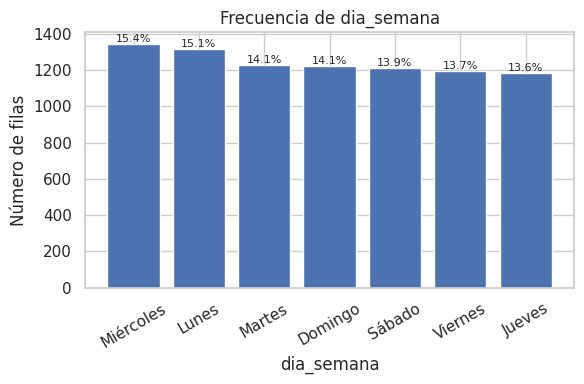

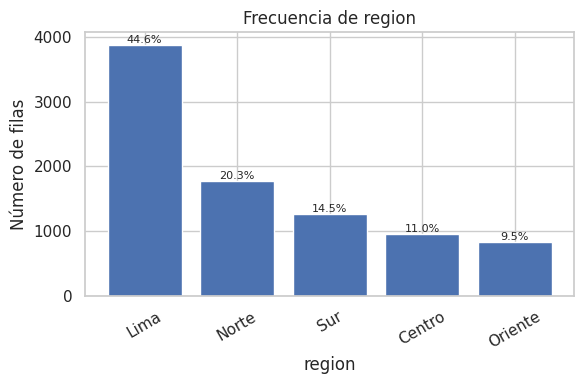

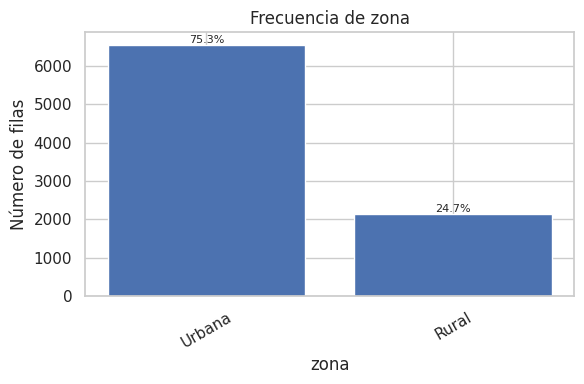

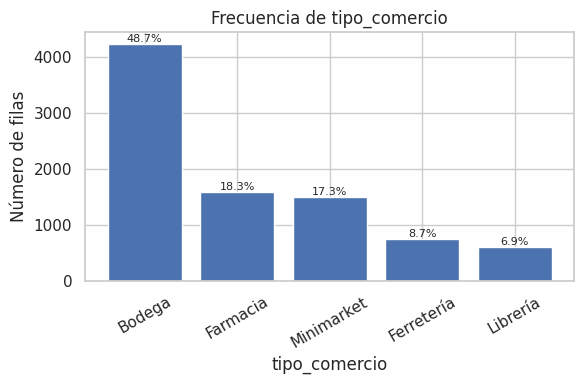

El gráfico circular se usa solo para un objetivo de clasificación.


In [26]:
# EJECUTAR

def resumen_frecuencias(datos, columnas):
    """Construye frecuencias y porcentajes de una o varias columnas categóricas.

    Parámetros:
        datos (DataFrame): base a describir; no se modifica.
        columnas (list): nombres categóricos, por ejemplo ["zona", "vehiculo"]. Una lista vacía
            muestra un mensaje y no calcula tablas.
    Retorna: diccionario columna -> DataFrame con Frecuencia y Porcentaje (%); incluye nulos.
    Ejemplo: resumen_frecuencias(df_limpio, columnas_categoricas_eda).
    """
    tablas = {}
    if not columnas:
        print("No hay columnas categóricas seleccionadas.")
    for columna in columnas:
        if columna not in datos:
            print(f"Se omite {columna}: no existe en la base.")
            continue
        frecuencia = datos[columna].value_counts(dropna=False)
        tablas[columna] = pd.DataFrame({"Frecuencia": frecuencia,
            "Porcentaje (%)": frecuencia.div(len(datos)).mul(100) if len(datos) else np.nan})
        print("Variable:", columna)
        display(tablas[columna].round(2))
    return tablas


def graficar_categoricas(datos, columnas, max_categorias=20):
    """Dibuja barras con frecuencia y porcentaje para variables categóricas.

    Parámetros:
        datos (DataFrame): base que contiene las variables; no se modifica.
        columnas (list): nombres categóricos que se desea graficar.
        max_categorias (int): máximo de categorías, incluidos nulos, por gráfico; por defecto 20.
            Si se supera, se informa y se puede aumentar este valor deliberadamente.
    Retorna: None. Muestra un gráfico por columna que tenga datos y no supere el límite.
    Ejemplo: graficar_categoricas(df_limpio, ["zona"], max_categorias=10).
    """
    if not columnas:
        print("No hay columnas categóricas para graficar.")
    for columna in columnas:
        if columna not in datos or datos.empty:
            print(f"Se omite {columna}: sin columna o sin filas.")
            continue
        frecuencia = datos[columna].value_counts(dropna=False)
        if len(frecuencia) > max_categorias:
            print(f"Se omite el gráfico de {columna}: {len(frecuencia)} categorías superan el límite {max_categorias}.")
            continue
        etiquetas = ["(Nulo)" if pd.isna(x) else str(x) for x in frecuencia.index]
        fig, ax = plt.subplots(figsize=(max(6, len(etiquetas) * 0.55), 4))
        barras = ax.bar(etiquetas, frecuencia.to_numpy())
        for barra, cuenta in zip(barras, frecuencia.to_numpy()):
            ax.annotate(f"{cuenta / len(datos) * 100:.1f}%", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                        ha="center", va="bottom", fontsize=8)
        ax.set(title=f"Frecuencia de {columna}", ylabel="Número de filas", xlabel=columna)
        ax.tick_params(axis="x", rotation=30)
        plt.tight_layout()
        plt.show()


def grafico_objetivo_categorico(datos, objetivo, tipo, max_categorias=10):
    """Muestra la distribución circular de un objetivo de clasificación.

    Parámetros:
        datos (DataFrame): base con el objetivo; no se modifica.
        objetivo (str): nombre de la columna objetivo categórica.
        tipo (str): "clasificacion" habilita el gráfico; otros tipos lo omiten.
        max_categorias (int): máximo de clases visibles; por defecto 10.
    Retorna: None; omite el gráfico si no corresponde o no hay valores.
    Ejemplo: grafico_objetivo_categorico(df_limpio, TARGET, TIPO_PROBLEMA).
    """
    if tipo != "clasificacion" or objetivo not in datos:
        print("El gráfico circular se usa solo para un objetivo de clasificación.")
        return
    conteo = datos[objetivo].value_counts(dropna=True)
    if conteo.empty or len(conteo) > max_categorias:
        print("Sin clases observadas o demasiadas clases para un gráfico circular.")
        return
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.pie(conteo.to_numpy(), labels=conteo.index.astype(str), autopct="%1.1f%%")
    ax.set_title(f"Distribución de {objetivo}")
    plt.tight_layout()
    plt.show()


tablas_frecuencias_eda = resumen_frecuencias(df_limpio, columnas_categoricas_eda)
graficar_categoricas(df_limpio, columnas_categoricas_eda, MAX_CATEGORIAS_EDA)
grafico_objetivo_categorico(df_limpio, TARGET, TIPO_PROBLEMA)

### 3.3.3 Descripción y distribución numérica · EJECUTAR

El histograma muestra la frecuencia; la línea marca la media y la curva de densidad se dibuja solo cuando hay suficientes valores distintos. El boxplot resume mediana y cuartiles. Un punto alejado es una señal para investigar, no una razón automática para eliminarlo.

,count,mean,std,min,25%,50%,75%,max
dia_mes,8688.0,15.786142,8.902673,1.0,8.0,16.0,24.00,31.0
dia_pago,8688.0,0.249309,0.432638,0.0,0.0,0.0,0.00,1.0
feriado,8688.0,0.042357,0.201415,0.0,0.0,0.0,0.00,1.0
antiguedad_meses,8688.0,32.205686,34.137075,1.0,16.0,32.0,47.00,999.0
horario_atencion_h,8688.0,11.866943,2.197725,8.0,10.0,12.0,14.00,16.0
transacciones_prom_7d,8688.0,16.071800,10.712621,1.9,8.6,13.5,20.30,90.7
retiros_prom_7d,8688.0,1876.030041,1247.682687,232.0,1004.0,1578.0,2364.25,10188.0
monto_retiros,8688.0,1976.164710,1576.716678,0.0,928.0,1583.0,2548.00,21614.0


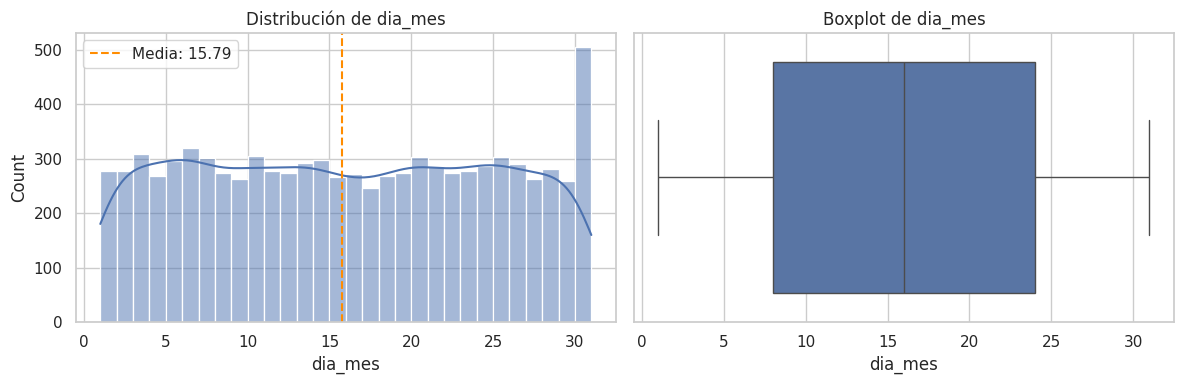

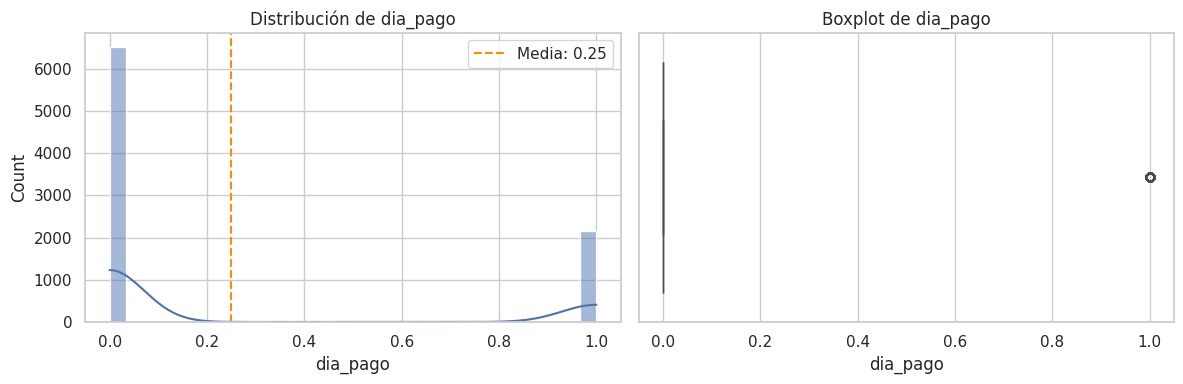

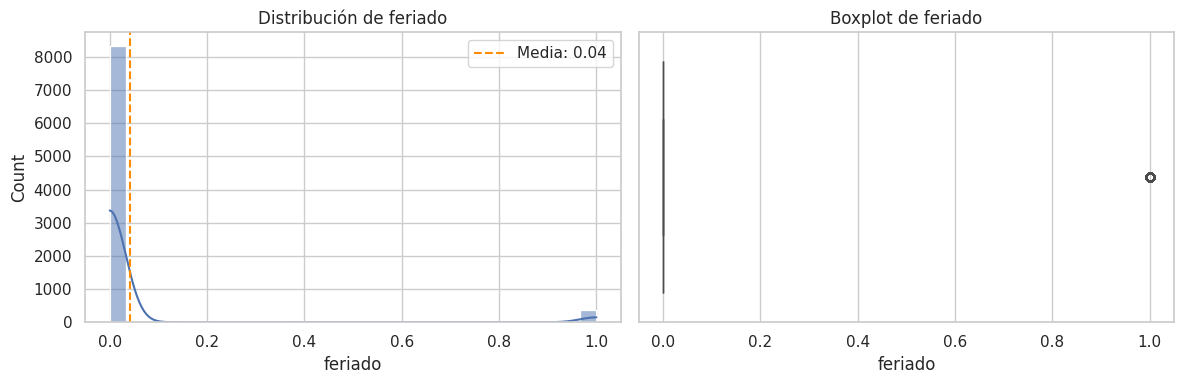

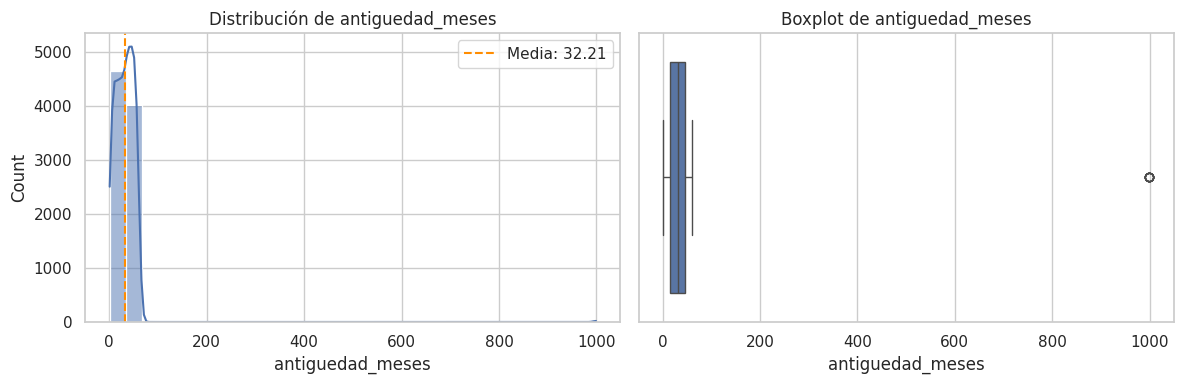

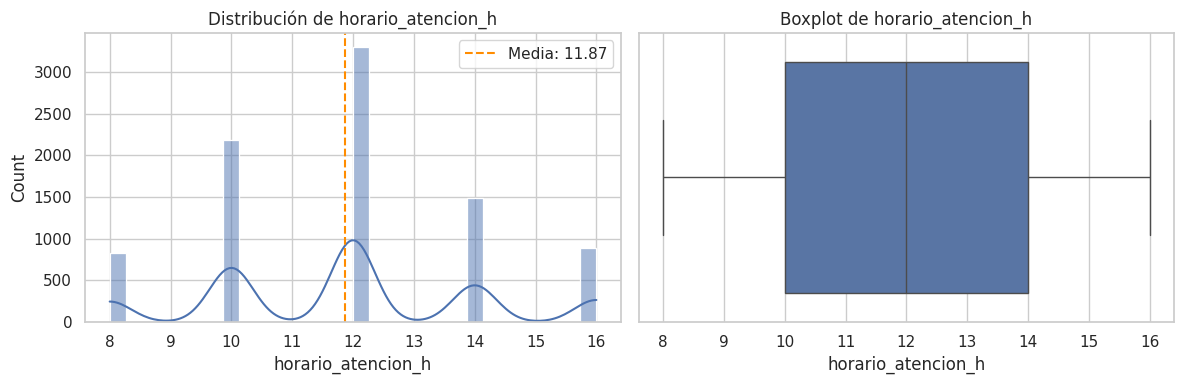

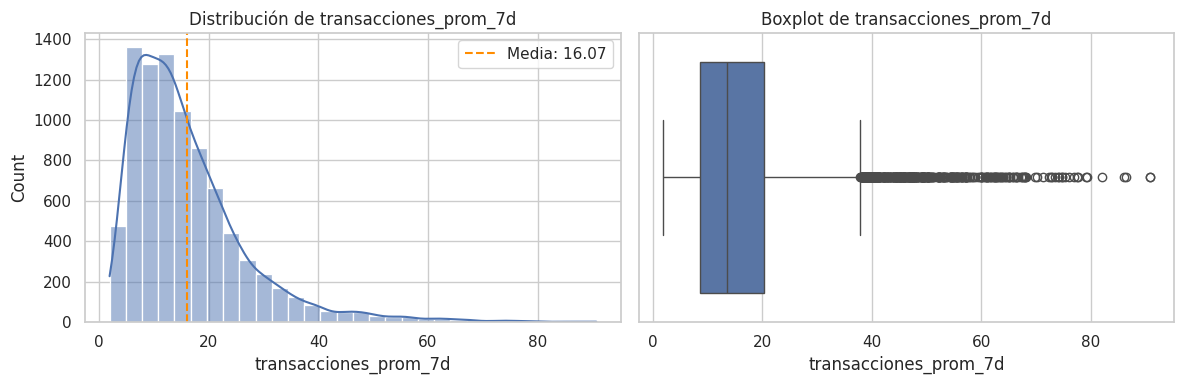

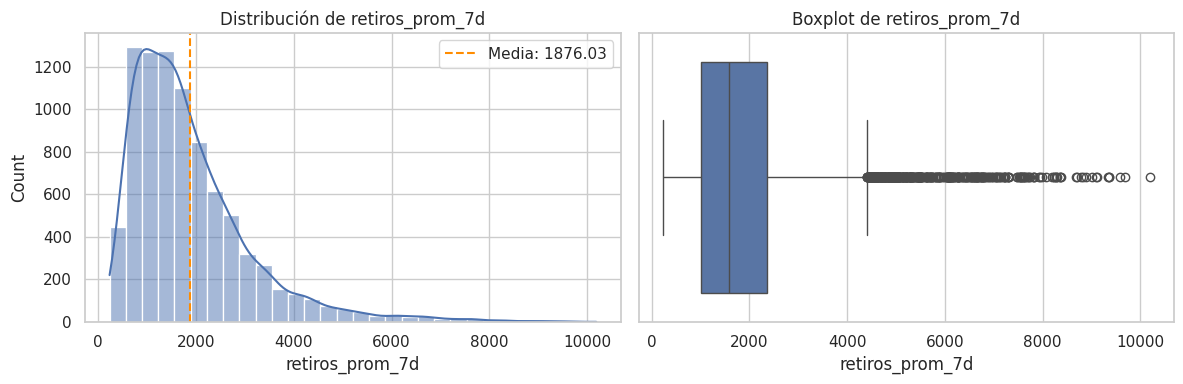

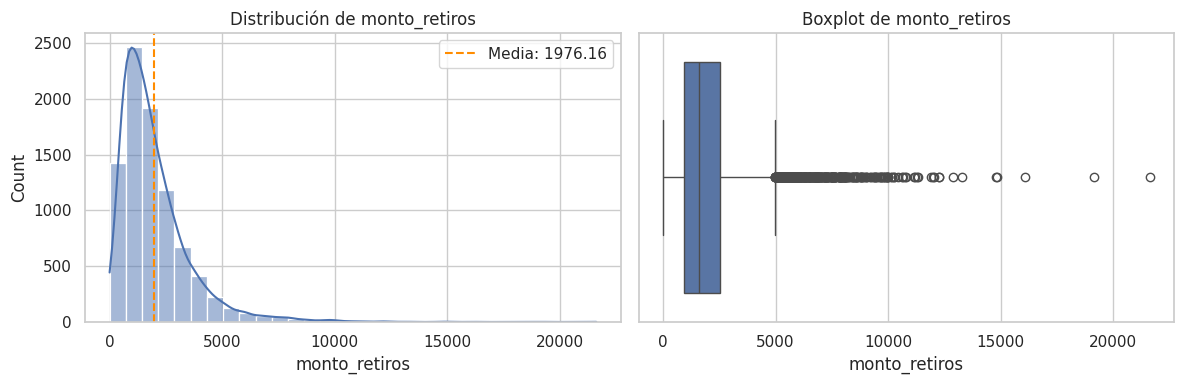

In [27]:
# EJECUTAR

def graficar_numericas(datos, columnas, bins=30):
    """Muestra estadísticas, histograma con media y boxplot de cantidades.

    Parámetros:
        datos (DataFrame): tabla que contiene las columnas; no se modifica.
        columnas (list): nombres de cantidades que se desean analizar.
        bins (int): número de intervalos del histograma; por defecto 30. Más intervalos
            dan más detalle; menos intervalos agrupan más los valores.
    Retorna: DataFrame de estadísticos por variable; muestra gráficos y explica omisiones.
    Ejemplo: graficar_numericas(df_limpio, ["edad", "ventas"], bins=30).
    """
    disponibles = [c for c in columnas if c in datos and pd.api.types.is_numeric_dtype(datos[c])]
    if not disponibles:
        print("No hay columnas numéricas para describir.")
        return pd.DataFrame()
    descripcion = datos[disponibles].describe().T
    display(descripcion)
    for columna in disponibles:
        valores = pd.to_numeric(datos[columna], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if valores.empty:
            print(f"Se omite {columna}: no tiene valores numéricos finitos.")
            continue
        fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
        sns.histplot(valores, bins=bins, kde=len(valores) >= 3 and valores.nunique() >= 2, ax=ejes[0])
        ejes[0].axvline(valores.mean(), color="darkorange", linestyle="--", label=f"Media: {valores.mean():.2f}")
        ejes[0].set_title(f"Distribución de {columna}")
        ejes[0].legend()
        sns.boxplot(x=valores, ax=ejes[1])
        ejes[1].set_title(f"Boxplot de {columna}")
        plt.tight_layout()
        plt.show()
    return descripcion


descripcion_numerica_eda = graficar_numericas(df_limpio, columnas_numericas_eda)

### 3.3.3a Boxplots individuales en cuadrícula · EJECUTAR

Además de los boxplots que acompañan a los histogramas, esta celda muestra una cuadrícula con un gráfico vertical por variable numérica. La línea de la caja es la mediana; sus extremos son los cuartiles 25 y 75. Los bigotes llegan a los valores observados dentro de 1.5 veces el rango entre cuartiles; los puntos exteriores son **posibles valores extremos**, no necesariamente errores.

Por defecto se muestran las primeras seis cantidades detectadas, cada una con su propia escala. Si necesitas otras, cambia la lista de la última línea, por ejemplo a ["edad", "ingreso", TARGET]. No se cambia ni se elimina ningún dato.

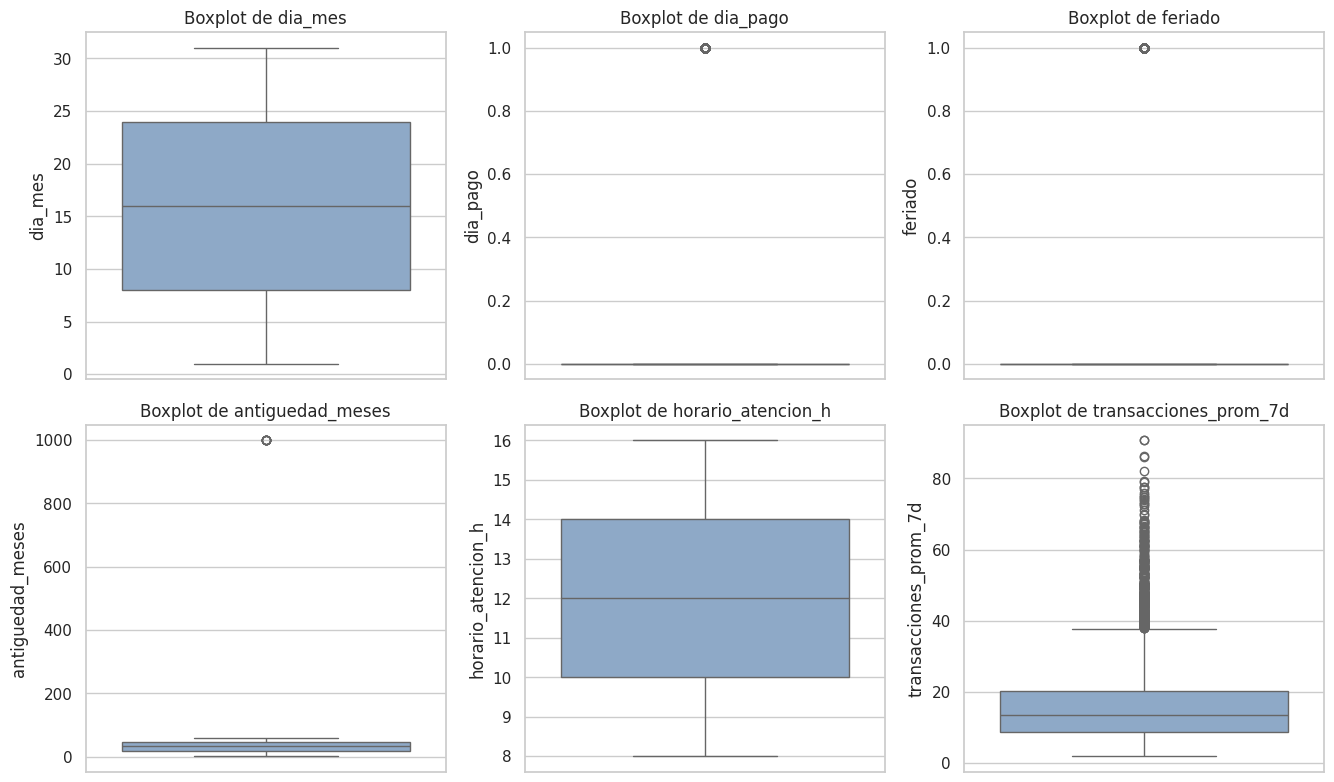

,Conteo,Q1,Mediana,Q3,Posibles_extremos
Variable,,,,,
dia_mes,8688,8.0,16.0,24.0,0
dia_pago,8688,0.0,0.0,0.0,2166
feriado,8688,0.0,0.0,0.0,368
antiguedad_meses,8688,16.0,32.0,47.0,8
horario_atencion_h,8688,10.0,12.0,14.0,0
transacciones_prom_7d,8688,8.6,13.5,20.3,385


In [28]:
# EJECUTAR · Puedes cambiar la selección de variables en la última línea.
def boxplots_individuales(datos, columnas, n_columnas=3, mostrar_atipicos=True):
    """Compara distribuciones individuales mediante una cuadrícula de boxplots.

    Parámetros:
        datos (DataFrame): base con las variables que deseas revisar; no se modifica.
        columnas (list): nombres de las columnas numéricas, por ejemplo ["edad", "ventas"].
            Cada una tendrá su propio eje y escala; se omiten columnas sin valores numéricos finitos.
        n_columnas (int): cantidad de gráficos por fila de la cuadrícula; por defecto 3.
        mostrar_atipicos (bool): True, por defecto, dibuja los puntos fuera de los bigotes;
            False los oculta únicamente en el gráfico, sin eliminarlos de la base.
    Retorna: DataFrame con conteo, Q1, mediana, Q3 y número de posibles extremos por variable.
        Muestra también los boxplots; si no hay cantidades válidas, devuelve una tabla vacía.
    Ejemplo: boxplots_individuales(df_limpio, ["edad", TARGET], n_columnas=2).
    """
    if isinstance(n_columnas, bool) or not isinstance(n_columnas, int) or n_columnas < 1:
        raise ValueError("n_columnas debe ser un entero positivo.")
    disponibles = [c for c in dict.fromkeys(columnas) if c in datos and pd.api.types.is_numeric_dtype(datos[c])]
    muestras = {}
    for columna in disponibles:
        valores = pd.to_numeric(datos[columna], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if valores.empty:
            print(f"Se omite {columna}: no tiene valores numéricos finitos.")
        else:
            muestras[columna] = valores
    if not muestras:
        print("No hay cantidades válidas para los boxplots individuales.")
        return pd.DataFrame()
    cantidad = len(muestras)
    columnas_figura = min(n_columnas, cantidad)
    filas_figura = (cantidad + columnas_figura - 1) // columnas_figura
    fig, ejes = plt.subplots(filas_figura, columnas_figura, figsize=(4.5 * columnas_figura, 4 * filas_figura), squeeze=False)
    resumen = []
    for ax, (columna, valores) in zip(ejes.flat, muestras.items()):
        q1, mediana, q3 = valores.quantile([0.25, 0.5, 0.75])
        rango = q3 - q1
        extremos = ((valores < q1 - 1.5 * rango) | (valores > q3 + 1.5 * rango)).sum()
        sns.boxplot(y=valores, ax=ax, showfliers=mostrar_atipicos, color="#84a9d1")
        ax.set(title=f"Boxplot de {columna}", ylabel=columna)
        resumen.append({"Variable": columna, "Conteo": len(valores), "Q1": q1, "Mediana": mediana,
                        "Q3": q3, "Posibles_extremos": int(extremos)})
    for ax in list(ejes.flat)[cantidad:]:
        fig.delaxes(ax)
    plt.tight_layout()
    plt.show()
    tabla = pd.DataFrame(resumen).set_index("Variable")
    display(tabla.round(3))
    return tabla


boxplots_univariados_eda = boxplots_individuales(df_limpio, columnas_numericas_eda[:6], n_columnas=3, mostrar_atipicos=True)

### 3.3.4 Valores extremos · EJECUTAR

Para orientar la revisión se muestran cuartiles, rango intercuartílico y cantidad de observaciones fuera de los límites habituales de 1.5 veces ese rango. Como en agentes, distingue errores de registro de eventos reales. Esta celda no modifica ni elimina observaciones.

In [29]:
# EJECUTAR

def resumen_extremos(datos, columnas):
    """Cuenta valores potencialmente extremos mediante cuartiles, sin eliminarlos.

    Parámetros:
        datos (DataFrame): base numérica a revisar; se conserva sin cambios.
        columnas (list): nombres de cantidades que se desean revisar.
    Retorna: DataFrame con Q1, mediana, Q3, rango intercuartílico, límites y número fuera
        de esos límites. Una alerta estadística no determina si el valor es un error.
    Ejemplo: resumen_extremos(df_limpio, ["monto_retiros"]).
    """
    filas = []
    for columna in columnas:
        if columna not in datos or not pd.api.types.is_numeric_dtype(datos[columna]):
            continue
        valores = pd.to_numeric(datos[columna], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if valores.empty:
            continue
        q1, mediana, q3 = valores.quantile([0.25, 0.5, 0.75])
        rango = q3 - q1
        inferior, superior = q1 - 1.5 * rango, q3 + 1.5 * rango
        filas.append({"Variable": columna, "Q1": q1, "Mediana": mediana, "Q3": q3,
                      "Rango_IQR": rango, "Limite_inferior": inferior, "Limite_superior": superior,
                      "Fuera_limites": int(((valores < inferior) | (valores > superior)).sum())})
    if not filas:
        print("No hay cantidades válidas para revisar extremos.")
        return pd.DataFrame()
    tabla = pd.DataFrame(filas).set_index("Variable")
    display(tabla.round(3))
    return tabla


tabla_extremos_eda = resumen_extremos(df_limpio, columnas_numericas_eda)

,Q1,Mediana,Q3,Rango_IQR,Limite_inferior,Limite_superior,Fuera_limites
Variable,,,,,,,
dia_mes,8.0,16.0,24.00,16.00,-16.000,48.000,0
dia_pago,0.0,0.0,0.00,0.00,0.000,0.000,2166
feriado,0.0,0.0,0.00,0.00,0.000,0.000,368
antiguedad_meses,16.0,32.0,47.00,31.00,-30.500,93.500,8
horario_atencion_h,10.0,12.0,14.00,4.00,4.000,20.000,0
transacciones_prom_7d,8.6,13.5,20.30,11.70,-8.950,37.850,385
retiros_prom_7d,1004.0,1578.0,2364.25,1360.25,-1036.375,4404.625,389
monto_retiros,928.0,1583.0,2548.00,1620.00,-1502.000,4978.000,412


### Herramienta para resumir meses · EJECUTAR

La siguiente función se usa tanto en el análisis histórico de series como más adelante en el reporte del pronóstico. Mantiene el conteo de periodos esperados y señala los meses parciales.

In [30]:
# EJECUTAR
def resumir_mensual(serie, frecuencia, agregacion):
    """Resume una serie por mes, mostrando cobertura y si cada mes está completo.

    Parámetros:
        serie (Series): valores numéricos con índice DatetimeIndex sin fechas duplicadas.
        frecuencia (str): frecuencia original, por ejemplo 'D', 'W-MON' o 'MS'.
        agregacion (str): 'sum' suma cantidades acumulables; 'mean' promedia niveles.
    Retorna: DataFrame por mes con valor, periodos observados/esperados, cobertura y mes_completo.
        Los meses incompletos no se extrapolan ni se rellenan los huecos.
    Ejemplo: resumir_mensual(serie, 'D', 'sum').
    """
    if agregacion not in {"sum", "mean"}:
        raise ValueError("La agregación mensual debe ser sum o mean.")
    if serie.empty or not isinstance(serie.index, pd.DatetimeIndex) or not serie.index.is_unique or serie.index.hasnans:
        raise ValueError("El resumen mensual requiere fechas únicas y no vacías.")
    ordenada = serie.sort_index()
    inicio_mes = ordenada.index[0].to_period("M").start_time
    fin_mes = ordenada.index[-1].to_period("M").end_time
    # Extiende la misma cuadrícula en ambas direcciones para medir meses parciales.
    desplazamiento = pd.tseries.frequencies.to_offset(frecuencia)
    if isinstance(desplazamiento, pd.tseries.offsets.Tick):
        inicio_alineado = ordenada.index[0] - ((ordenada.index[0] - inicio_mes) // pd.Timedelta(desplazamiento)) * desplazamiento
        anteriores = pd.date_range(start=inicio_alineado, end=ordenada.index[0], freq=frecuencia)
    else:
        anteriores_amplias = pd.date_range(end=ordenada.index[0], periods=32, freq=frecuencia)
        anteriores = anteriores_amplias[anteriores_amplias >= inicio_mes]
    posteriores = pd.date_range(start=ordenada.index[0], end=fin_mes, freq=frecuencia)
    esperadas = anteriores.union(posteriores)
    if len(ordenada.index.difference(esperadas)):
        raise ValueError("Las fechas del resumen no coinciden con la frecuencia declarada.")
    meses = pd.period_range(inicio_mes, fin_mes, freq="M")
    grupos = ordenada.groupby(ordenada.index.to_period("M"))
    valores = grupos.sum(min_count=1) if agregacion == "sum" else grupos.mean()
    conteo_esperado = pd.Series(1, index=esperadas).groupby(esperadas.to_period("M")).sum()
    resumen = pd.DataFrame({"valor": valores, "periodos_observados": grupos.count(),
        "periodos_esperados": conteo_esperado}).reindex(meses)
    conteos = resumen.assign(periodos_observados=resumen["periodos_observados"].fillna(0).astype(int),
        periodos_esperados=resumen["periodos_esperados"].fillna(0).astype(int))
    return conteos.assign(cobertura_pct=conteos["periodos_observados"].div(conteos["periodos_esperados"].replace(0, np.nan)).mul(100),
        mes_completo=conteos["periodos_observados"].eq(conteos["periodos_esperados"]) & conteos["periodos_esperados"].gt(0)).rename_axis("mes")

### 3.3.5 Serie histórica · EJECUTAR SI ES SERIE

Como en los casos de recaudación, muestra fecha inicial y final, número de observaciones, evolución de TARGET y media móvil. La tabla mensual indica valor agregado, cobertura, meses completos y variación porcentual. En la llamada usa agregacion="sum" para cantidades acumulables, como transacciones, o "mean" para niveles, como precios.

La variación mensual solo se calcula entre meses completos y cuando el mes anterior es distinto de cero; para meses parciales se deja vacía.

In [31]:
# EJECUTAR · Se omite automáticamente si el caso no es de series.
def analizar_serie_historica(datos, fecha, objetivo, frecuencia, ventana=7, agregacion="sum"):
    """Describe y grafica una serie histórica y devuelve su resumen mensual.

    Parámetros:
        datos (DataFrame): base que contiene fecha y objetivo; no se modifica.
        fecha (str): columna que indica el momento de cada observación.
        objetivo (str): columna numérica con el valor observado en cada periodo.
        frecuencia (str): periodicidad original, por ejemplo "D", "W-MON" o "MS".
        ventana (int): cantidad de periodos de la media móvil descriptiva; por defecto 7.
            La media de este gráfico incluye el valor actual porque solo describe el pasado.
        agregacion (str): "sum" para cantidades acumulables o "mean" para niveles; por defecto "sum".
    Retorna: DataFrame mensual con valor, cobertura, mes completo y variación porcentual.
    Ejemplo: analizar_serie_historica(df_limpio, FECHA, TARGET, "D", 7, "sum").
    """
    if fecha not in datos or objetivo not in datos or datos.empty:
        print("No hay columnas de fecha y objetivo suficientes para analizar la serie.")
        return pd.DataFrame()
    if not isinstance(ventana, int) or isinstance(ventana, bool) or ventana < 1:
        raise ValueError("La ventana debe ser un entero positivo.")
    fechas = pd.to_datetime(datos[fecha], errors="coerce")
    valores = pd.to_numeric(datos[objetivo], errors="coerce")
    validas = fechas.notna() & valores.notna() & np.isfinite(valores)
    if not validas.any():
        print("No hay fechas y valores numéricos válidos para la serie.")
        return pd.DataFrame()
    serie_hist = pd.Series(valores.loc[validas].to_numpy(), index=pd.DatetimeIndex(fechas.loc[validas])).sort_index()
    if not serie_hist.index.is_unique:
        print("Se omite el análisis temporal: hay fechas duplicadas; resuélvelas en limpieza.")
        return pd.DataFrame()
    print("Inicio:", serie_hist.index.min(), "| fin:", serie_hist.index.max(),
          "| observaciones:", len(serie_hist), "| filas omitidas:", int((~validas).sum()))
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(serie_hist.index, serie_hist.to_numpy(), label="Valor real")
    ax.plot(serie_hist.index, serie_hist.rolling(ventana, min_periods=1).mean().to_numpy(), "--", label=f"Media móvil ({ventana})")
    ax.set(title="Serie histórica", xlabel=fecha, ylabel=objetivo)
    ax.legend()
    plt.tight_layout()
    plt.show()
    try:
        mensual = resumir_mensual(serie_hist, frecuencia, agregacion)
    except ValueError as error:
        print("No se generó el resumen mensual:", error)
        return pd.DataFrame()
    mensual_con_variacion = mensual.assign(variacion_mensual_pct=mensual["valor"].div(mensual["valor"].shift(1).replace(0, np.nan)).sub(1).mul(100).where(mensual["mes_completo"] & mensual["mes_completo"].shift(1, fill_value=False)))
    print("Meses:", len(mensual_con_variacion), "| meses completos:", int(mensual_con_variacion["mes_completo"].sum()))
    display(mensual_con_variacion)
    return mensual_con_variacion


if TIPO_PROBLEMA == "serie_tiempo":
    resumen_serie_historica = analizar_serie_historica(df_limpio, FECHA, TARGET, FRECUENCIA, VENTANA, "sum")
else:
    print("El análisis temporal se usa solo para series de tiempo.")

El análisis temporal se usa solo para series de tiempo.


### 3.3.6 Estacionalidad semanal · EJECUTAR SI ES SERIE

La práctica de agentes compara el promedio de cada día de la semana contra el promedio general. Esta celda prepara una tabla nueva con conteo, media, mediana y esa relación; una razón 1.2 equivale a un promedio 20 % mayor que el general. Se aplica a series diarias con fechas válidas.

In [32]:
# EJECUTAR · Se omite automáticamente si el caso no es de series diarias.
def analizar_dia_semana(datos, fecha, objetivo):
    """Compara la cantidad observada según el día de la semana.

    Parámetros:
        datos (DataFrame): base histórica que contiene fechas y una cantidad; no se modifica.
        fecha (str): nombre de la columna de fecha.
        objetivo (str): nombre de la columna numérica a comparar.
    Retorna: DataFrame con conteo, media, mediana e índice frente al promedio general;
        muestra barras con una línea de referencia en 1.
    Ejemplo: analizar_dia_semana(df_limpio, FECHA, TARGET).
    """
    if fecha not in datos or objetivo not in datos or not pd.api.types.is_numeric_dtype(datos[objetivo]):
        print("Se necesitan una fecha y un objetivo numérico para comparar días.")
        return pd.DataFrame()
    fechas = pd.to_datetime(datos[fecha], errors="coerce")
    valores = pd.to_numeric(datos[objetivo], errors="coerce").replace([np.inf, -np.inf], np.nan)
    validas = fechas.notna() & valores.notna()
    if not validas.any():
        print("No hay fechas y valores válidos para comparar días.")
        return pd.DataFrame()
    nombres = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
    dias = pd.Series(fechas.loc[validas].dt.dayofweek.to_numpy(), name="dia")
    valores_validos = pd.Series(valores.loc[validas].to_numpy(), name="valor")
    observaciones = pd.DataFrame({"dia": dias, "valor": valores_validos})
    tabla_base = observaciones.groupby("dia")["valor"].agg(["count", "mean", "median"]).reindex(range(7))
    promedio_global = observaciones["valor"].mean()
    tabla = tabla_base.assign(indice_vs_global=tabla_base["mean"] / promedio_global if promedio_global != 0 else np.nan)
    tabla.index = nombres
    display(tabla.round(3))
    if tabla["indice_vs_global"].notna().any():
        ax = tabla["indice_vs_global"].plot.bar(figsize=(9, 4), title=f"{objetivo}: promedio por día / promedio global")
        ax.axhline(1, color="darkorange", linestyle="--", label="Promedio global")
        ax.set_ylabel("Razón respecto del promedio")
        ax.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("El promedio global es cero: no se puede calcular el índice relativo.")
    return tabla


if TIPO_PROBLEMA == "serie_tiempo" and FRECUENCIA == "D":
    dias_semana_eda = analizar_dia_semana(df_limpio, FECHA, TARGET)
else:
    print("El análisis por día de semana se usa para series diarias.")

El análisis por día de semana se usa para series diarias.


## 3.4 Análisis bivariado y multivariado

Estas celdas exploran relaciones entre dos o más variables. La guía selecciona automáticamente ejemplos disponibles y cada llamada puede modificarse. Las tasas de eventos se usan solamente en clasificación binaria y requieren especificar CLASE_POSITIVA.

### 3.4.1 Relaciones entre cantidades · EJECUTAR

La dispersión permite examinar si dos valores cambian juntos y dónde aparecen posibles patrones o casos extremos. Para no ocupar demasiado tiempo se grafican hasta tres predictores frente al objetivo numérico; cambia la selección en la última línea si el enunciado pide otros.

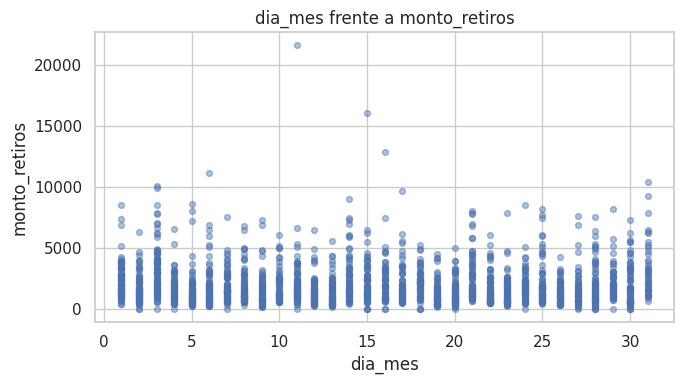

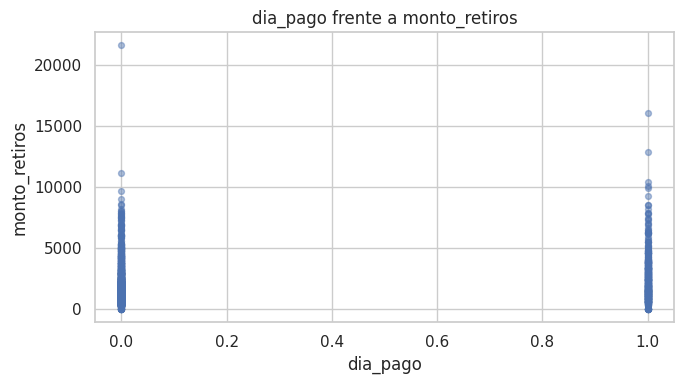

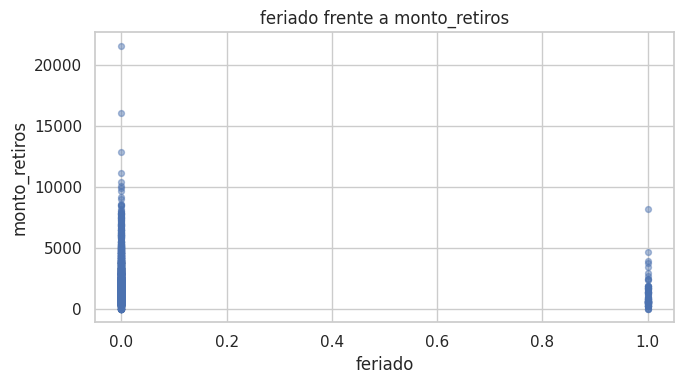

In [34]:
# EJECUTAR

def comparar_numericas(datos, columnas, objetivo, muestra=2000, semilla=42):
    """Dibuja dispersiones de cantidades frente a un objetivo numérico.

    Parámetros:
        datos (DataFrame): base de exploración; se conserva sin modificar.
        columnas (list): columnas numéricas que se compararán con el objetivo.
        objetivo (str): nombre de la respuesta numérica en el eje vertical.
        muestra (int): máximo de filas por gráfico; por defecto 2000. Se usan todas si hay menos.
        semilla (int): fija la muestra aleatoria; por defecto 42.
    Retorna: None. Informa cuándo no hay columnas o pares válidos.
    Ejemplo: comparar_numericas(df_limpio, ["distancia_km"], TARGET, 2000, SEMILLA).
    """
    if objetivo not in datos or not pd.api.types.is_numeric_dtype(datos[objetivo]):
        print("La dispersión necesita un objetivo numérico.")
        return
    elegidas = [c for c in columnas if c in datos and c != objetivo and pd.api.types.is_numeric_dtype(datos[c])]
    if not elegidas:
        print("No hay predictores numéricos para comparar con el objetivo.")
    for columna in elegidas:
        pares = datos[[columna, objetivo]].replace([np.inf, -np.inf], np.nan).dropna()
        if pares.empty:
            print(f"Se omite {columna}: no hay pares válidos.")
            continue
        puntos = pares.sample(n=min(muestra, len(pares)), random_state=semilla)
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.scatter(puntos[columna], puntos[objetivo], alpha=0.45, s=18)
        ax.set(xlabel=columna, ylabel=objetivo, title=f"{columna} frente a {objetivo}")
        plt.tight_layout()
        plt.show()


if TIPO_PROBLEMA in {"regresion", "serie_tiempo"}:
    comparar_numericas(df_limpio, [c for c in columnas_numericas_eda if c != TARGET][:3], TARGET, 2000, SEMILLA)
else:
    print("Para clasificación usa las comparaciones por clase de las siguientes celdas.")

### 3.4.2 Cantidad por categoría · EJECUTAR

La tabla y los gráficos comparan cantidad, media, mediana y suma del valor numérico entre categorías. El boxplot muestra la distribución y las barras muestran el promedio. Se presentan hasta tres categorías detectadas; el ejemplo se puede adaptar a una columna concreta.

,count,mean,median,sum
dia_semana,,,,
Domingo,1223,958.372,736.0,1172089.0
Jueves,1183,1971.936,1594.0,2332800.0
Lunes,1313,2457.014,1962.0,3226059.0
Martes,1227,2048.029,1672.0,2512932.0
Miércoles,1340,2078.800,1699.0,2785592.0
Sábado,1208,1935.205,1550.0,2337728.0
Viernes,1194,2346.498,1952.5,2801719.0


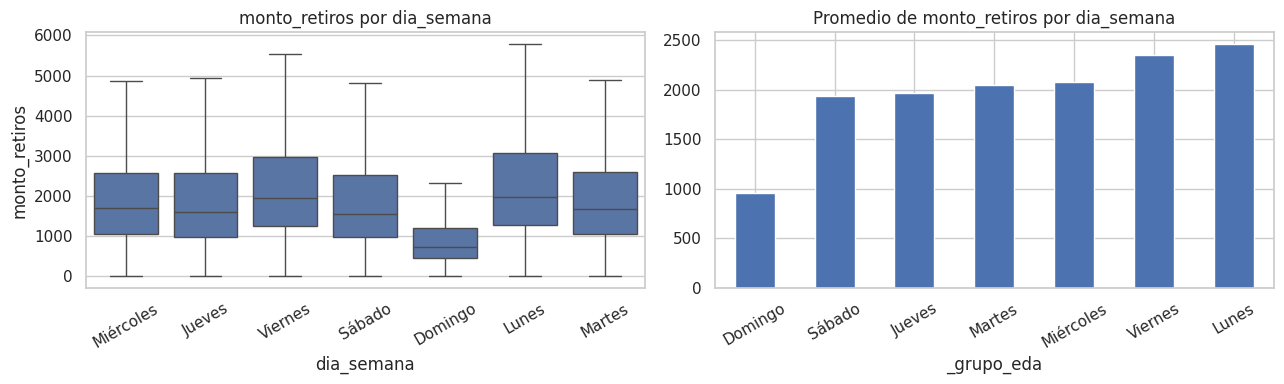

,count,mean,median,sum
region,,,,
Centro,957,1895.010,1658.0,1813525.0
Lima,3877,2050.908,1660.0,7951371.0
Norte,1768,1872.497,1457.0,3310575.0
Oriente,828,1904.636,1534.5,1577039.0
Sur,1258,2000.325,1460.5,2516409.0


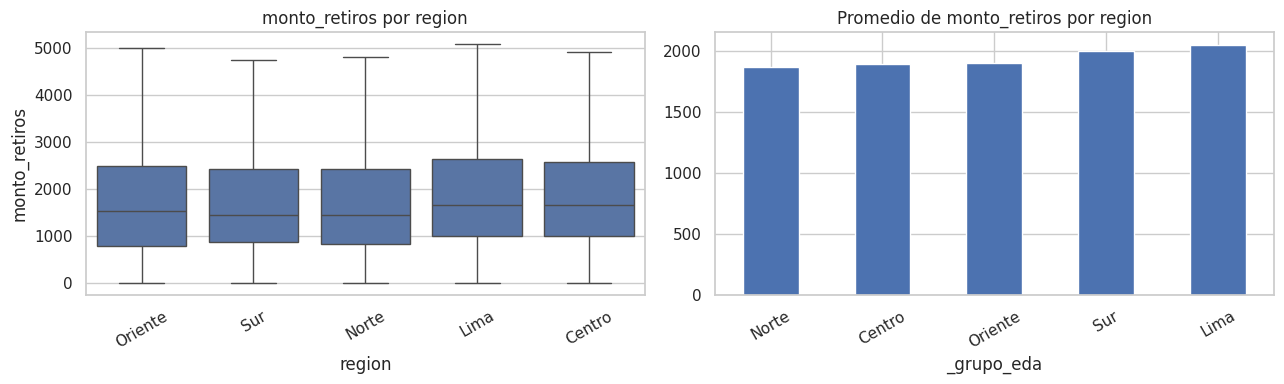

,count,mean,median,sum
zona,,,,
Rural,2147,1600.993,1259.0,3437333.0
Urbana,6541,2099.310,1710.0,13731586.0


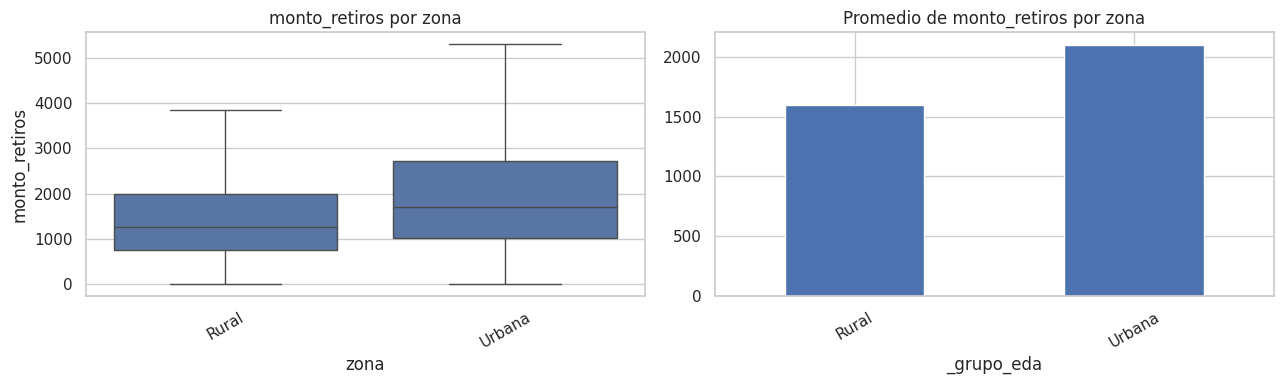

In [35]:
# EJECUTAR

def comparar_por_categoria(datos, categoria, numerica, max_categorias=20):
    """Resume y grafica una cantidad para cada categoría.

    Parámetros:
        datos (DataFrame): base que contiene ambas columnas; no se modifica.
        categoria (str): columna con grupos, por ejemplo "zona".
        numerica (str): cantidad a comparar, por ejemplo el TARGET de regresión.
        max_categorias (int): máximo de grupos para los gráficos; por defecto 20.
    Retorna: DataFrame con conteo, media, mediana y suma por grupo; muestra boxplot y barras.
    Ejemplo: comparar_por_categoria(df_limpio, "zona", TARGET).
    """
    if categoria not in datos or numerica not in datos or not pd.api.types.is_numeric_dtype(datos[numerica]):
        print("Se necesitan una categoría y una columna numérica existentes.")
        return pd.DataFrame()
    pares = datos[[categoria, numerica]].replace([np.inf, -np.inf], np.nan).dropna(subset=[numerica]).copy()
    if pares.empty:
        print("No hay cantidades válidas para agrupar.")
        return pd.DataFrame()
    tabla = pares.groupby(categoria, dropna=False, observed=True)[numerica].agg(["count", "mean", "median", "sum"])
    display(tabla.round(3))
    if len(tabla) > max_categorias:
        print(f"Se omiten gráficos de {categoria}: {len(tabla)} grupos superan el límite {max_categorias}.")
        return tabla
    # Etiquetas de visualización separadas para incluir nulos sin modificar la base original.
    pares_grafico = pares.assign(_grupo_eda=pares[categoria].astype(object).where(pares[categoria].notna(), "(Nulo)").astype(str))
    fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
    sns.boxplot(data=pares_grafico, x="_grupo_eda", y=numerica, showfliers=False, ax=ejes[0])
    ejes[0].set(xlabel=categoria, title=f"{numerica} por {categoria}")
    tabla_grafico = pares_grafico.groupby("_grupo_eda", dropna=False)[numerica].mean().sort_values()
    tabla_grafico.plot.bar(ax=ejes[1], title=f"Promedio de {numerica} por {categoria}")
    for ax in ejes:
        ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()
    return tabla


if TIPO_PROBLEMA in {"regresion", "serie_tiempo"}:
    categorias_comparables = [c for c in columnas_categoricas_eda if c != TARGET][:3]
    if not categorias_comparables:
        print("No hay categorías para comparar con el objetivo numérico.")
    for variable_categoria in categorias_comparables:
        comparar_por_categoria(df_limpio, variable_categoria, TARGET, MAX_CATEGORIAS_EDA)
else:
    print("El objetivo de clasificación se compara con cantidades en la siguiente celda.")

### 3.4.2a Boxplots de varias cantidades por grupo · EJECUTAR

Esta celda añade una cuadrícula de boxplots para comparar hasta tres cantidades entre las categorías de un grupo. En clasificación usa las clases de TARGET; en regresión usa la primera categoría adecuada. Para una serie diaria sin categorías, construye una columna temporal con el día de la semana **en una copia**, para comparar el objetivo entre días.

Los puntos fuera de los bigotes son posibles extremos; no se eliminan. Cambia las variables de la última llamada o indica un segundo grupo en SEGUNDO_GRUPO_BOXPLOT si necesitas comparar, por ejemplo, montos por zona y día de pago.

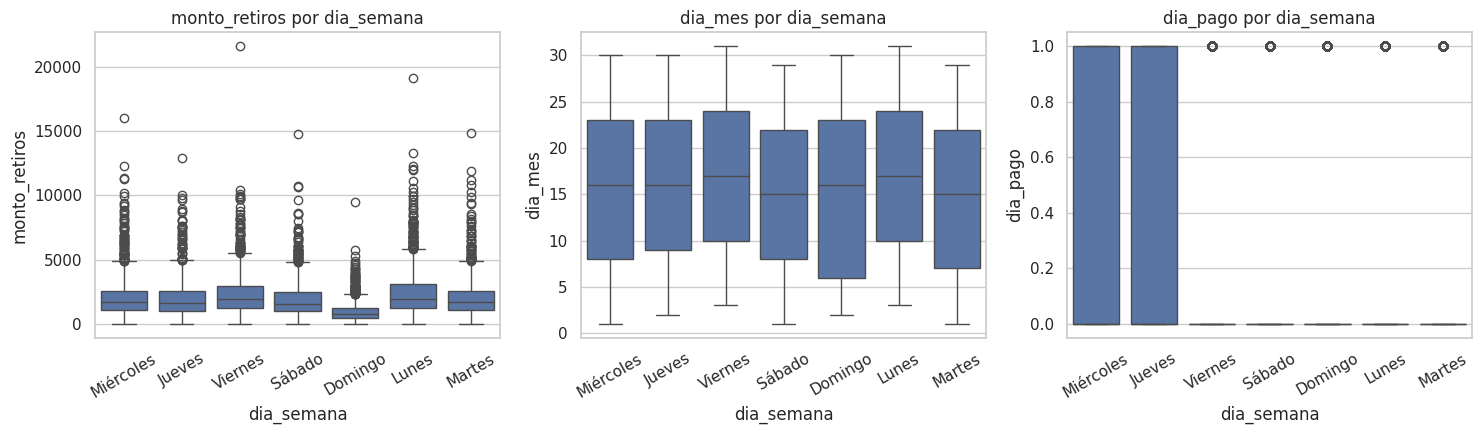

,dia_semana,count,mean,median,variable
0,Domingo,1223,958.372,736.0,monto_retiros
1,Jueves,1183,1971.936,1594.0,monto_retiros
2,Lunes,1313,2457.014,1962.0,monto_retiros
3,Martes,1227,2048.029,1672.0,monto_retiros
4,Miércoles,1340,2078.800,1699.0,monto_retiros
5,Sábado,1208,1935.205,1550.0,monto_retiros
6,Viernes,1194,2346.498,1952.5,monto_retiros
7,Domingo,1223,15.818,16.0,dia_mes
8,Jueves,1183,15.496,16.0,dia_mes
9,Lunes,1313,16.699,17.0,dia_mes


In [36]:
# EJECUTAR · OPCIONAL: indica una segunda categoría para distinguirla con colores.
SEGUNDO_GRUPO_BOXPLOT = None  # Ejemplo: "dia_pago"; None muestra un solo grupo

def boxplots_por_grupo(datos, columnas, grupo, subgrupo=None, max_categorias=20, mostrar_atipicos=True):
    """Compara varias cantidades mediante boxplots por categoría y subgrupo opcional.

    Parámetros:
        datos (DataFrame): base que contiene las variables y los grupos; no se modifica.
        columnas (list): cantidades numéricas a comparar, por ejemplo ["edad", "ingreso"].
            Se muestra un panel independiente y con su propia escala para cada cantidad válida.
        grupo (str): columna con las categorías del eje horizontal, por ejemplo "zona".
        subgrupo (str o None): segunda columna categórica que se distingue por colores;
            por defecto None no divide cada categoría en colores adicionales.
        max_categorias (int): número máximo de categorías permitido por cada grupo; por defecto 20.
        mostrar_atipicos (bool): True, por defecto, muestra los puntos fuera de los bigotes;
            False los oculta solo del gráfico, sin eliminarlos de los datos.
    Retorna: DataFrame con conteo, media y mediana por variable y grupo. Devuelve una tabla vacía
        con un mensaje si no hay columnas o filas válidas para comparar.
    Ejemplo: boxplots_por_grupo(df_limpio, [TARGET], "zona", subgrupo="dia_pago").
    """
    if grupo not in datos or (subgrupo is not None and subgrupo not in datos):
        print("Indica columnas existentes para el grupo y, si corresponde, el subgrupo.")
        return pd.DataFrame()
    if subgrupo == grupo:
        print("El subgrupo debe ser diferente del grupo principal.")
        return pd.DataFrame()
    if datos[grupo].nunique(dropna=False) > max_categorias or (subgrupo is not None and datos[subgrupo].nunique(dropna=False) > max_categorias):
        print("Se omiten los boxplots: hay más categorías que el límite configurado.")
        return pd.DataFrame()
    disponibles = [c for c in dict.fromkeys(columnas) if c in datos and c not in {grupo, subgrupo}
                   and pd.api.types.is_numeric_dtype(datos[c])]
    if not disponibles:
        print("No hay cantidades numéricas disponibles para comparar por grupo.")
        return pd.DataFrame()
    muestras = {}
    for columna in disponibles:
        columnas_necesarias = [grupo, columna] + ([subgrupo] if subgrupo is not None else [])
        pares = datos[columnas_necesarias].replace([np.inf, -np.inf], np.nan).dropna(subset=[columna]).copy()
        if pares.empty:
            print(f"Se omite {columna}: no tiene valores numéricos finitos.")
            continue
        grupos_etiquetas = pares[grupo].astype(object).where(pares[grupo].notna(), "(Nulo)").astype(str)
        if subgrupo is None:
            muestras[columna] = pd.DataFrame({"_grupo_boxplot": grupos_etiquetas.to_numpy(), "_valor_boxplot": pares[columna].to_numpy()})
        else:
            subgrupos_etiquetas = pares[subgrupo].astype(object).where(pares[subgrupo].notna(), "(Nulo)").astype(str)
            muestras[columna] = pd.DataFrame({"_grupo_boxplot": grupos_etiquetas.to_numpy(),
                                              "_subgrupo_boxplot": subgrupos_etiquetas.to_numpy(),
                                              "_valor_boxplot": pares[columna].to_numpy()})
    if not muestras:
        print("No hay observaciones válidas para los boxplots por grupo.")
        return pd.DataFrame()
    fig, ejes = plt.subplots(1, len(muestras), figsize=(max(5, 5 * len(muestras)), 4.5), squeeze=False)
    resumenes = []
    for ax, (columna, muestra) in zip(ejes.flat, muestras.items()):
        sns.boxplot(data=muestra, x="_grupo_boxplot", y="_valor_boxplot",
                    hue="_subgrupo_boxplot" if subgrupo is not None else None,
                    showfliers=mostrar_atipicos, ax=ax)
        ax.set(title=f"{columna} por {grupo}", xlabel=grupo, ylabel=columna)
        ax.tick_params(axis="x", rotation=30)
        if subgrupo is not None and ax.get_legend() is not None:
            ax.get_legend().set_title(subgrupo)
        claves = ["_grupo_boxplot"] + (["_subgrupo_boxplot"] if subgrupo is not None else [])
        tabla_variable = muestra.groupby(claves, dropna=False)["_valor_boxplot"].agg(["count", "mean", "median"]).reset_index()
        resumenes.append(tabla_variable.assign(variable=columna))
    plt.tight_layout()
    plt.show()
    tabla = pd.concat(resumenes, ignore_index=True).rename(columns={"_grupo_boxplot": grupo, "_subgrupo_boxplot": subgrupo} if subgrupo is not None else {"_grupo_boxplot": grupo})
    display(tabla.round(3))
    return tabla


categorias_boxplot_eda = [c for c in columnas_categoricas_eda if c != TARGET]
if TIPO_PROBLEMA == "clasificacion":
    grupo_boxplot_eda = TARGET
    datos_boxplot_grupo_eda = df_limpio.copy()
elif categorias_boxplot_eda:
    grupo_boxplot_eda = categorias_boxplot_eda[0]
    datos_boxplot_grupo_eda = df_limpio.copy()
elif TIPO_PROBLEMA == "serie_tiempo" and FRECUENCIA == "D" and FECHA in df_limpio:
    nombre_dia_boxplot = "Día de la semana"
    while nombre_dia_boxplot in df_limpio.columns:
        nombre_dia_boxplot += "_"
    fechas_boxplot = pd.to_datetime(df_limpio[FECHA], format=FORMATO_FECHA, errors="coerce")
    nombres_dias_boxplot = {0: "Lunes", 1: "Martes", 2: "Miércoles", 3: "Jueves", 4: "Viernes", 5: "Sábado", 6: "Domingo"}
    datos_boxplot_grupo_eda = df_limpio.assign(**{nombre_dia_boxplot: fechas_boxplot.dt.dayofweek.map(nombres_dias_boxplot)})
    grupo_boxplot_eda = nombre_dia_boxplot
else:
    grupo_boxplot_eda = None
    datos_boxplot_grupo_eda = df_limpio.copy()

columnas_boxplot_grupo_eda = list(dict.fromkeys(([TARGET] if TIPO_PROBLEMA in {"regresion", "serie_tiempo"} and TARGET in columnas_numericas_eda else []) + columnas_numericas_eda))[:3]
if grupo_boxplot_eda is not None:
    tabla_boxplots_grupo_eda = boxplots_por_grupo(datos_boxplot_grupo_eda, columnas_boxplot_grupo_eda,
                                                  grupo_boxplot_eda, SEGUNDO_GRUPO_BOXPLOT, MAX_CATEGORIAS_EDA, True)
else:
    print("No se encontró una categoría para comparar cantidades mediante boxplots.")

### 3.4.2a Promedio por orden o momento · OPCIONAL

RapiMenú muestra el tiempo promedio según la hora. Si tienes una columna como "hora", activa la celda para ver el conteo, la media y la mediana por valor y una línea que compara los promedios. También puedes usar otro grupo ordenable.

In [ ]:
# OPCIONAL · EDITAR AQUÍ
EJECUTAR_PROMEDIO_ORDENADO = False
COLUMNA_ORDENADA_EDA = "hora"  # Ejemplo: "hora" o un campo de periodos

def promedio_por_grupo(datos, grupo, numerica):
    """Resume y dibuja el promedio de una cantidad según un grupo ordenable.

    Parámetros:
        datos (DataFrame): base con las dos columnas; no se modifica.
        grupo (str): columna de valores ordenables, por ejemplo "hora".
        numerica (str): cantidad a resumir, por ejemplo TARGET de regresión.
    Retorna: DataFrame con conteo, media y mediana; muestra un gráfico de línea.
    Ejemplo: promedio_por_grupo(df_limpio, "hora", TARGET).
    """
    if grupo not in datos or numerica not in datos or grupo == numerica or not pd.api.types.is_numeric_dtype(datos[numerica]):
        print("Se necesitan un grupo y una cantidad numérica diferentes y existentes.")
        return pd.DataFrame()
    pares = datos[[grupo, numerica]].dropna().copy()
    if pares.empty:
        print("No hay filas completas para calcular promedios.")
        return pd.DataFrame()
    tabla = pares.groupby(grupo, observed=True)[numerica].agg(["count", "mean", "median"]).sort_index()
    display(tabla.round(3))
    ax = tabla["mean"].plot(marker="o", figsize=(9, 4), title=f"Promedio de {numerica} por {grupo}")
    ax.set(xlabel=grupo, ylabel=f"Promedio de {numerica}")
    plt.tight_layout()
    plt.show()
    return tabla


if EJECUTAR_PROMEDIO_ORDENADO and TIPO_PROBLEMA in {"regresion", "serie_tiempo"}:
    promedio_ordenado_eda = promedio_por_grupo(df_limpio, COLUMNA_ORDENADA_EDA, TARGET)

### 3.4.3 Cantidades según clases · EJECUTAR SI ES CLASIFICACIÓN

Como en S4/S5, compara las cantidades entre las clases del objetivo con boxplots y curvas de densidad. No se crean clases a partir de un objetivo continuo. Se muestran hasta tres columnas numéricas; puedes seleccionar otras en la llamada.

In [38]:
# EJECUTAR · Se omite si el objetivo no es de clasificación.
def boxplots_por_target(datos, columnas, objetivo, max_clases=10):
    """Compara variables numéricas según las clases del objetivo.

    Parámetros:
        datos (DataFrame): base que contiene el objetivo y los predictores; no se modifica.
        columnas (list): nombres de variables numéricas que se comparan por clase.
        objetivo (str): columna con clases observadas, por ejemplo "PurchaseStatus".
        max_clases (int): máximo de clases que se grafican; por defecto 10.
    Retorna: None. Muestra boxplots e histogramas/densidad; omite grupos sin variación.
    Ejemplo: boxplots_por_target(df_limpio, ["edad"], TARGET).
    """
    if objetivo not in datos or datos[objetivo].dropna().nunique() < 2 or datos[objetivo].dropna().nunique() > max_clases:
        print("Se necesitan entre dos y el máximo permitido de clases observadas.")
        return
    elegidas = [c for c in columnas if c in datos and c != objetivo and pd.api.types.is_numeric_dtype(datos[c])]
    if not elegidas:
        print("No hay variables numéricas para comparar entre clases.")
    for columna in elegidas:
        pares = datos[[objetivo, columna]].replace([np.inf, -np.inf], np.nan).dropna().copy()
        if pares.empty:
            print(f"Se omite {columna}: no hay observaciones completas.")
            continue
        fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
        sns.boxplot(data=pares, x=objetivo, y=columna, ax=ejes[0])
        ejes[0].set_title(f"{columna} por {objetivo}")
        sns.histplot(data=pares, x=columna, hue=objetivo, stat="density", common_norm=False,
                     element="step", fill=False, ax=ejes[1])
        for clase, grupo in pares.groupby(objetivo, dropna=True, observed=True):
            valores = grupo[columna].replace([np.inf, -np.inf], np.nan).dropna()
            if len(valores) >= 3 and valores.nunique() >= 2:
                sns.kdeplot(valores, ax=ejes[1], label=f"Densidad {clase}")
        ejes[1].set_title(f"Distribución de {columna} por clase")
        plt.tight_layout()
        plt.show()


if TIPO_PROBLEMA == "clasificacion":
    boxplots_por_target(df_limpio, [c for c in columnas_numericas_eda if c != TARGET][:3], TARGET)
else:
    print("Los gráficos por clase se usan para clasificación.")

Los gráficos por clase se usan para clasificación.


### 3.4.4 Comparación de categorías · EJECUTAR

Se muestran frecuencias, porcentajes por fila, barras agrupadas y barras apiladas. Por defecto compara las dos primeras categorías detectadas; si solo existe una y el objetivo es categórico, la compara con TARGET. Puedes cambiar los nombres de las variables de la última llamada.

Frecuencias:


region,Centro,Lima,Norte,Oriente,Sur
dia_semana,,,,,
Domingo,134,543,247,124,175
Jueves,140,506,235,124,178
Lunes,137,563,286,132,195
Martes,127,529,250,118,203
Miércoles,164,603,270,121,182
Sábado,143,567,242,106,150
Viernes,112,566,238,103,175


Porcentaje dentro de cada grupo:


region,Centro,Lima,Norte,Oriente,Sur
dia_semana,,,,,
Domingo,10.96,44.40,20.20,10.14,14.31
Jueves,11.83,42.77,19.86,10.48,15.05
Lunes,10.43,42.88,21.78,10.05,14.85
Martes,10.35,43.11,20.37,9.62,16.54
Miércoles,12.24,45.00,20.15,9.03,13.58
Sábado,11.84,46.94,20.03,8.77,12.42
Viernes,9.38,47.40,19.93,8.63,14.66


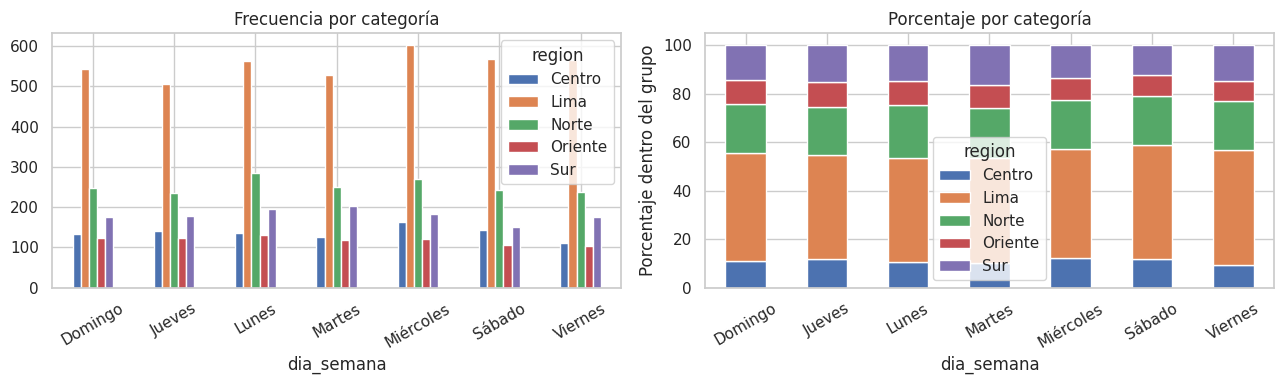

In [37]:
# EJECUTAR

def comparar_categorias(datos, primera, segunda, max_categorias=20):
    """Compara dos categorías con tablas y gráficos agrupados y apilados.

    Parámetros:
        datos (DataFrame): base que contiene ambas columnas; no se modifica.
        primera (str): columna que forma los grupos en las filas.
        segunda (str): columna cuyas categorías se comparan dentro de cada grupo.
        max_categorias (int): máximo de niveles de cada columna para graficar; por defecto 20.
    Retorna: DataFrame de porcentajes dentro de cada fila; muestra también las frecuencias.
    Ejemplo: comparar_categorias(df_limpio, "zona", "vehiculo").
    """
    if primera not in datos or segunda not in datos or primera == segunda or datos.empty:
        print("Se necesitan dos columnas distintas y una base con filas.")
        return pd.DataFrame()
    grupos_primero = datos[primera].astype(object).where(datos[primera].notna(), "(Nulo)").astype(str)
    grupos_segundo = datos[segunda].astype(object).where(datos[segunda].notna(), "(Nulo)").astype(str)
    frecuencias = pd.crosstab(grupos_primero.rename(primera), grupos_segundo.rename(segunda))
    porcentajes = frecuencias.div(frecuencias.sum(axis=1).replace(0, np.nan), axis=0).mul(100)
    print("Frecuencias:")
    display(frecuencias)
    print("Porcentaje dentro de cada grupo:")
    display(porcentajes.round(2))
    if len(frecuencias) > max_categorias or len(frecuencias.columns) > max_categorias:
        print("Se omiten gráficos porque alguna columna tiene demasiadas categorías.")
        return porcentajes
    fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
    frecuencias.plot.bar(ax=ejes[0], title="Frecuencia por categoría")
    porcentajes.plot.bar(stacked=True, ax=ejes[1], title="Porcentaje por categoría")
    ejes[1].set_ylabel("Porcentaje dentro del grupo")
    for ax in ejes:
        ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()
    return porcentajes


if len(columnas_categoricas_eda) >= 2:
    tabla_categorias_eda = comparar_categorias(df_limpio, columnas_categoricas_eda[0], columnas_categoricas_eda[1], MAX_CATEGORIAS_EDA)
else:
    print("Se necesitan dos columnas categóricas para una tabla cruzada.")

### 3.4.5 Tasas de una clase por categoría · SOLO CLASIFICACIÓN BINARIA

Como en S3/S4/S5, se muestran conteos, porcentaje de la clase positiva e índice frente a su tasa global. Por ejemplo, un índice 2 indica una tasa dos veces mayor que la global; no es una probabilidad. En la configuración de EDA indica CLASE_POSITIVA = 1 o la etiqueta real, como "Compra". Si no hay exactamente dos clases o la etiqueta no existe, se omite con un mensaje.

In [39]:
# EJECUTAR · Los indicadores de tasa solo se calculan para clasificación binaria.
def tasa_fuga(datos, variable, objetivo, clase_positiva=1):
    """Calcula la frecuencia de la clase positiva por categoría y su índice global.

    Parámetros:
        datos (DataFrame): base con la categoría y el objetivo; no se modifica.
        variable (str): columna categórica para agrupar, por ejemplo "zona".
        objetivo (str): columna que contiene exactamente dos clases observadas.
        clase_positiva: etiqueta del evento, por defecto 1; por ejemplo "Compra" o "Fuga".
    Retorna: DataFrame con casos, eventos, tasa porcentual e índice frente a la tasa global.
        Si no hay dos clases o no se reconoce la etiqueta, devuelve tabla vacía y explica por qué.
    Ejemplo: tasa_fuga(df_limpio, "zona", TARGET, clase_positiva=1).
    """
    if variable not in datos or objetivo not in datos or variable == objetivo:
        print("Se necesitan una categoría y un objetivo diferentes y existentes.")
        return pd.DataFrame()
    pares = datos[[variable, objetivo]].dropna(subset=[objetivo]).copy()
    clases = pares[objetivo].unique()
    if len(clases) != 2 or not pd.Series(clases).eq(clase_positiva).any():
        print(f"Se necesitan dos clases y una CLASE_POSITIVA válida. Clases observadas: {list(clases)}")
        return pd.DataFrame()
    grupos = pares[variable].astype(object).where(pares[variable].notna(), "(Nulo)").astype(str)
    eventos = pares[objetivo].eq(clase_positiva).astype(int)
    indicadores = pd.DataFrame({"grupo": grupos.to_numpy(), "evento": eventos.to_numpy()})
    tabla_base = indicadores.groupby("grupo")["evento"].agg(Casos="size", Eventos="sum", Tasa="mean")
    tasa_global = indicadores["evento"].mean()
    tabla = tabla_base.assign(Tasa_pct=tabla_base["Tasa"].mul(100),
                              Indice=tabla_base["Tasa"].div(tasa_global) if tasa_global else np.nan).drop(columns="Tasa")
    print(f"Tasa global de {clase_positiva}: {tasa_global * 100:.2f}%")
    display(tabla.sort_values("Tasa_pct", ascending=False).round(3))
    return tabla.sort_values("Tasa_pct", ascending=False)


def tasa_por_categoria(datos, variable, objetivo, clase_positiva=1, max_categorias=20):
    """Grafica la tasa positiva por categoría frente a la tasa global.

    Parámetros:
        datos (DataFrame): tabla que contiene las dos columnas; no se modifica.
        variable (str): categoría cuyos grupos se desean comparar.
        objetivo (str): objetivo de dos clases observadas.
        clase_positiva: valor que representa el evento; por defecto 1.
        max_categorias (int): máximo de grupos graficados; por defecto 20.
    Retorna: DataFrame de tasas e índices; dibuja la comparación cuando corresponde.
    Ejemplo: tasa_por_categoria(df_limpio, "zona", TARGET, clase_positiva=1).
    """
    tabla = tasa_fuga(datos, variable, objetivo, clase_positiva)
    if tabla.empty:
        return tabla
    if len(tabla) > max_categorias:
        print("Se omite el gráfico: hay demasiadas categorías.")
        return tabla
    tasa_global = datos[objetivo].dropna().eq(clase_positiva).mean() * 100
    ax = tabla["Tasa_pct"].plot.bar(figsize=(8, 4), title=f"Tasa de {clase_positiva} por {variable}")
    ax.axhline(tasa_global, color="darkorange", linestyle="--", label=f"Tasa global: {tasa_global:.1f}%")
    ax.set_ylabel("Porcentaje de la clase positiva")
    ax.legend()
    plt.tight_layout()
    plt.show()
    return tabla


def churn_apilado(datos, variable, objetivo, clase_positiva=1, max_categorias=20):
    """Compara las dos clases dentro de cada categoría mediante barras apiladas.

    Parámetros:
        datos (DataFrame): base con categoría y objetivo; no se modifica.
        variable (str): columna que define los grupos.
        objetivo (str): objetivo con exactamente dos clases observadas.
        clase_positiva: etiqueta de la clase de interés; por defecto 1.
        max_categorias (int): límite de grupos para los gráficos; por defecto 20.
    Retorna: tabla de porcentajes por grupo, o tabla vacía si no aplica.
    Ejemplo: churn_apilado(df_limpio, "zona", TARGET, clase_positiva=1).
    """
    if objetivo not in datos:
        print("El objetivo no existe en la base.")
        return pd.DataFrame()
    clases = datos[objetivo].dropna().unique()
    if len(clases) != 2 or not pd.Series(clases).eq(clase_positiva).any():
        print(f"Se necesitan dos clases y una clase positiva válida. Clases observadas: {list(clases)}")
        return pd.DataFrame()
    return comparar_categorias(datos.dropna(subset=[objetivo]), variable, objetivo, max_categorias)


if TIPO_PROBLEMA == "clasificacion":
    categorias_para_tasas = [c for c in columnas_categoricas_eda if c != TARGET]
    if categorias_para_tasas:
        tasas_eda = tasa_por_categoria(df_limpio, categorias_para_tasas[0], TARGET, CLASE_POSITIVA, MAX_CATEGORIAS_EDA)
        barras_apiladas_eda = churn_apilado(df_limpio, categorias_para_tasas[0], TARGET, CLASE_POSITIVA, MAX_CATEGORIAS_EDA)
    else:
        print("No hay categorías para calcular tasas por grupo.")
else:
    print("Las tasas de clases se usan para clasificación binaria; no se aplican al objetivo continuo.")

Las tasas de clases se usan para clasificación binaria; no se aplican al objetivo continuo.


### 3.4.6 Importe observado en la clase positiva · OPCIONAL

S4 suma los cargos de clientes que pertenecen a la clase de fuga y los compara con el total. Si el caso proporciona un importe relevante y un objetivo binario, indica su columna y activa la bandera. La anualización multiplica por 12 solo si el importe representa un valor mensual; no es una predicción de ahorro.

In [40]:
# OPCIONAL · EDITAR AQUÍ
EJECUTAR_IMPORTE_RIESGO = False
COLUMNA_IMPORTE_RIESGO = None  # Ejemplo: "cargo_mensual"; columna numérica de la base
FACTOR_PERIODO = 12  # 12 convierte un monto mensual a una proyección anual

def importe_en_riesgo(datos, columna_importe, objetivo, clase_positiva=1, factor=12):
    """Resume el importe observado de la clase positiva y su proporción del total.

    Parámetros:
        datos (DataFrame): base con el importe y el objetivo binario; no se modifica.
        columna_importe (str): nombre de la columna monetaria, por ejemplo "cargo_mensual".
        objetivo (str): columna con dos clases observadas.
        clase_positiva: clase que se desea sumar; por defecto 1.
        factor (int o float): multiplica el importe de esa clase, por defecto 12 para
            anualizar montos mensuales. Usa 1 si no deseas proyectar otro periodo.
    Retorna: Series con total, importe de la clase, porcentaje y valor multiplicado por factor.
    Ejemplo: importe_en_riesgo(df_limpio, "cargo_mensual", TARGET, 1, 12).
    """
    if columna_importe not in datos or objetivo not in datos:
        print("Indica una columna de importe y un objetivo existentes.")
        return pd.Series(dtype=float)
    base = datos[[columna_importe, objetivo]].dropna(subset=[objetivo]).copy()
    clases = base[objetivo].unique()
    if len(clases) != 2 or not pd.Series(clases).eq(clase_positiva).any():
        print("El importe por clase requiere dos clases y una clase positiva válida.")
        return pd.Series(dtype=float)
    importes = pd.to_numeric(base[columna_importe], errors="coerce")
    if not importes.notna().any() or not np.isfinite(importes.dropna()).all():
        print("No hay importes numéricos finitos para resumir.")
        return pd.Series(dtype=float)
    total = importes.sum(min_count=1)
    importe_evento = importes.loc[base[objetivo].eq(clase_positiva)].sum(min_count=1)
    resultado = pd.Series({"Importe total": total, "Importe clase positiva": importe_evento,
                           "Porcentaje del total": importe_evento / total * 100 if total != 0 else np.nan,
                           "Importe multiplicado por factor": importe_evento * factor})
    print("Importes no disponibles excluidos:", int(importes.isna().sum()))
    display(resultado.to_frame("Resultado"))
    return resultado


if EJECUTAR_IMPORTE_RIESGO and TIPO_PROBLEMA == "clasificacion":
    importe_riesgo_eda = importe_en_riesgo(df_limpio, COLUMNA_IMPORTE_RIESGO, TARGET, CLASE_POSITIVA, FACTOR_PERIODO)

### 3.4.7 Cantidad por dos categorías · OPCIONAL

En agentes se comparan retiros por zona y día de pago. Esta celda muestra estadísticas por dos categorías, boxplots con color por segundo grupo y barras de promedios. Edita los nombres o deja que se seleccionen las dos primeras categorías disponibles.

In [41]:
# OPCIONAL · Cambia a True si deseas comparar dos categorías a la vez.
EJECUTAR_GRUPOS_MULTIPLES = False

def comparar_dos_grupos(datos, primera, segunda, numerica, max_categorias=20):
    """Compara una cantidad entre combinaciones de dos variables categóricas.

    Parámetros:
        datos (DataFrame): base con las tres columnas; no se modifica.
        primera (str): columna para los grupos principales del eje horizontal.
        segunda (str): columna que divide cada grupo mediante colores.
        numerica (str): cantidad que se resume, por ejemplo el objetivo de regresión.
        max_categorias (int): máximo de niveles permitido por cada categoría; por defecto 20.
    Retorna: DataFrame con conteo, media, mediana y suma por combinación; muestra gráficos.
    Ejemplo: comparar_dos_grupos(df_limpio, "zona", "dia_pago", TARGET).
    """
    if len({primera, segunda, numerica}) != 3 or not all(c in datos for c in [primera, segunda, numerica]):
        print("Se necesitan tres columnas distintas y existentes.")
        return pd.DataFrame()
    if not pd.api.types.is_numeric_dtype(datos[numerica]):
        print("La variable a resumir debe ser numérica.")
        return pd.DataFrame()
    pares = datos[[primera, segunda, numerica]].replace([np.inf, -np.inf], np.nan).dropna(subset=[primera, segunda, numerica]).copy()
    if pares.empty:
        print("No hay filas completas para comparar esos grupos.")
        return pd.DataFrame()
    tabla = pares.groupby([primera, segunda], observed=True)[numerica].agg(["count", "mean", "median", "sum"])
    display(tabla.round(3))
    if pares[primera].nunique() > max_categorias or pares[segunda].nunique() > max_categorias:
        print("Se omiten gráficos porque hay demasiados grupos.")
        return tabla
    fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
    sns.boxplot(data=pares, x=primera, y=numerica, hue=segunda, showfliers=False, ax=ejes[0])
    ejes[0].set_title("Distribución por dos categorías")
    tabla["mean"].unstack(segunda).plot.bar(ax=ejes[1], title="Promedio por combinación")
    for ax in ejes:
        ax.tick_params(axis="x", rotation=30)
    plt.tight_layout()
    plt.show()
    return tabla


if EJECUTAR_GRUPOS_MULTIPLES and TIPO_PROBLEMA in {"regresion", "serie_tiempo"}:
    categorias_grupo = [c for c in columnas_categoricas_eda if c != TARGET]
    if len(categorias_grupo) >= 2:
        grupos_multiples_eda = comparar_dos_grupos(df_limpio, categorias_grupo[0], categorias_grupo[1], TARGET, MAX_CATEGORIAS_EDA)
    else:
        print("Se necesitan al menos dos columnas categóricas.")

### 3.4.8 Relaciones entre varias cantidades · OPCIONAL

El pairplot de S3/S4 muestra dispersiones para cada par y distribuciones en la diagonal. Puede tardar mucho: por defecto usa como máximo cinco variables y una muestra de 1000 filas. Cambia la lista o los límites de la llamada si el caso necesita otra selección.

Se usan las primeras 5 de 8 variables; cambia max_columnas si deseas más.


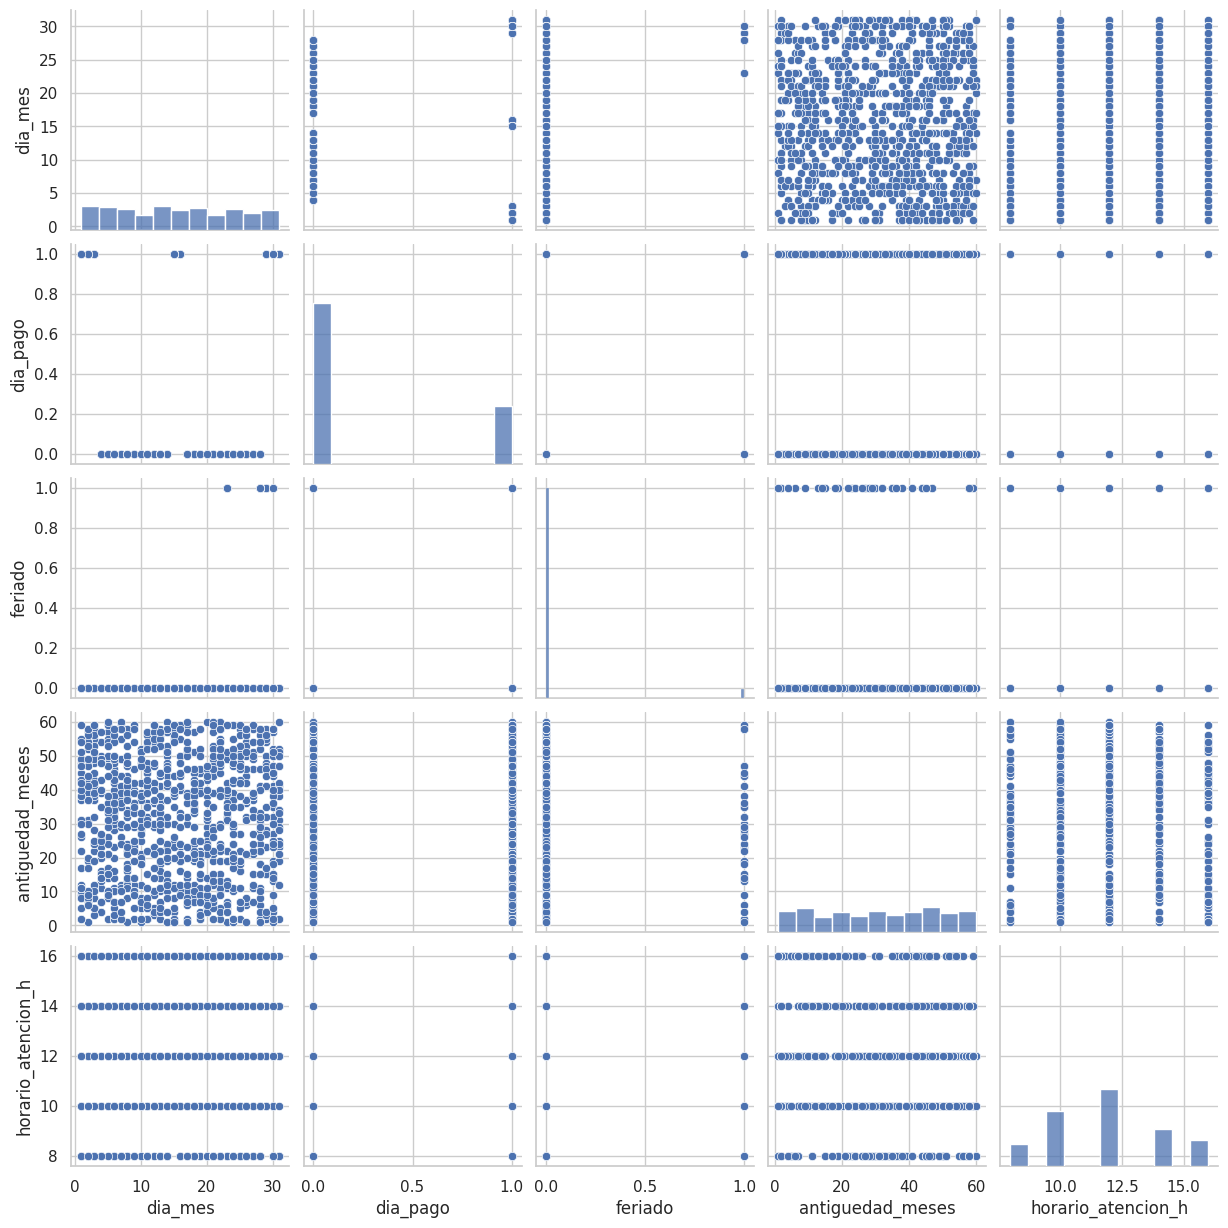

In [42]:
# OPCIONAL · True para generar el pairplot.
EJECUTAR_PAIRPLOT = True

def graficar_pares(datos, columnas, objetivo=None, muestra=1000, max_columnas=5, semilla=42):
    """Dibuja una matriz de relaciones entre cantidades, opcionalmente por clase.

    Parámetros:
        datos (DataFrame): base a explorar; no se modifica.
        columnas (list): columnas numéricas para la matriz.
        objetivo (str o None): columna categórica que distingue colores; None, por defecto,
            no separa grupos. Debe tener entre dos y diez clases para utilizarse.
        muestra (int): máximo de filas elegidas; por defecto 1000.
        max_columnas (int): máximo de cantidades para graficar; por defecto 5.
        semilla (int): fija la muestra aleatoria; por defecto 42.
    Retorna: None. Omite la figura si no hay dos variables con variación y filas completas.
    Ejemplo: graficar_pares(df_limpio, ["edad", "ingreso"], muestra=500).
    """
    elegidas = [c for c in columnas if c in datos and c != objetivo and pd.api.types.is_numeric_dtype(datos[c])
                and datos[c].replace([np.inf, -np.inf], np.nan).dropna().nunique() >= 2]
    if len(elegidas) > max_columnas:
        print(f"Se usan las primeras {max_columnas} de {len(elegidas)} variables; cambia max_columnas si deseas más.")
        elegidas = elegidas[:max_columnas]
    if len(elegidas) < 2:
        print("El pairplot requiere al menos dos cantidades con variación.")
        return
    usar_clase = objetivo is not None and objetivo in datos and 2 <= datos[objetivo].dropna().nunique() <= 10
    columnas_grafico = elegidas + ([objetivo] if usar_clase else [])
    tabla = datos[columnas_grafico].replace([np.inf, -np.inf], np.nan).dropna()
    if len(tabla) < 2:
        print("No hay suficientes filas completas para el pairplot.")
        return
    muestra_tabla = tabla.sample(n=min(muestra, len(tabla)), random_state=semilla)
    sns.pairplot(muestra_tabla, vars=elegidas, hue=objetivo if usar_clase else None, diag_kind="hist")
    plt.show()


if EJECUTAR_PAIRPLOT:
    graficar_pares(df_limpio, columnas_numericas_eda,
                   TARGET if TIPO_PROBLEMA == "clasificacion" else None, 1000, 5, SEMILLA)

### 3.4.9 Perfiles de varios grupos · OPCIONAL

Como en S3/S4, compara las medias de varias cantidades por categoría y las presenta en una tabla y un mapa de calor. Las columnas pueden estar en unidades distintas: compara los valores con cuidado y revisa también los descriptivos originales.

dia_semana,Domingo,Jueves,Lunes,Martes,Miércoles,Sábado,Viernes
dia_mes,15.818,15.496,16.699,15.500,15.704,14.919,16.301
dia_pago,0.238,0.319,0.152,0.231,0.404,0.213,0.182
feriado,0.083,0.071,0.000,0.078,0.065,0.000,0.000
antiguedad_meses,31.083,31.394,34.217,31.109,32.423,31.496,33.549
horario_atencion_h,12.003,11.888,11.846,11.868,11.754,11.834,11.888
transacciones_prom_7d,15.930,15.289,16.625,16.112,15.972,16.106,16.420
retiros_prom_7d,1850.077,1786.268,1937.401,1878.856,1868.211,1886.734,1919.103
monto_retiros,958.372,1971.936,2457.014,2048.029,2078.800,1935.205,2346.498


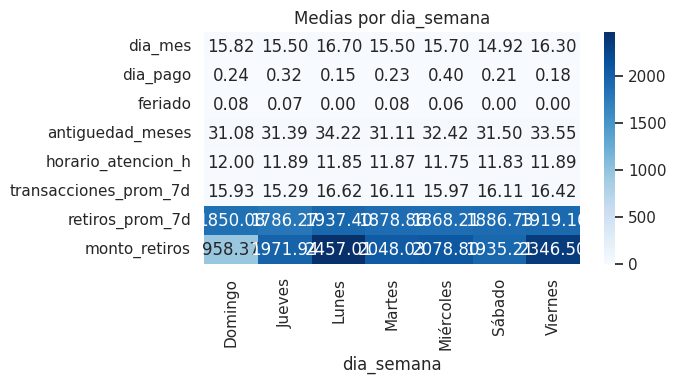

In [43]:
# OPCIONAL · True para comparar medias de varias columnas por grupo.
EJECUTAR_PERFILES = True

def perfiles_por_grupo(datos, grupo, columnas, max_grupos=20):
    """Calcula y grafica la media de varias cantidades en cada grupo.

    Parámetros:
        datos (DataFrame): base de exploración; no se modifica.
        grupo (str): nombre de la columna categórica que define los grupos.
        columnas (list): cantidades numéricas que se resumen.
        max_grupos (int): máximo de grupos para el mapa de calor; por defecto 20.
    Retorna: DataFrame con una media por variable y grupo; muestra tabla y mapa de calor.
    Ejemplo: perfiles_por_grupo(df_limpio, "zona", ["edad", "ingreso"]).
    """
    elegidas = [c for c in columnas if c in datos and c != grupo and pd.api.types.is_numeric_dtype(datos[c])]
    if grupo not in datos or not elegidas:
        print("Se necesitan una categoría de agrupación y al menos una cantidad.")
        return pd.DataFrame()
    tabla = datos.groupby(grupo, dropna=False, observed=True)[elegidas].mean().T
    if tabla.empty or not tabla.notna().any().any():
        print("No hay medias disponibles para comparar perfiles.")
        return tabla
    display(tabla.round(3))
    if len(tabla.columns) > max_grupos:
        print("Se omite el mapa: hay demasiados grupos.")
        return tabla
    plt.figure(figsize=(max(6, len(tabla.columns)), max(3, len(tabla) * 0.5)))
    sns.heatmap(tabla, annot=True, fmt=".2f", cmap="Blues")
    plt.title(f"Medias por {grupo}")
    plt.tight_layout()
    plt.show()
    return tabla


if EJECUTAR_PERFILES:
    grupo_perfiles = TARGET if TIPO_PROBLEMA == "clasificacion" else next((c for c in columnas_categoricas_eda if c != TARGET), None)
    if grupo_perfiles is None:
        print("No hay categoría para agrupar perfiles.")
    else:
        perfiles_eda = perfiles_por_grupo(df_limpio, grupo_perfiles, columnas_numericas_eda, MAX_CATEGORIAS_EDA)

### 3.4.10 Correlaciones · EJECUTAR

El mapa muestra Pearson entre cantidades: valores cerca de 1 o −1 indican asociación lineal positiva o negativa; cerca de 0 no descarta relaciones no lineales. Para categorías se crean indicadores individuales (one-hot) al comparar contra el objetivo. Los códigos de una categoría nominal no se interpretan como cantidades.

,dia_mes,dia_pago,feriado,antiguedad_meses,horario_atencion_h,transacciones_prom_7d,retiros_prom_7d,monto_retiros
dia_mes,1.000,-0.036,0.280,-0.004,0.001,-0.011,-0.014,-0.033
dia_pago,-0.036,1.000,0.127,0.002,-0.004,-0.002,-0.002,0.174
feriado,0.280,0.127,1.000,-0.002,0.006,-0.010,-0.008,-0.113
antiguedad_meses,-0.004,0.002,-0.002,1.000,-0.010,0.083,0.081,0.073
horario_atencion_h,0.001,-0.004,0.006,-0.010,1.000,0.090,0.090,0.080
transacciones_prom_7d,-0.011,-0.002,-0.010,0.083,0.090,1.000,0.965,0.789
retiros_prom_7d,-0.014,-0.002,-0.008,0.081,0.090,0.965,1.000,0.797
monto_retiros,-0.033,0.174,-0.113,0.073,0.080,0.789,0.797,1.000


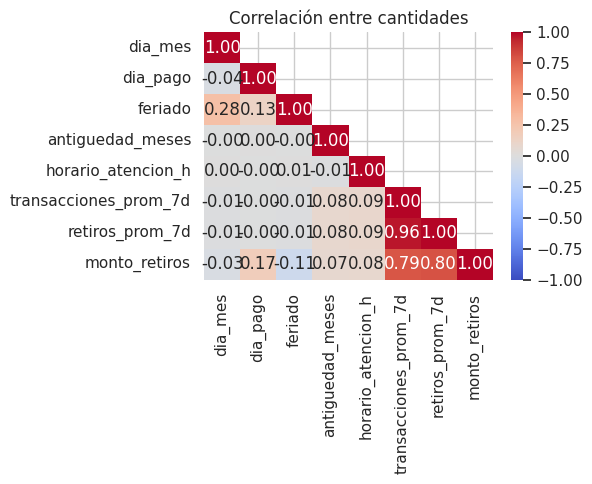

,Correlación con objetivo
num__retiros_prom_7d,0.797
num__transacciones_prom_7d,0.789
cat__dia_semana_Domingo,-0.261
num__dia_pago,0.174
cat__zona_Rural,-0.136
cat__zona_Urbana,0.136
cat__tipo_comercio_Librería,-0.129
cat__dia_semana_Lunes,0.129
num__feriado,-0.113
cat__tipo_comercio_Ferretería,-0.105


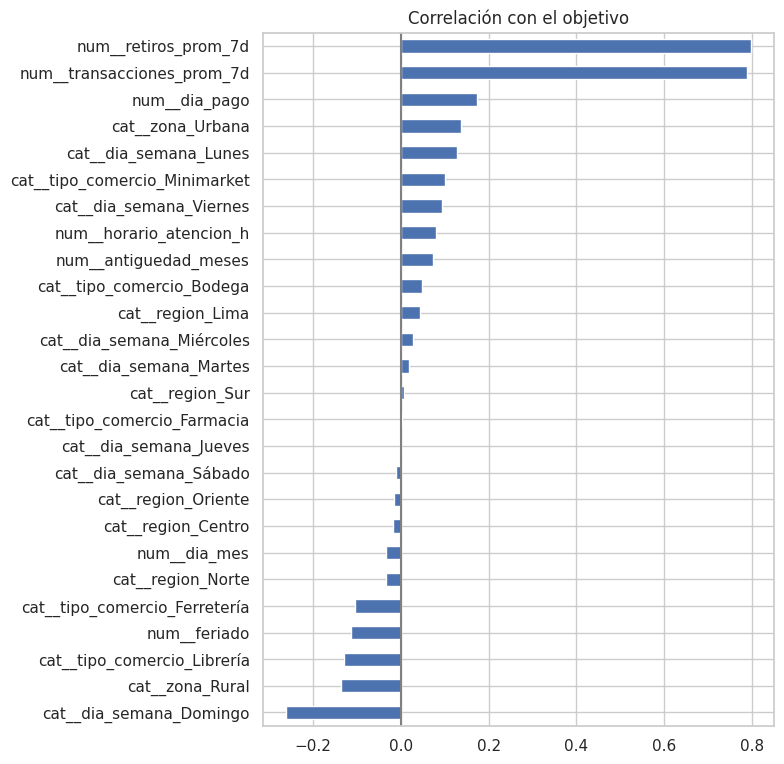

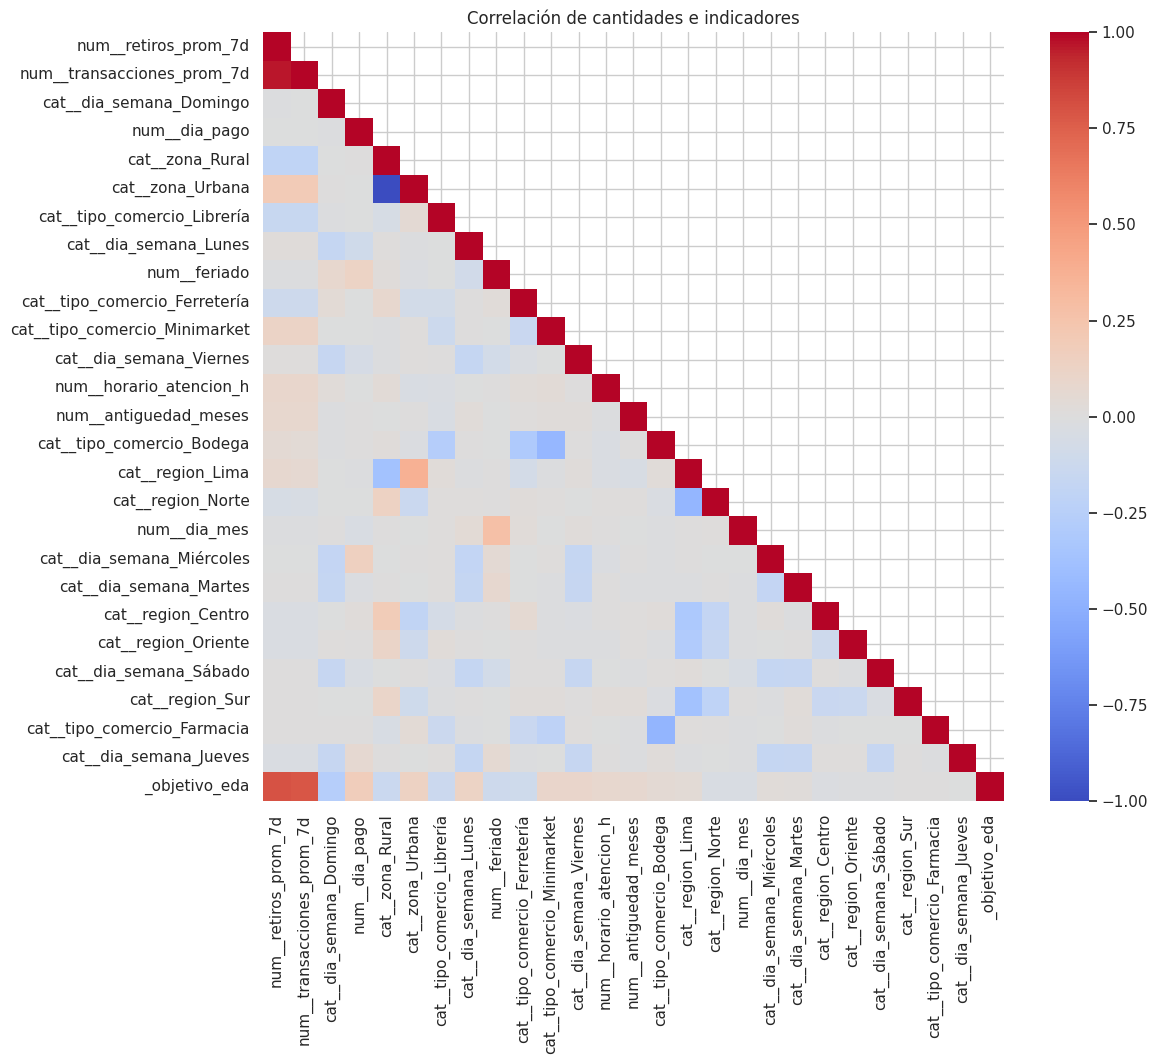

In [44]:
# EJECUTAR

def graficar_correlacion(datos, columnas, max_columnas=30):
    """Muestra la matriz de Pearson entre variables numéricas con variación.

    Parámetros:
        datos (DataFrame): base de exploración; no se modifica.
        columnas (list): nombres de variables numéricas para comparar.
        max_columnas (int): máximo de columnas dibujadas, por defecto 30; evita un gráfico ilegible.
    Retorna: DataFrame de correlaciones. Si faltan dos variables válidas, devuelve tabla vacía.
    Ejemplo: graficar_correlacion(df_limpio, ["edad", "ingreso", TARGET]).
    """
    elegidas = [c for c in columnas if c in datos and pd.api.types.is_numeric_dtype(datos[c])
                and datos[c].replace([np.inf, -np.inf], np.nan).dropna().nunique() >= 2]
    if len(elegidas) > max_columnas:
        print(f"Se muestran las primeras {max_columnas} variables de {len(elegidas)}; ajusta max_columnas si necesitas más.")
        elegidas = elegidas[:max_columnas]
    if len(elegidas) < 2:
        print("La correlación necesita al menos dos variables numéricas con variación.")
        return pd.DataFrame()
    tabla = datos[elegidas].replace([np.inf, -np.inf], np.nan).corr()
    fuera_diagonal = tabla.where(~np.eye(len(tabla), dtype=bool))
    if not fuera_diagonal.notna().any().any():
        print("No hay pares de observaciones suficientes para calcular correlaciones.")
        return tabla
    display(tabla.round(3))
    mascara = np.triu(np.ones_like(tabla, dtype=bool), k=1)
    plt.figure(figsize=(max(6, len(tabla) * 0.55), max(5, len(tabla) * 0.45)))
    sns.heatmap(tabla, mask=mascara, annot=len(tabla) <= 15, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
    plt.title("Correlación entre cantidades")
    plt.tight_layout()
    plt.show()
    return tabla


def correlacion_con_objetivo(datos, numericas, categoricas, objetivo, tipo, clase_positiva=1, max_categorias=20):
    """Compara Pearson del objetivo con cantidades e indicadores de categorías.

    Parámetros:
        datos (DataFrame): base para describir; no se modifica ni se ajusta un modelo.
        numericas (list): columnas de cantidades a considerar.
        categoricas (list): columnas categóricas que se convertirán en indicadores 0/1.
        objetivo (str): respuesta numérica o de clasificación binaria.
        tipo (str): "clasificacion" exige dos clases y convierte el evento positivo a 1;
            para "regresion" y "serie_tiempo" el objetivo debe ser numérico.
        clase_positiva: etiqueta de interés si hay clasificación binaria; por defecto 1.
        max_categorias (int): máximo de niveles por variable categórica; por defecto 20.
    Retorna: Series de correlaciones ordenadas por magnitud; muestra una tabla, barras y
        una matriz con hasta 30 columnas. Correlación no implica causalidad.
    Ejemplo: correlacion_con_objetivo(df_limpio, ["edad"], ["zona"], TARGET, "regresion").
    """
    if objetivo not in datos:
        print("El objetivo no existe para calcular correlaciones.")
        return pd.Series(dtype=float)
    if tipo == "clasificacion":
        clases = datos[objetivo].dropna().unique()
        if len(clases) != 2 or not pd.Series(clases).eq(clase_positiva).any():
            print(f"La correlación binaria requiere dos clases y CLASE_POSITIVA válida: {list(clases)}")
            return pd.Series(dtype=float)
        respuesta = datos[objetivo].eq(clase_positiva).astype(float).where(datos[objetivo].notna())
    else:
        if not pd.api.types.is_numeric_dtype(datos[objetivo]):
            print("El objetivo debe ser numérico para correlación de regresión o serie.")
            return pd.Series(dtype=float)
        respuesta = datos[objetivo].replace([np.inf, -np.inf], np.nan)
    columnas_num = [c for c in numericas if c in datos and c != objetivo and pd.api.types.is_numeric_dtype(datos[c])]
    columnas_cat = [c for c in categoricas if c in datos and c != objetivo and datos[c].nunique(dropna=False) <= max_categorias]
    omitidas = [c for c in categoricas if c in datos and c != objetivo and c not in columnas_cat]
    if omitidas:
        print("Categorías omitidas por cardinalidad:", omitidas)
    matriz_num = datos[columnas_num].replace([np.inf, -np.inf], np.nan).add_prefix("num__")
    matriz_cat = pd.get_dummies(datos[columnas_cat], columns=columnas_cat,
                                prefix=["cat__" + str(c) for c in columnas_cat],
                                dtype=float, dummy_na=True) if columnas_cat else pd.DataFrame(index=datos.index)
    predictores = pd.concat([matriz_num, matriz_cat], axis=1)
    if predictores.empty:
        print("No hay predictores para correlacionar con el objetivo.")
        return pd.Series(dtype=float)
    if predictores.columns.duplicated().any():
        print("Se omiten nombres de indicadores repetidos en la comparación.")
    predictores_unicos = predictores.loc[:, ~predictores.columns.duplicated()]
    columnas_validas = []
    for columna in predictores_unicos.columns:
        pares = pd.concat([predictores_unicos[columna], respuesta], axis=1).dropna()
        if len(pares) >= 2 and pares.iloc[:, 0].nunique() >= 2 and pares.iloc[:, 1].nunique() >= 2:
            columnas_validas.append(columna)
    if not columnas_validas:
        print("No hay correlaciones definidas; revisa si hay variables constantes o pocos datos.")
        return pd.Series(dtype=float)
    predictores_validos = predictores_unicos.loc[:, columnas_validas]
    correlaciones = predictores_validos.corrwith(respuesta).dropna().sort_values(key=abs, ascending=False)
    if correlaciones.empty:
        print("No hay correlaciones definidas; revisa si hay variables constantes o pocos datos.")
        return correlaciones
    display(correlaciones.to_frame("Correlación con objetivo").round(3))
    ax = correlaciones.head(30).sort_values().plot.barh(figsize=(8, max(3, min(12, len(correlaciones) * .3))), title="Correlación con el objetivo")
    ax.axvline(0, color="gray")
    plt.tight_layout()
    plt.show()
    elegidas = correlaciones.index[:29]
    if len(correlaciones) > 29:
        print("La matriz muestra las 29 variables de mayor correlación absoluta con el objetivo.")
    matriz = predictores_validos.loc[:, elegidas].assign(_objetivo_eda=respuesta).corr()
    plt.figure(figsize=(max(6, len(matriz) * .45), max(5, len(matriz) * .4)))
    sns.heatmap(matriz, mask=np.triu(np.ones_like(matriz, dtype=bool), k=1), cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=len(matriz) <= 15, fmt=".2f")
    plt.title("Correlación de cantidades e indicadores")
    plt.tight_layout()
    plt.show()
    return correlaciones


correlaciones_numericas_eda = graficar_correlacion(df_limpio, columnas_numericas_eda)
correlaciones_objetivo_eda = correlacion_con_objetivo(df_limpio, columnas_numericas_eda, columnas_categoricas_eda,
                                                       TARGET, TIPO_PROBLEMA, CLASE_POSITIVA, MAX_CATEGORIAS_EDA)

### 3.4.11 Correlación de códigos de categorías · OPCIONAL E ILUSTRATIVA

S3/S4 muestran una matriz después de aplicar factorize a todas las columnas. Esta opción reproduce esa técnica para reconocer el gráfico, pero asigna números arbitrarios incluso a cantidades: **no interpretes sus correlaciones como relaciones válidas entre categorías nominales**. Usa preferentemente la celda anterior, que conserva las cantidades y transforma las categorías en indicadores.

In [ ]:
# OPCIONAL · True para reproducir la matriz ilustrativa de las referencias.
EJECUTAR_FACTORIZE_EDA = False

def correlacion_codigos_ilustrativa(datos, columnas, max_columnas=20):
    """Reproduce la matriz de Pearson calculada sobre códigos de aparición.

    Parámetros:
        datos (DataFrame): base que contiene las columnas; no se modifica.
        columnas (list): nombres de variables que se factorizarán, incluidas cantidades.
        max_columnas (int): máximo de columnas para la figura; por defecto 20.
    Retorna: DataFrame con correlaciones de códigos, solo como ilustración.
        La codificación depende del orden de aparición y no representa relaciones nominales válidas.
    Ejemplo: correlacion_codigos_ilustrativa(df_limpio, ["zona", "vehiculo"]).
    """
    elegidas = [c for c in columnas if c in datos][:max_columnas]
    if len(elegidas) < 2:
        print("Se requieren al menos dos columnas para esta ilustración.")
        return pd.DataFrame()
    codigos = datos[elegidas].apply(lambda columna: pd.factorize(columna)[0])
    matriz = codigos.corr()
    fuera_diagonal = matriz.where(~np.eye(len(matriz), dtype=bool))
    if not fuera_diagonal.notna().any().any():
        print("No hay correlaciones definidas entre los códigos.")
        return matriz
    plt.figure(figsize=(max(6, len(elegidas) * .5), max(5, len(elegidas) * .4)))
    sns.heatmap(matriz, mask=np.triu(np.ones_like(matriz, dtype=bool), k=1), annot=len(elegidas) <= 15,
                fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
    plt.title("Ilustración: correlación de códigos arbitrarios")
    plt.tight_layout()
    plt.show()
    return matriz


if EJECUTAR_FACTORIZE_EDA:
    columnas_factorizadas = list(dict.fromkeys(columnas_numericas_eda + columnas_categoricas_eda))
    matriz_codigos_eda = correlacion_codigos_ilustrativa(df_limpio, columnas_factorizadas)

### 3.4.12 Dispersión frente a una regla actual · OPCIONAL

En RapiMenú y agentes se compara el objetivo real contra una regla disponible antes del resultado. Activa esta celda solo si el enunciado proporciona esa regla. Indica una columna del eje X y escribe la fórmula en linea_base_eda. Esta exploración describe toda la base; la evaluación de la regla en validación y prueba sigue en la sección de modelos.

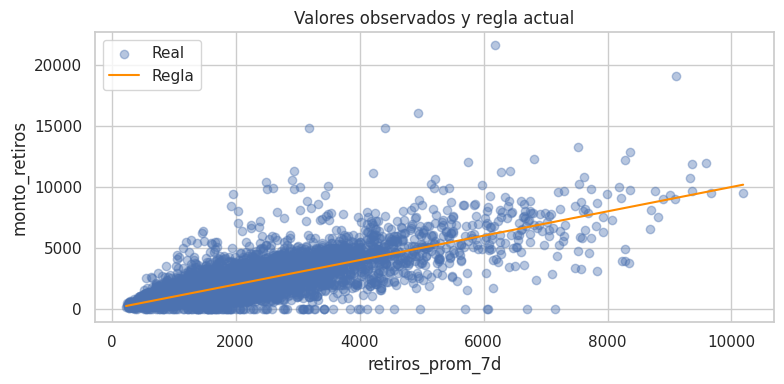

In [48]:
# OPCIONAL · EDITAR AQUÍ
EJECUTAR_REGLA_EDA = True
COLUMNA_X_REGLA = "retiros_prom_7d"  # Ejemplo: "distancia_km"

def linea_base_eda(datos):
    """Calcula la regla actual del negocio para las filas dadas.

    Parámetro:
        datos (DataFrame): filas con las columnas que necesita la regla; no se modifican.
    Retorna: lista, Series o array con un valor por fila. El valor inicial None indica que
        aún no se ha configurado una regla.
    Ejemplo para delivery: return 30 + 3 * datos["distancia_km"].
    """
    # Regla adaptada para utilizar el campo elegido como línea base
    return datos["retiros_prom_7d"]


def comparar_regla_eda(datos, columna_x, objetivo, predicciones):
    """Compara visualmente el objetivo real y una regla respecto de una cantidad.

    Parámetros:
        datos (DataFrame): base con la variable horizontal y el objetivo; no se modifica.
        columna_x (str): predictor numérico del eje horizontal, como "distancia_km".
        objetivo (str): columna numérica con los valores reales.
        predicciones (Series o array): valor de la regla para cada fila, en el mismo orden.
    Retorna: DataFrame de filas comparables; muestra una dispersión real y los valores de la regla.
    Ejemplo: comparar_regla_eda(df_limpio, "distancia_km", TARGET, linea_base_eda(df_limpio)).
    """
    if columna_x not in datos or objetivo not in datos or predicciones is None:
        print("Indica una columna horizontal, un objetivo y una regla válida.")
        return pd.DataFrame()
    if len(predicciones) != len(datos):
        raise ValueError("La regla debe devolver un valor por cada fila de la base.")
    comparables = datos[[columna_x, objetivo]].copy().assign(_regla_eda=np.asarray(predicciones))
    comparables = comparables.dropna().sort_values(columna_x)
    if comparables.empty:
        print("No hay filas completas para comparar con la regla.")
        return comparables
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(comparables[columna_x], comparables[objetivo], alpha=.4, label="Real")
    if comparables.groupby(columna_x)["_regla_eda"].nunique().max() <= 1:
        ax.plot(comparables[columna_x], comparables["_regla_eda"], color="darkorange", label="Regla")
    else:
        ax.scatter(comparables[columna_x], comparables["_regla_eda"], alpha=.4, label="Regla")
    ax.set(xlabel=columna_x, ylabel=objetivo, title="Valores observados y regla actual")
    ax.legend()
    plt.tight_layout()
    plt.show()
    return comparables


if EJECUTAR_REGLA_EDA and TIPO_PROBLEMA in {"regresion", "serie_tiempo"}:
    comparacion_regla_eda = comparar_regla_eda(df_limpio, COLUMNA_X_REGLA, TARGET, linea_base_eda(df_limpio))


## 4. Ruta de regresión
### 4.1 Preparar y dividir
Sigue RapiMenu y agentes: separa X/y y entrena modelos sobre los mismos predictores. Se conserva 60% train, 20% validación y 20% prueba para elegir sin usar prueba. Los nombres detectados se muestran: verifica especialmente IDs y códigos numéricos que representen categorías.

Una fecha ya convertida se excluye; una fecha leída como texto debe estar en COLUMNAS_EXCLUIR o transformarse en convertir_tipos. Los nulos se conservan hasta el Pipeline.

**Qué representan X, y y las tres partes:** X contiene los predictores, por ejemplo distancia y distrito; y contiene los valores reales de TARGET, por ejemplo tiempo de entrega. En regresión, el 60 % de las filas se usa para entrenar, 20 % para comparar candidatos y 20 % se reserva para la evaluación final. La separación es aleatoria con la SEMILLA configurada.

**Preparación automática:** el Pipeline rellena cantidades faltantes con la mediana y categorías faltantes con la moda aprendidas durante entrenamiento. Además, convierte cada categoría en columnas utilizables por el modelo y escala las cantidades. Aplícale la misma preparación a una base nueva sin volver a aprenderla a partir de esa base.

In [46]:
# EJECUTAR
if TIPO_PROBLEMA == "regresion":
    X = df_limpio.drop(columns=[TARGET] + COLUMNAS_EXCLUIR).select_dtypes(exclude=["datetime", "datetimetz", "timedelta"])
    y = df_limpio[TARGET]
    if X.empty or np.isinf(X.select_dtypes(include="number").to_numpy(dtype=float, na_value=np.nan)).any():
        raise ValueError("Revisa los predictores: no pueden estar vacíos ni contener infinitos.")
    print("Predictores:", X.columns.tolist())
    X_desarrollo, X_prueba, y_desarrollo, y_prueba = train_test_split(X, y, test_size=0.20, random_state=SEMILLA)
    X_train, X_validacion, y_train, y_validacion = train_test_split(X_desarrollo, y_desarrollo, test_size=0.25, random_state=SEMILLA)
    preparacion = crear_preparacion(X_train)
    print("Train / validación / prueba:", len(X_train), len(X_validacion), len(X_prueba))

Predictores: ['dia_semana', 'dia_mes', 'dia_pago', 'feriado', 'region', 'zona', 'tipo_comercio', 'antiguedad_meses', 'horario_atencion_h', 'transacciones_prom_7d', 'retiros_prom_7d']
Train / validación / prueba: 5212 1738 1738


### 4.2 Promedio · línea base
Siempre predice el promedio de entrenamiento. Un modelo útil debería mejorar esta referencia. Ejecuta este bloque si estás resolviendo regresión.

**Parámetro:** strategy="mean" predice siempre el promedio aprendido en train.

Promedio


,n_obs,MAE,MSE,RMSE,MAPE_pct,R2,ceros_MAPE
Train,5212,1076.725,2314014.857,1521.189,95.020,0.000,80
Validación,1738,1128.015,2623437.665,1619.703,92.858,-0.001,16


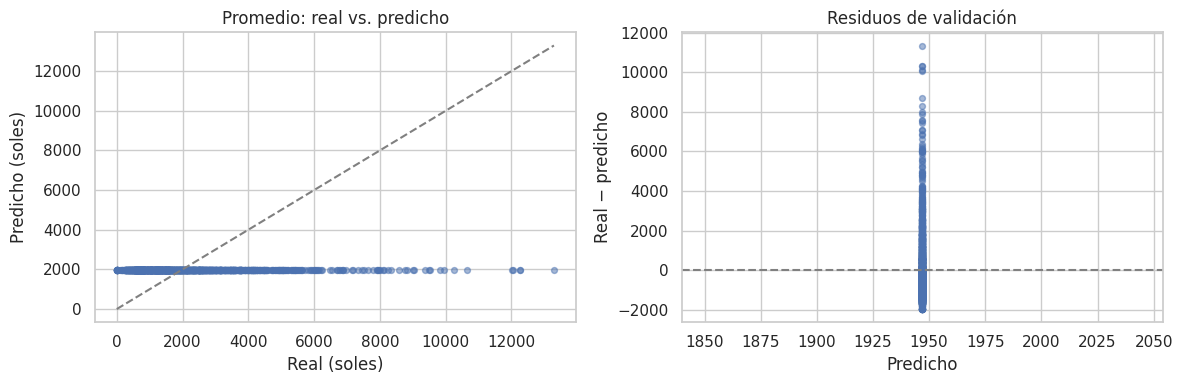

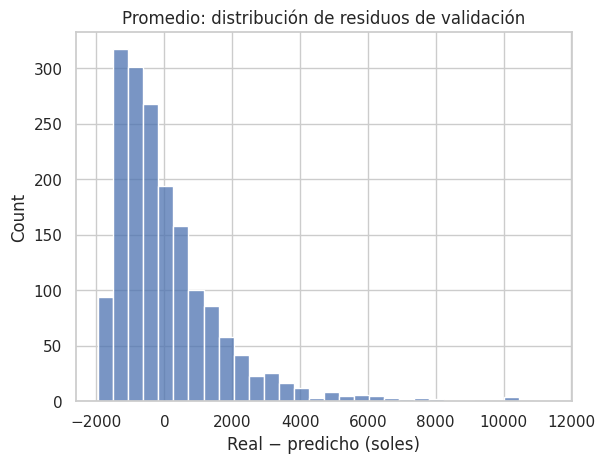

In [47]:
# EJECUTAR · Cambia los parámetros del constructor si lo pide el caso
if TIPO_PROBLEMA == "regresion":
    modelo_promedio = Pipeline([("preparacion", clone(preparacion)),
                              ("modelo", DummyRegressor(strategy="mean"))])
    modelo_promedio.fit(X_train, y_train)
    modelos["Promedio"] = modelo_promedio
    mostrar_modelo("Promedio", modelo_promedio, y_train, modelo_promedio.predict(X_train), y_validacion, modelo_promedio.predict(X_validacion))

### 4.3 Regresión lineal
Aprende una combinación lineal de los predictores; es una primera comparación fácil de explicar. Ejecuta este bloque si estás resolviendo regresión.

**Parámetros:** LinearRegression() ajusta coeficientes y un intercepto por defecto. Los valores de las categorías se codifican y los numéricos se escalan dentro del Pipeline.

Regresión lineal


,n_obs,MAE,MSE,RMSE,MAPE_pct,R2,ceros_MAPE
Train,5212,424.431,579634.786,761.337,29.708,0.750,80
Validación,1738,405.226,482837.494,694.865,27.189,0.816,16


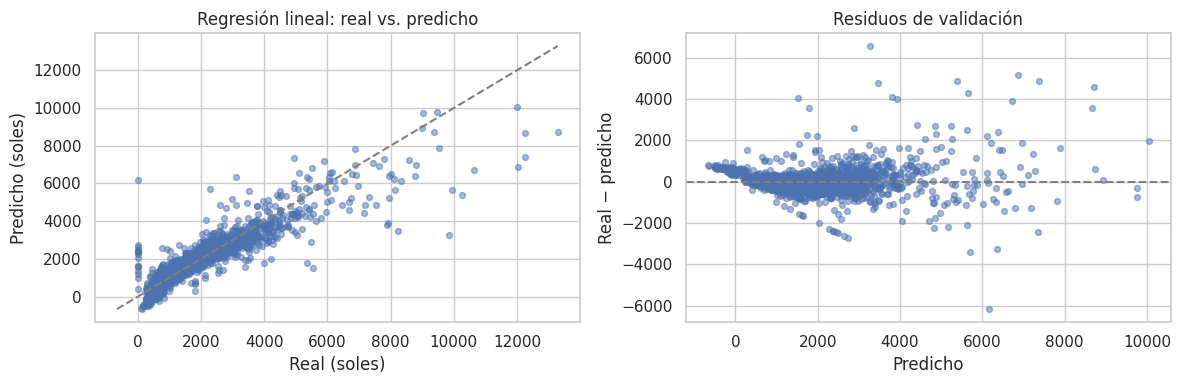

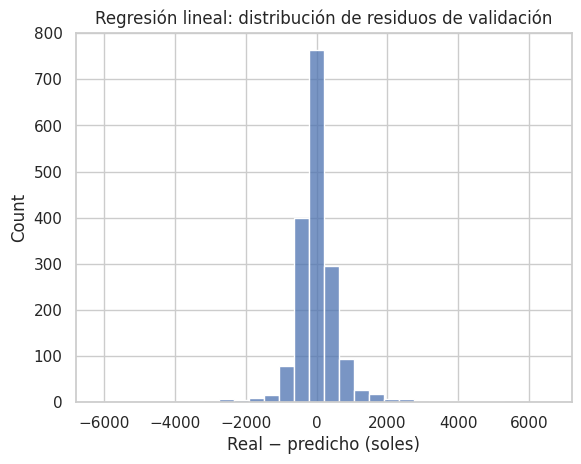

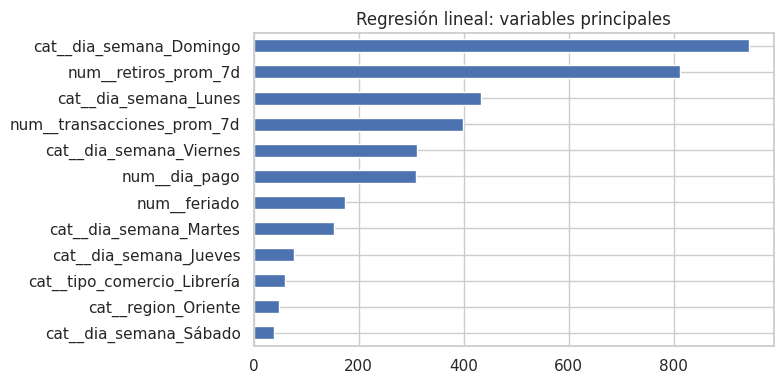

In [50]:
# EJECUTAR · Cambia los parámetros del constructor si lo pide el caso
if TIPO_PROBLEMA == "regresion":
    modelo_lineal = Pipeline([("preparacion", clone(preparacion)),
                              ("modelo", LinearRegression())])
    modelo_lineal.fit(X_train, y_train)
    modelos["Regresión lineal"] = modelo_lineal
    mostrar_modelo("Regresión lineal", modelo_lineal, y_train, modelo_lineal.predict(X_train), y_validacion, modelo_lineal.predict(X_validacion))

### 4.4 Árbol sin límite
Permite observar sobreajuste: compara sus errores de train y validación. Ejecuta este bloque si estás resolviendo regresión.

**Parámetros:** random_state fija el resultado aleatorio; max_depth sin valor permite crecer el árbol y puede causar sobreajuste.

Árbol sin límite


,n_obs,MAE,MSE,RMSE,MAPE_pct,R2,ceros_MAPE
Train,5212,0.000,0.000,0.000,0.000,1.000,80
Validación,1738,523.918,970873.183,985.329,25.335,0.629,16


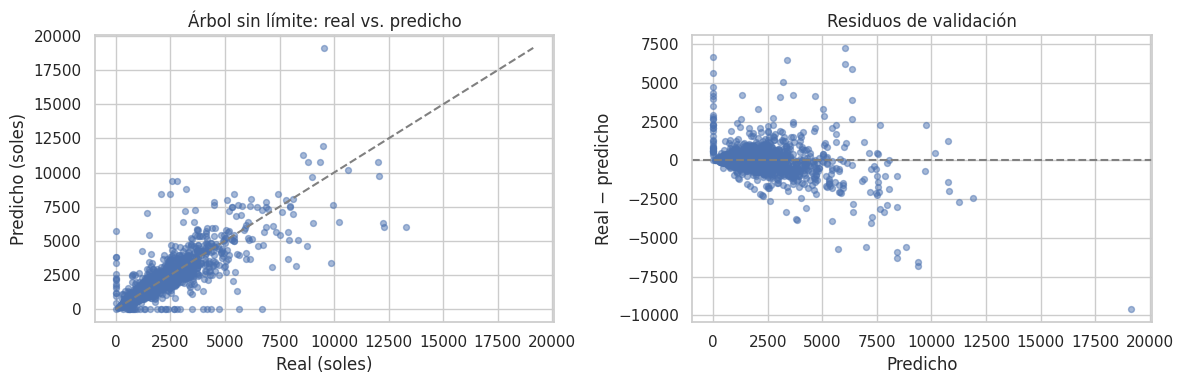

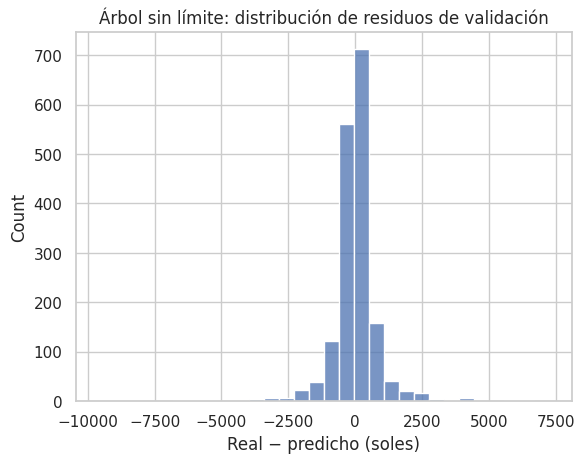

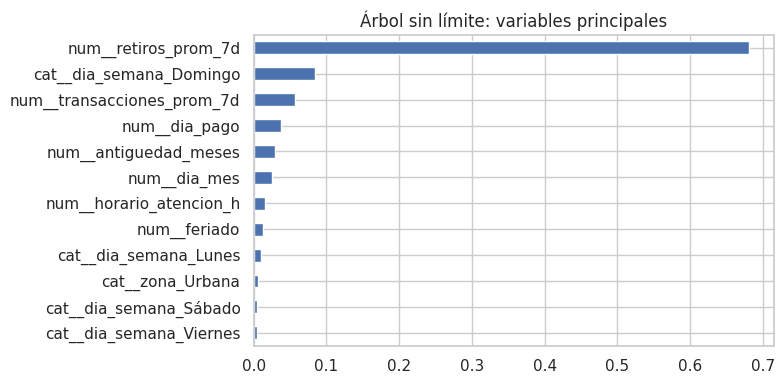

In [51]:
# EJECUTAR · Cambia los parámetros del constructor si lo pide el caso
if TIPO_PROBLEMA == "regresion":
    modelo_arbol_libre = Pipeline([("preparacion", clone(preparacion)),
                              ("modelo", DecisionTreeRegressor(random_state=SEMILLA))])
    modelo_arbol_libre.fit(X_train, y_train)
    modelos["Árbol sin límite"] = modelo_arbol_libre
    mostrar_modelo("Árbol sin límite", modelo_arbol_libre, y_train, modelo_arbol_libre.predict(X_train), y_validacion, modelo_arbol_libre.predict(X_validacion))

### 4.5 Árbol podado
Limita profundidad y exige ejemplos por hoja. No se ejecuta una búsqueda de hiperparámetros. Ejecuta este bloque si estás resolviendo regresión.

**Parámetros:** max_depth limita los niveles; min_samples_leaf exige un mínimo de filas por hoja; random_state fija la semilla.

Árbol podado


,n_obs,MAE,MSE,RMSE,MAPE_pct,R2,ceros_MAPE
Train,5212,428.690,588951.596,767.432,22.236,0.745,80
Validación,1738,435.487,551653.965,742.734,22.917,0.789,16


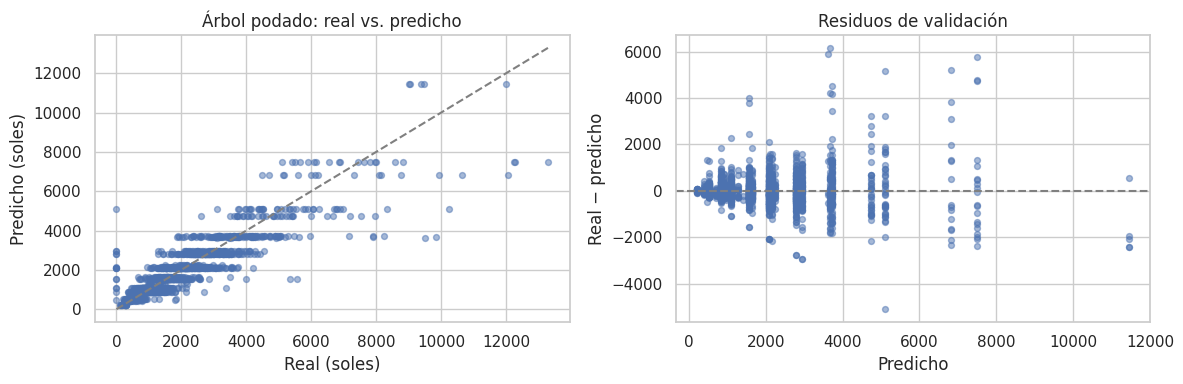

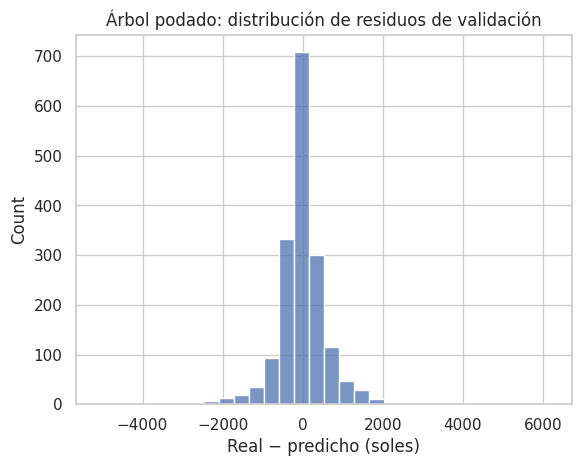

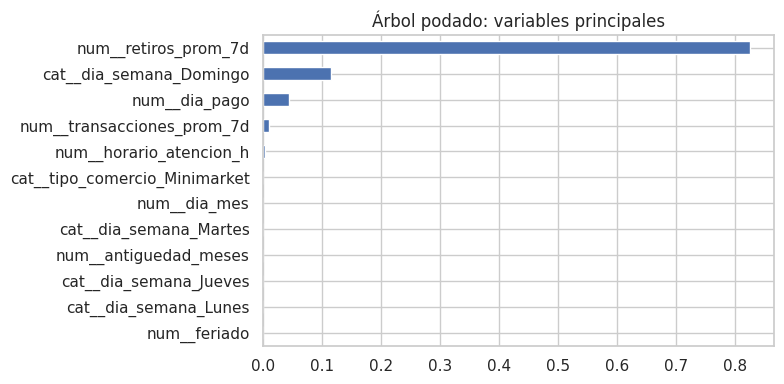

In [52]:
# EJECUTAR · Cambia los parámetros del constructor si lo pide el caso
if TIPO_PROBLEMA == "regresion":
    modelo_arbol_podado = Pipeline([("preparacion", clone(preparacion)),
                              ("modelo", DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=SEMILLA))])
    modelo_arbol_podado.fit(X_train, y_train)
    modelos["Árbol podado"] = modelo_arbol_podado
    mostrar_modelo("Árbol podado", modelo_arbol_podado, y_train, modelo_arbol_podado.predict(X_train), y_validacion, modelo_arbol_podado.predict(X_validacion))

### 4.6 Random Forest
Promedia 100 árboles. La profundidad y el tamaño de hoja ya tienen valores moderados. Ejecuta este bloque si estás resolviendo regresión.

**Parámetros:** n_estimators es la cantidad de árboles; max_depth limita sus niveles; min_samples_leaf exige filas por hoja; random_state fija la semilla y n_jobs=-1 usa los procesadores disponibles.

Random Forest


,n_obs,MAE,MSE,RMSE,MAPE_pct,R2,ceros_MAPE
Train,5212,279.948,300128.810,547.840,12.991,0.87,80
Validación,1738,341.031,393288.344,627.127,16.194,0.85,16


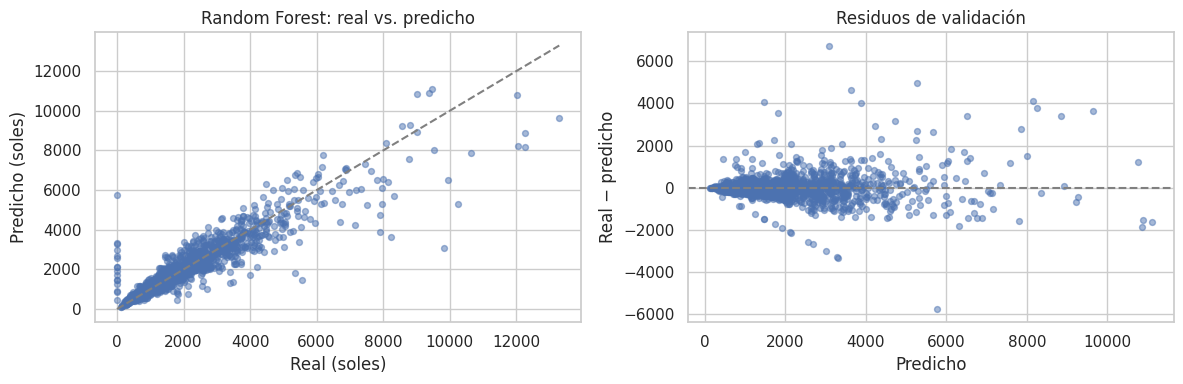

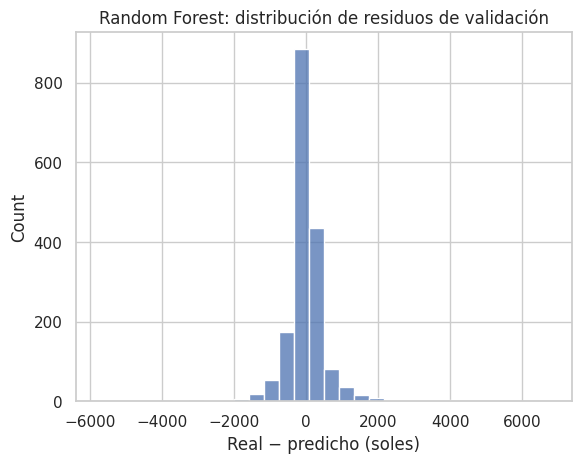

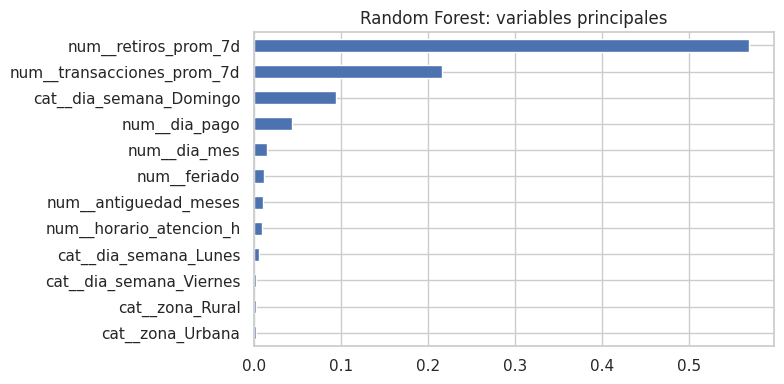

In [53]:
# EJECUTAR · Cambia los parámetros del constructor si lo pide el caso
if TIPO_PROBLEMA == "regresion":
    modelo_rf = Pipeline([("preparacion", clone(preparacion)),
                              ("modelo", RandomForestRegressor(n_estimators=100, max_depth=10, min_samples_leaf=3, random_state=SEMILLA, n_jobs=-1))])
    modelo_rf.fit(X_train, y_train)
    modelos["Random Forest"] = modelo_rf
    mostrar_modelo("Random Forest", modelo_rf, y_train, modelo_rf.predict(X_train), y_validacion, modelo_rf.predict(X_validacion))

### 4.7 XGBoost
Suma correcciones sucesivas. Se usan 100 árboles y tasa de aprendizaje 0.05. Ejecuta este bloque si estás resolviendo regresión.

**Parámetros:** n_estimators controla la cantidad de árboles; max_depth, su profundidad; learning_rate, el tamaño de cada corrección; random_state fija la semilla y n_jobs=-1 usa los procesadores disponibles.

XGBoost


,n_obs,MAE,MSE,RMSE,MAPE_pct,R2,ceros_MAPE
Train,5212,322.765,409975.729,640.293,15.824,0.823,80
Validación,1738,326.854,374900.938,612.292,16.510,0.857,16


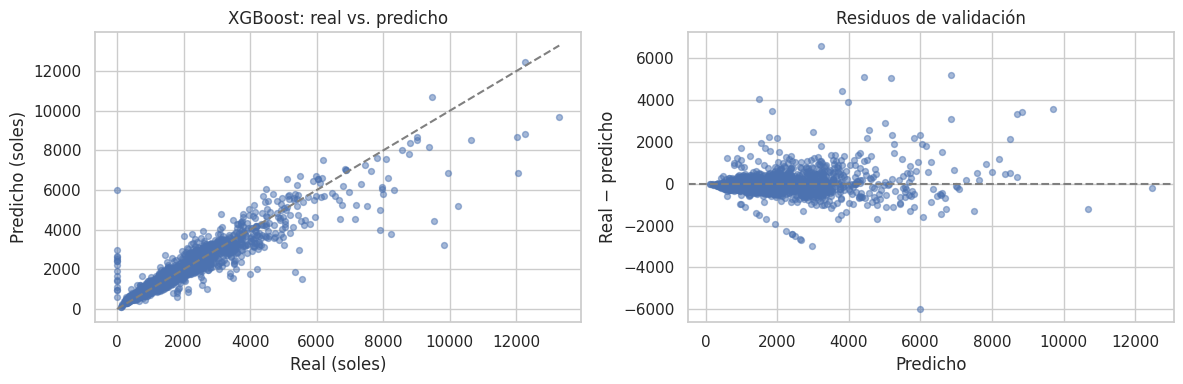

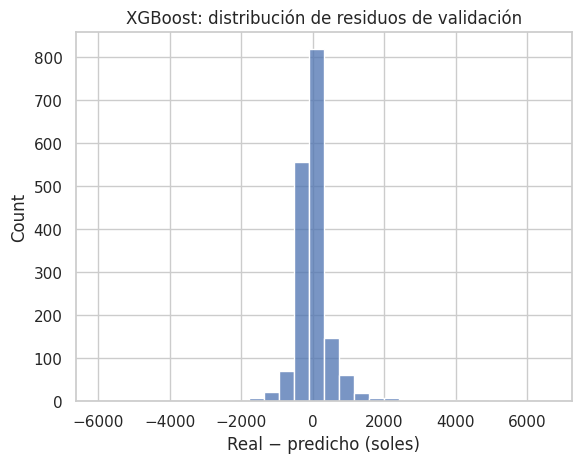

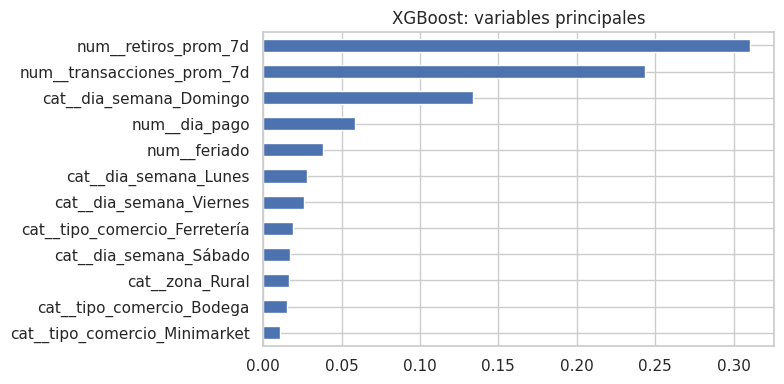

In [54]:
# EJECUTAR · Cambia los parámetros del constructor si lo pide el caso
if TIPO_PROBLEMA == "regresion":
    modelo_xgb = Pipeline([("preparacion", clone(preparacion)),
                              ("modelo", XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=SEMILLA, n_jobs=-1))])
    modelo_xgb.fit(X_train, y_train)
    modelos["XGBoost"] = modelo_xgb
    mostrar_modelo("XGBoost", modelo_xgb, y_train, modelo_xgb.predict(X_train), y_validacion, modelo_xgb.predict(X_validacion))

### 4.8 LightGBM
Otro boosting; compara su error con RF/XGBoost en las mismas filas de validación. Ejecuta este bloque si estás resolviendo regresión.

**Parámetros:** n_estimators indica la cantidad de árboles; learning_rate, la velocidad de aprendizaje; num_leaves, el máximo de hojas por árbol; random_state fija la semilla; n_jobs=-1 usa procesadores y verbosity=-1 reduce mensajes.

LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,n_obs,MAE,MSE,RMSE,MAPE_pct,R2,ceros_MAPE
Train,5212,321.961,413868.506,643.326,16.300,0.821,80
Validación,1738,328.325,380185.690,616.592,16.871,0.855,16


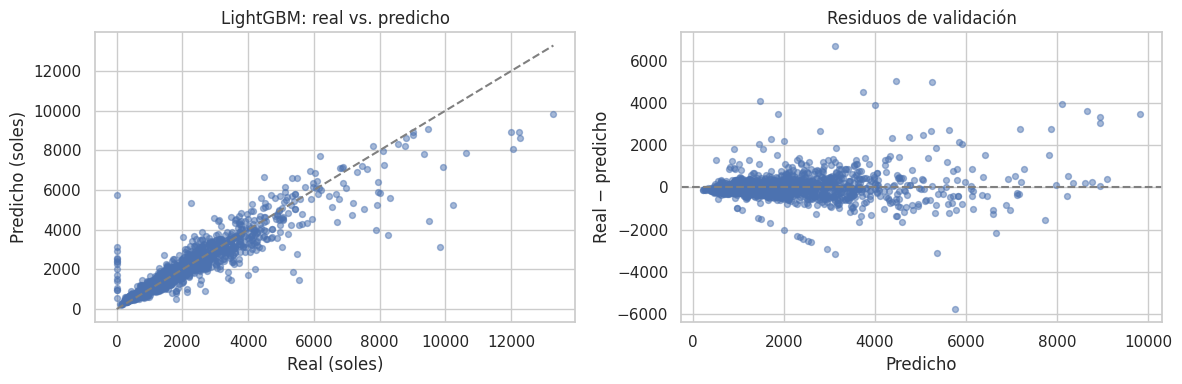

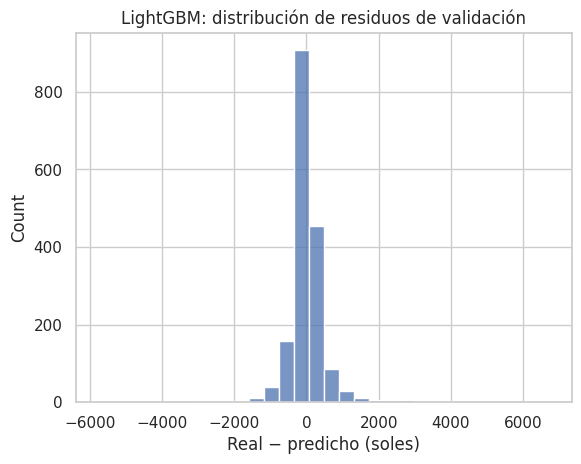

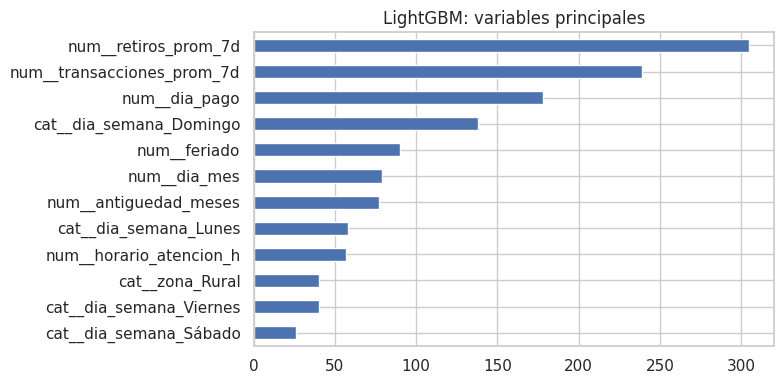

In [55]:
# EJECUTAR · Cambia los parámetros del constructor si lo pide el caso
if TIPO_PROBLEMA == "regresion":
    modelo_lgb = Pipeline([("preparacion", clone(preparacion)),
                              ("modelo", LGBMRegressor(n_estimators=100, learning_rate=0.05, num_leaves=15, random_state=SEMILLA, n_jobs=-1, verbosity=-1))])
    modelo_lgb.fit(X_train, y_train)
    modelos["LightGBM"] = modelo_lgb
    mostrar_modelo("LightGBM", modelo_lgb, y_train, modelo_lgb.predict(X_train), y_validacion, modelo_lgb.predict(X_validacion))

### OPCIONAL · Árbol con GridSearchCV
Si te piden buscar hiperparámetros, cambia la bandera a True y edita la grilla. Entrena varias combinaciones **solo con train** y registra el mejor árbol para compararlo en validación. Mantén la grilla pequeña para cuidar el tiempo. Profundidad limita niveles y min_samples_leaf exige observaciones por hoja.

Con max_depth = 4 o 6 se prueban dos profundidades máximas. Con min_samples_leaf = 3 o 5 se prueban dos tamaños mínimos de hoja: en total, cuatro combinaciones. cv = 3 divide train en tres partes para comparar esas combinaciones; después la ganadora se compara en la validación reservada. La búsqueda tarda más que un solo entrenamiento.

In [56]:
# OPCIONAL · EDITAR AQUÍ
EJECUTAR_GRID_ARBOL = False
if TIPO_PROBLEMA == "regresion" and EJECUTAR_GRID_ARBOL:
    from sklearn.model_selection import GridSearchCV
    grilla_arbol = {"modelo__max_depth": [4, 6], "modelo__min_samples_leaf": [3, 5]}
    busqueda_arbol = GridSearchCV(clone(modelo_arbol_podado), grilla_arbol, cv=3,
                                 scoring="neg_root_mean_squared_error", n_jobs=-1, error_score="raise")
    busqueda_arbol.fit(X_train, y_train)
    modelos["Árbol GridSearch"] = busqueda_arbol.best_estimator_
    print("Mejores parámetros:", busqueda_arbol.best_params_)
    mostrar_modelo("Árbol GridSearch", modelos["Árbol GridSearch"], y_train,
                   modelos["Árbol GridSearch"].predict(X_train), y_validacion,
                   modelos["Árbol GridSearch"].predict(X_validacion))

### OPCIONAL · Regla actual del negocio
Activa la regla solo si el enunciado la proporciona. Edita la función, por ejemplo: return 30 + 3 * datos["distancia_km"]. Debe usar datos disponibles al momento de decidir. Si TOLERANCIA está configurada, se muestran los porcentajes de subestimación (real − predicción > tolerancia) y de error absoluto mayor a tolerancia.

**Ejemplo:** si la regla es prometer 30 minutos más 3 minutos por kilómetro y distancia_km vale 4, la regla da 42 minutos. En la celda siguiente cambia USAR_REGLA_ACTUAL a True y reemplaza la línea raise NotImplementedError(...) por return 30 + 3 * datos["distancia_km"]. Solo úsala si el enunciado establece esa regla o una equivalente.

In [57]:
# OPCIONAL · EDITAR AQUÍ
USAR_REGLA_ACTUAL = True
NOMBRE_REGLA = "retiros_prom_7d"
def regla_actual(datos):
    """Calcula la decisión actual del negocio para cada fila recibida.

    Parámetro:
        datos (DataFrame): filas originales o preparadas, con columnas necesarias para la regla.
            Debe conservar el orden de las filas que deseas evaluar.
    Retorna: Series o array numérico con una predicción por fila. Reemplaza el return de ejemplo.
    Ejemplo para delivery: return 30 + 3 * datos['distancia_km'].
    """
    # Regla adaptada para utilizar el campo elegido como línea base
    return datos["retiros_prom_7d"]

if TIPO_PROBLEMA == "regresion" and USAR_REGLA_ACTUAL:
    pred_regla_validacion = regla_actual(df_limpio.loc[X_validacion.index])
    print(NOMBRE_REGLA, "en validación")
    display(pd.Series(metricas(y_validacion, pred_regla_validacion)).to_frame('Validación'))


retiros_prom_7d en validación


,Validación
n_obs,1738.000000
MAE,553.738780
MSE,802587.901036
RMSE,895.872704
MAPE_pct,32.677365
R2,0.693625
ceros_MAPE,16.000000


### 4.9 Comparación y sobreajuste
Cada modelo se entrenó una sola vez. Ahora se evalúa en train y validación. Un error muy bajo en train y alto en validación indica revisar sobreajuste. RMSE penaliza más los errores grandes; MAE se interpreta en unidades del target.

**Si el enunciado da una regla actual**, compárala en las mismas filas. Ejemplo de agentes: metricas(y_validacion, X_validacion["retiros_prom_7d"]). En RapiMenu: metricas(y_validacion, 30 + 3 * X_validacion["distancia_km"]). Cambia la fórmula según tu caso; no se ejecuta ninguna regla inventada.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


n_obs       MAE          MSE      RMSE  MAPE_pct  \
Modelo           Conjunto                                                       
Promedio         Train        5212  1076.725  2314014.857  1521.189    95.020   
                 Validación   1738  1128.015  2623437.665  1619.703    92.858   
Regresión lineal Train        5212   424.431   579634.786   761.337    29.708   
                 Validación   1738   405.226   482837.494   694.865    27.189   
Árbol sin límite Train        5212     0.000        0.000     0.000     0.000   
                 Validación   1738   523.918   970873.183   985.329    25.335   
Árbol podado     Train        5212   428.690   588951.596   767.432    22.236   
                 Validación   1738   435.487   551653.965   742.734    22.917   
Random Forest    Train        5212   279.948   300128.810   547.840    12.991   
                 Validación   1738   341.031   393288.344   627.127    16.194   
XGBoost          Train        5212   322.765   409975.729   640.293    15.824   
                 Validación   1738   326.854   374900.938   612.292    16.510   
LightGBM         Train        5212   321.961   413868.506   643.326    16.300   
                 Validación   1738   328.325   380185.690   616.592    16.871   

                                R2  ceros_MAPE  
Modelo           Conjunto                       
Promedio         Train       0.000          80  
                 Validación -0.001          16  
Regresión lineal Train       0.750          80  
                 Validación  0.816          16  
Árbol sin límite Train       1.000          80  
                 Validación  0.629          16  
Árbol podado     Train       0.745          80  
                 Validación  0.789          16  
Random Forest    Train       0.870          80  
                 Validación  0.850          16  
XGBoost          Train       0.823          80  
                 Validación  0.857          16  
LightGBM         Train       0.821          80  
                 Validación  0.855          16

,n_obs,MAE,MSE,RMSE,MAPE_pct,R2,ceros_MAPE
Modelo,,,,,,,
XGBoost,1738,326.854,374900.938,612.292,16.510,0.857,16
LightGBM,1738,328.325,380185.690,616.592,16.871,0.855,16
Random Forest,1738,341.031,393288.344,627.127,16.194,0.850,16
Regresión lineal,1738,405.226,482837.494,694.865,27.189,0.816,16
Árbol podado,1738,435.487,551653.965,742.734,22.917,0.789,16
Árbol sin límite,1738,523.918,970873.183,985.329,25.335,0.629,16
Promedio,1738,1128.015,2623437.665,1619.703,92.858,-0.001,16


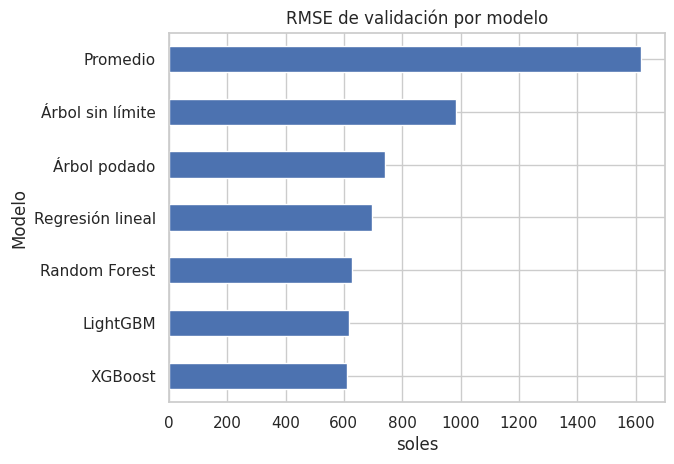

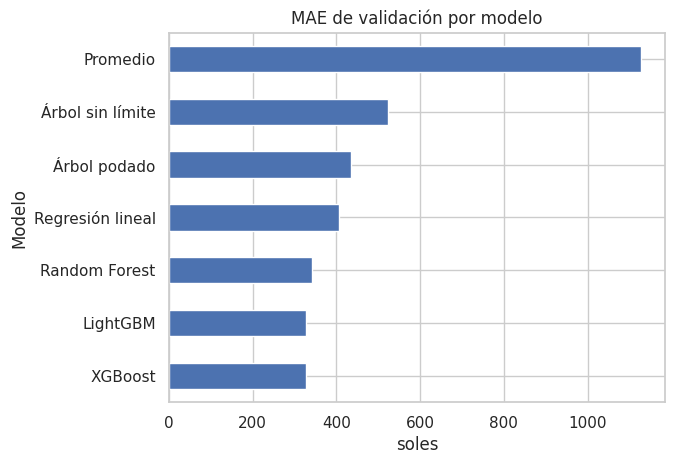

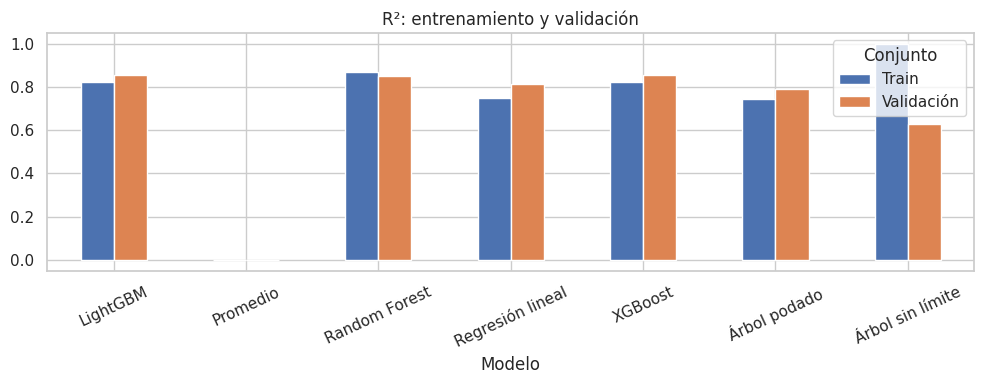

In [59]:
# EJECUTAR
if TIPO_PROBLEMA == "regresion":
    resultados = []
    for nombre, modelo in modelos.items():
        for conjunto, datos, reales in [("Train", X_train, y_train), ("Validación", X_validacion, y_validacion)]:
            resultados.append({"Modelo": nombre, "Conjunto": conjunto, **metricas(reales, modelo.predict(datos))})
    tabla_comparacion = pd.DataFrame(resultados).set_index(["Modelo", "Conjunto"])
    tabla_validacion = tabla_comparacion.xs("Validación", level="Conjunto")
    display(tabla_comparacion.round(3))
    display(tabla_validacion.sort_values("RMSE").round(3))

    tabla_validacion.sort_values("RMSE")["RMSE"].sort_values().plot.barh(title="RMSE de validación por modelo")
    plt.xlabel(UNIDAD)
    plt.show()

    tabla_validacion.sort_values("MAE")["MAE"].sort_values().plot.barh(title="MAE de validación por modelo")
    plt.xlabel(UNIDAD)
    plt.show()

    tabla_comparacion["R2"].unstack("Conjunto").plot.bar(title="R²: entrenamiento y validación", rot=25, figsize=(10, 4))
    plt.tight_layout()
    plt.show()


### 4.10 Top Modelos Ganadores · EJECUTAR
Esta sección resume los resultados de la validación y genera un ranking automático con los mejores modelos, facilitando la decisión final.

In [61]:
# EJECUTAR
if TIPO_PROBLEMA == "regresion":
    criterio = "RMSE"
    top_modelos = tabla_validacion.sort_values(criterio)

    print("🏆 TOP MODELOS GANADORES (Basado en menor error en Validación) 🏆")
    print("-" * 65)
    for i, (modelo, fila) in enumerate(top_modelos.head(3).iterrows(), 1):
        print(f"Puesto #{i}: {modelo}")
        print(f"  - RMSE: {fila['RMSE']:.2f} {UNIDAD}")
        print(f"  - MAE: {fila['MAE']:.2f} {UNIDAD}")
        print(f"  - R²: {fila['R2']:.4f}")
        print("-" * 65)

    mejor_modelo = top_modelos.index[0]
    print(f"\n💡 Conclusión: El modelo recomendado para elegir es '{mejor_modelo}', ya que presenta el menor {criterio} general, lo que significa que sus predicciones son las que menos se alejan de la realidad en el conjunto de validación.")

elif TIPO_PROBLEMA == "serie_tiempo":
    criterio = CRITERIO_SERIES
    top_modelos = tabla_validacion.sort_values(criterio)

    print("🏆 TOP MODELOS GANADORES (Basado en validación recursiva) 🏆")
    print("-" * 65)
    for i, (modelo, fila) in enumerate(top_modelos.head(3).iterrows(), 1):
        print(f"Puesto #{i}: {modelo}")
        print(f"  - {criterio}: {fila[criterio]:.2f}")
        print("-" * 65)

    mejor_modelo = top_modelos.index[0]
    print(f"\n💡 Conclusión: El modelo recomendado para elegir es '{mejor_modelo}', ya que presenta el menor {criterio} en el pronóstico recursivo.")


🏆 TOP MODELOS GANADORES (Basado en menor error en Validación) 🏆
-----------------------------------------------------------------
Puesto #1: XGBoost
  - RMSE: 612.29 soles
  - MAE: 326.85 soles
  - R²: 0.8569
-----------------------------------------------------------------
Puesto #2: LightGBM
  - RMSE: 616.59 soles
  - MAE: 328.32 soles
  - R²: 0.8549
-----------------------------------------------------------------
Puesto #3: Random Forest
  - RMSE: 627.13 soles
  - MAE: 341.03 soles
  - R²: 0.8499
-----------------------------------------------------------------

💡 Conclusión: El modelo recomendado para elegir es 'XGBoost', ya que presenta el menor RMSE general, lo que significa que sus predicciones son las que menos se alejan de la realidad en el conjunto de validación.


### Visualización de Modelos Candidatos (Validación)
Comparemos gráficamente cómo se alinean las predicciones de los mejores modelos candidatos frente a los valores reales observados en el conjunto de validación.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


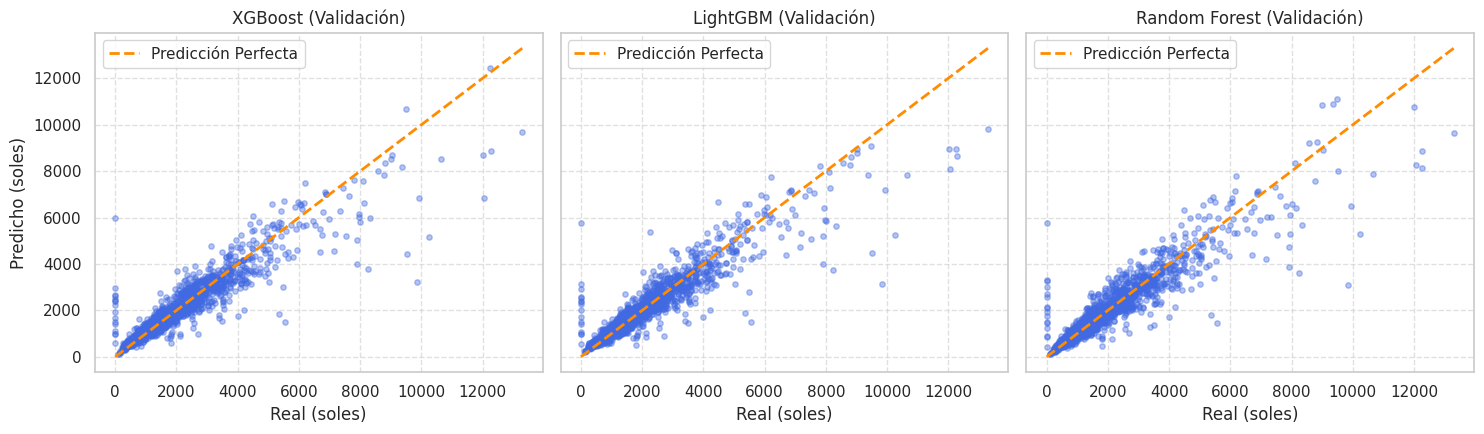

In [68]:
if TIPO_PROBLEMA == "regresion":
    import matplotlib.pyplot as plt

    # Modelos a graficar (Top 3)
    modelos_a_graficar = ["XGBoost", "LightGBM", "Random Forest"]
    modelos_disponibles = [m for m in modelos_a_graficar if m in modelos]

    if modelos_disponibles:
        fig, ejes = plt.subplots(1, len(modelos_disponibles), figsize=(5 * len(modelos_disponibles), 4.5), sharey=True)
        if len(modelos_disponibles) == 1:
            ejes = [ejes]

        limites = [y_validacion.min(), y_validacion.max()]

        for ax, nombre_mod in zip(ejes, modelos_disponibles):
            preds_val = modelos[nombre_mod].predict(X_validacion)
            ax.scatter(y_validacion, preds_val, alpha=0.4, color='royalblue', s=15)
            ax.plot(limites, limites, '--', color='darkorange', linewidth=2, label='Predicción Perfecta')
            ax.set_title(f"{nombre_mod} (Validación)")
            ax.set_xlabel(f"Real ({UNIDAD})")
            if ax == ejes[0]:
                ax.set_ylabel(f"Predicho ({UNIDAD})")
            ax.legend()
            ax.grid(True, linestyle='--', alpha=0.6)

        plt.tight_layout()
        plt.show()
    else:
        print("Los mejores modelos aún no han sido entrenados o agregados al diccionario.")

### 4.11 Probar el modelo ganador con datos nuevos
En esta sección puedes subir un nuevo archivo CSV con datos que el modelo nunca ha visto (sin necesidad de tener la columna objetivo) para generar predicciones utilizando el modelo que resultó ganador en la validación.

Sube el archivo a Colab y actualiza la variable `RUTA_DATOS_NUEVOS`.

In [67]:
# EDITAR AQUÍ · Ruta de tu nuevo archivo CSV para probar el modelo ganador
RUTA_DATOS_NUEVOS = "/content/PD_agentes_nuevos.csv" # Reemplaza con tu archivo

import os
from pathlib import Path

# Definir el directorio de salida por si no se ejecutó la celda correspondiente
SALIDAS = Path("/content/salidas_guia_pc2")
SALIDAS.mkdir(parents=True, exist_ok=True)

if TIPO_PROBLEMA == "regresion":
    if os.path.exists(RUTA_DATOS_NUEVOS):
        print(f"Cargando datos nuevos desde: {RUTA_DATOS_NUEVOS}")
        # 1. Leer el nuevo archivo
        df_nuevos_datos = leer_archivo(RUTA_DATOS_NUEVOS, SEPARADOR, CODIFICACION, DECIMAL, HOJA_EXCEL)

        # 2. Preparar los datos reutilizando las reglas históricas (es_nueva=True evita borrar filas sin target)
        df_nuevos_preparados = preparar_datos(df_nuevos_datos, es_nueva=True)

        # 3. Filtrar solo las columnas predictoras que el modelo espera
        faltantes = set(X.columns) - set(df_nuevos_preparados.columns)
        if faltantes:
            print(f"❌ Faltan las siguientes columnas predictoras en el nuevo archivo: {faltantes}")
        else:
            X_nuevos = df_nuevos_preparados.loc[:, X.columns]

            # 4. Entrenar el modelo ganador con TODA la historia disponible para su uso operativo
            print(f"\nEntrenando el modelo ganador ('{mejor_modelo}') con toda la base histórica...")
            modelo_ganador_operativo = clone(modelos[mejor_modelo]).fit(X, y)

            # 5. Generar predicciones
            predicciones_nuevas = modelo_ganador_operativo.predict(X_nuevos)

            # 6. Unir predicciones al dataframe original y exportar
            resultado_final = df_nuevos_datos.assign(prediccion_ganador=predicciones_nuevas)
            ruta_exportacion = SALIDAS / "predicciones_modelo_ganador.csv"
            resultado_final.to_csv(ruta_exportacion, index=False, encoding="utf-8-sig")

            print(f"✅ Predicciones completadas con éxito.")
            print(f"📂 Archivo guardado en: {ruta_exportacion}\n")
            display(resultado_final.head(10))

            # 7. Revisar errores si el target está disponible
            if TARGET in df_nuevos_preparados.columns:
                print("\n📊 Evaluando errores en la nueva data:")
                y_nuevos = df_nuevos_preparados[TARGET]
                validos = y_nuevos.notna()
                if validos.any():
                    y_validos = y_nuevos[validos].to_numpy()
                    pred_validos = predicciones_nuevas[validos]

                    metricas_nuevos = metricas(y_validos, pred_validos)
                    display(pd.Series(metricas_nuevos, name="Nuevos Datos").to_frame())

                    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
                    ejes[0].scatter(y_validos, pred_validos, alpha=0.5)
                    limites = [min(y_validos.min(), pred_validos.min()), max(y_validos.max(), pred_validos.max())]
                    ejes[0].plot(limites, limites, "--", color="gray")
                    ejes[0].set(xlabel="Real", ylabel="Predicción", title="Real vs. Predicho (Nuevos Datos)")

                    residuos = y_validos - pred_validos
                    ejes[1].scatter(pred_validos, residuos, alpha=0.5)
                    ejes[1].axhline(0, color="gray", linestyle="--")
                    ejes[1].set(xlabel="Predicción", ylabel="Residuo (Real - Predicción)", title="Residuos (Nuevos Datos)")
                    plt.tight_layout()
                    plt.show()
                else:
                    print("El target existe pero contiene puros nulos, no se pueden calcular las métricas.")
    else:
        print(f"❌ No se encontró el archivo: {RUTA_DATOS_NUEVOS}")
        print("Por favor, sube tu archivo a la pestaña de Archivos en Colab y actualiza la ruta.")

elif TIPO_PROBLEMA == "serie_tiempo":
    print("Para series de tiempo, el pronóstico operativo hacia el futuro ya se encuentra cubierto en la Sección 7.3.")

Cargando datos nuevos desde: /content/PD_agentes_nuevos.csv
Conversión explícita de fecha a fecha: 0 valores inválidos convertidos a nulo.
Nulos antes del tratamiento:


,nulos,nulos_pct
id_registro,0,0.0
fecha,0,0.0
id_agente,0,0.0
dia_semana,0,0.0
dia_mes,0,0.0
dia_pago,0,0.0
feriado,0,0.0
region,0,0.0
zona,0,0.0
tipo_comercio,0,0.0


Base nueva: se conservan todas las filas y sus valores reales disponibles.
Filas completamente duplicadas: 0
Filas duplicadas eliminadas: 0

Entrenando el modelo ganador ('XGBoost') con toda la base histórica...
✅ Predicciones completadas con éxito.
📂 Archivo guardado en: /content/salidas_guia_pc2/predicciones_modelo_ganador.csv



,id_registro,fecha,id_agente,dia_semana,dia_mes,dia_pago,feriado,region,zona,tipo_comercio,antiguedad_meses,horario_atencion_h,transacciones_prom_7d,retiros_prom_7d,prediccion_ganador
0,900001,2026-10-01,5844,Jueves,1,1,0,Lima,Urbana,Farmacia,19,8,10.2,1048.0,1455.577026
1,900002,2026-10-01,5083,Jueves,1,1,0,Lima,Urbana,Bodega,33,14,14.7,1573.0,2177.380127
2,900003,2026-10-01,5270,Jueves,1,1,0,Sur,Rural,Bodega,58,12,9.0,1292.0,1901.328735
3,900004,2026-10-01,5205,Jueves,1,1,0,Norte,Urbana,Bodega,42,14,17.7,2304.0,2948.749023
4,900005,2026-10-01,5105,Jueves,1,1,0,Lima,Urbana,Librería,24,14,17.7,2302.0,2925.858154
5,900006,2026-10-01,5374,Jueves,1,1,0,Lima,Urbana,Bodega,8,10,24.3,2675.0,3630.378906
6,900007,2026-10-01,5385,Jueves,1,1,0,Lima,Urbana,Farmacia,58,10,7.2,958.0,1248.415527
7,900008,2026-10-01,5075,Jueves,1,1,0,Lima,Urbana,Bodega,3,8,20.4,2313.0,3065.435791
8,900009,2026-10-01,5631,Jueves,1,1,0,Lima,Urbana,Bodega,31,12,12.6,1494.0,1968.104858
9,900010,2026-10-01,5460,Jueves,1,1,0,Norte,Urbana,Minimarket,29,8,19.2,2502.0,3146.666016


## 5. Ruta de series de tiempo
### 5.1 Calendario y memoria histórica
Sigue recaudación y el caso de series: fecha regular → calendario/rezagos → modelos → pronóstico recursivo. El target histórico no entra en la media móvil de su propia fila: se mantiene shift(1), corrigiendo ese problema de las referencias.

calendario(fechas, feriados) usa información conocida de antemano. crear_rezagos(serie, rezagos, ventana, feriados) construye la tabla de entrenamiento. pronosticar(modelo, historia, fechas, rezagos, ventana, feriados) usa sus propias predicciones al avanzar; modelo=None representa persistencia. Ninguna función cambia la historia de entrada.

### Feriados nacionales del Perú incluidos automáticamente

| Fecha | Feriado |
|---|---|
| 1 de enero | Año Nuevo |
| Móvil | Jueves Santo y Viernes Santo |
| 1 de mayo | Día del Trabajo |
| 7 de junio | Batalla de Arica y Día de la Bandera |
| 29 de junio | San Pedro y San Pablo |
| 23 de julio | Día de la Fuerza Aérea del Perú |
| 28 y 29 de julio | Fiestas Patrias |
| 6 de agosto | Batalla de Junín |
| 30 de agosto | Santa Rosa de Lima |
| 8 de octubre | Combate de Angamos |
| 1 de noviembre | Todos los Santos |
| 8 de diciembre | Inmaculada Concepción |
| 9 de diciembre | Batalla de Ayacucho |
| 25 de diciembre | Navidad |

La función listar_feriados_peru(año_inicial, año_final) genera las fechas exactas, incluyendo Semana Santa. Los feriados recientes se marcan solo desde el primer año en que correspondieron: Junín y Ayacucho desde 2022, Fuerza Aérea desde 2023 y Día de la Bandera desde 2024. La lista cubre fechas nacionales vigentes al 3 de noviembre de 2026 y años desde 1993.

Los días no laborables adicionales, feriados regionales y futuras modificaciones no se agregan automáticamente; si son relevantes, escríbelos en FERIADOS. La marca indica que la fecha es feriado, no que todas las empresas dejen de operar. En series semanales o mensuales la marca corresponde a la fecha de cada fila, no cuenta todos los feriados del periodo.

Fuentes: [Calendario de feriados del Estado peruano](https://www.gob.pe/feriados), [Ley 31530](https://leyes.congreso.gob.pe/Documentos/2021_2026/ADLP/Texto_Consolidado/31530-TXM.pdf), [Ley 31788](https://leyes.congreso.gob.pe/Documentos/2021_2026/ADLP/Ficha_Tecnica_Espanol/31788-FTE.pdf), [Ley 31822](https://www.sbn.gob.pe/Repositorio/Normas_Legales/NORMA_LEGAL_3618_f3f6.pdf) y [Ley 31381](https://comunicaciones.congreso.gob.pe/noticias/comision-de-trabajo-una-ley-vigente-y-una-autografa-en-tramite-de-promulgacion/).

In [16]:
# EJECUTAR
def listar_feriados_peru(anio_inicial, anio_final):
    """Genera una lista de feriados nacionales peruanos entre dos años inclusive.

    Parámetros:
        anio_inicial (int): primer año que deseas generar, por ejemplo 2024; debe ser 1993 o posterior.
        anio_final (int): último año que deseas generar; debe ser igual o mayor que anio_inicial.
    Retorna: DataFrame ordenado con las columnas fecha (Timestamp) y motivo (nombre del feriado).
        Jueves y Viernes Santo se calculan para cada año. Se respetan los años de incorporación
        de Junín (2022), Ayacucho (2022), Fuerza Aérea (2023) y Bandera (2024).
        No añade días no laborables excepcionales, regionales ni feriados creados después de esta guía.
    Ejemplo: listar_feriados_peru(2025, 2027).
    """
    from dateutil.easter import easter
    if (isinstance(anio_inicial, bool) or isinstance(anio_final, bool)
            or not isinstance(anio_inicial, (int, np.integer)) or not isinstance(anio_final, (int, np.integer))
            or anio_inicial < 1993 or anio_final < anio_inicial or anio_final > 2261):
        raise ValueError("Usa años enteros entre 1993 y 2261, con el primero menor o igual al último.")
    # Mes, día, primer año de aplicación y motivo. Estas fechas son nacionales, no regionales.
    fechas_fijas = [
        (1, 1, 1993, "Año Nuevo"),
        (5, 1, 1993, "Día del Trabajo"),
        (6, 7, 2024, "Batalla de Arica y Día de la Bandera"),
        (6, 29, 1993, "San Pedro y San Pablo"),
        (7, 23, 2023, "Día de la Fuerza Aérea del Perú"),
        (7, 28, 1993, "Fiestas Patrias"),
        (7, 29, 1993, "Fiestas Patrias"),
        (8, 6, 2022, "Batalla de Junín"),
        (8, 30, 1993, "Santa Rosa de Lima"),
        (10, 8, 1993, "Combate de Angamos"),
        (11, 1, 1993, "Todos los Santos"),
        (12, 8, 1993, "Inmaculada Concepción"),
        (12, 9, 2022, "Batalla de Ayacucho"),
        (12, 25, 1993, "Navidad"),
    ]
    filas = []
    for anio in range(anio_inicial, anio_final + 1):
        for mes, dia, desde, motivo in fechas_fijas:
            if anio >= desde:
                filas.append({"fecha": pd.Timestamp(anio, mes, dia), "motivo": motivo})
        pascua = pd.Timestamp(easter(anio))
        filas.extend([{"fecha": pascua - pd.Timedelta(days=3), "motivo": "Jueves Santo"},
                      {"fecha": pascua - pd.Timedelta(days=2), "motivo": "Viernes Santo"}])
    return pd.DataFrame(filas).sort_values("fecha").reset_index(drop=True)


def calendario(fechas, feriados=()):
    """Construye variables de calendario conocidas antes del periodo a pronosticar.

    Parámetros:
        fechas (secuencia de fechas): días o periodos para los que se requieren variables.
        feriados (secuencia de str o fechas): fechas adicionales, por defecto (). Usa fechas
            completas, por ejemplo ['2026-07-28']. Con USAR_FERIADOS_PERU = True se suman
            automáticamente los feriados nacionales del Perú para los años de fechas.
    Retorna: DataFrame indexado por fecha, con año, mes, día, semana, fin de semana y feriado.
    Ejemplo: calendario(pd.date_range('2026-07-27', periods=2), ['2026-07-28']).
    """
    indice = pd.DatetimeIndex(fechas)
    dias_feriados = pd.DatetimeIndex(pd.to_datetime(list(feriados), format="%Y-%m-%d", errors="raise"))
    if indice.hasnans or dias_feriados.hasnans:
        raise ValueError("El calendario no admite fechas vacías.")
    if USAR_FERIADOS_PERU and len(indice):
        nacionales = listar_feriados_peru(int(indice.year.min()), int(indice.year.max()))
        dias_feriados = dias_feriados.union(pd.DatetimeIndex(nacionales["fecha"]))
    return pd.DataFrame({"anio": indice.year, "mes": indice.month, "dia": indice.day,
        "dia_semana": indice.dayofweek, "semana_iso": indice.isocalendar().week.to_numpy(dtype=int),
        "fin_de_semana": (indice.dayofweek >= 5).astype(int),
        "feriado": indice.normalize().isin(dias_feriados.normalize()).astype(int)}, index=indice)


def crear_rezagos(serie, rezagos, ventana, feriados=()):
    """Construye predictores temporales sin utilizar el valor objetivo de la misma fila.

    Parámetros:
        serie (Series): valores históricos numéricos con índice de fechas ordenadas.
        rezagos (lista de enteros positivos): distancias en periodos; [1, 7] significa
            usar TARGET del periodo anterior y de hace siete periodos, respectivamente.
        ventana (int positivo): número de periodos anteriores para la media móvil;
            por ejemplo, 7 promedia los siete valores anteriores y excluye la fila actual.
        feriados (secuencia): fechas adicionales de feriados, por defecto (); el calendario peruano
            se agrega automáticamente cuando USAR_FERIADOS_PERU es True.
    Retorna: DataFrame de calendario, rezagos, media anterior y columna objetivo; descarta
        las primeras filas sin suficiente historia. No modifica la serie recibida.
    Ejemplo: crear_rezagos(serie, [1, 7], 7, ['2026-07-28']).
    """
    datos = calendario(serie.index, feriados)
    for rezago in rezagos:
        datos[f"lag_{rezago}"] = serie.shift(rezago)
    datos["media_movil"] = serie.shift(1).rolling(ventana).mean()
    datos["objetivo"] = serie.to_numpy()
    return datos.dropna()


def pronosticar(modelo, historia, fechas, rezagos, ventana, feriados=()):
    """Genera predicciones consecutivas usando cada pronóstico como historia del siguiente.

    Parámetros:
        modelo: estimador ya entrenado con las columnas de crear_rezagos; None repite el último valor.
            Por ejemplo, modelo_rf_temporal es el Random Forest ya entrenado de la sección 5.4.
        historia (Series): valores históricos reales conocidos hasta el origen, con fechas regulares.
        fechas (DatetimeIndex): periodos futuros consecutivos desde el siguiente, con frecuencia explícita.
            Si la historia termina el 31 de enero y es diaria, comienza el 1 de febrero.
        rezagos (lista de enteros positivos): los mismos rezagos usados al entrenar el modelo.
        ventana (int positivo): tamaño de la media móvil empleado al entrenar.
        feriados (secuencia): fechas adicionales conocidas, por defecto (); el calendario peruano
            se agrega automáticamente cuando USAR_FERIADOS_PERU es True.
    Retorna: Series de predicciones con el índice fechas. No cambia historia ni usa valores reales futuros.
    Ejemplo: pronosticar(modelo_rf_temporal, historia_train, fechas_validacion, [1, 7, 14], 7).
    """
    if len(historia) < max(rezagos + [ventana]):
        raise ValueError("Historia insuficiente para los rezagos y la media móvil.")
    if len(fechas) == 0 or fechas.freq is None:
        raise ValueError("Se requieren fechas futuras con frecuencia explícita.")
    esperadas = pd.date_range(historia.index[-1] + fechas.freq, periods=len(fechas), freq=fechas.freq)
    if not fechas.equals(esperadas):
        raise ValueError("Las fechas futuras deben empezar en el siguiente periodo y ser consecutivas.")
    if not historia.index.equals(pd.date_range(historia.index[0], periods=len(historia), freq=fechas.freq)) or not np.isfinite(historia.to_numpy(dtype=float)).all():
        raise ValueError("La historia debe ser regular, ordenada y finita.")
    valores = historia.to_numpy(dtype=float).tolist()
    filas_calendario = calendario(fechas, feriados)
    predicciones = []
    for paso, fecha in enumerate(fechas):
        fila = filas_calendario.iloc[[paso]].copy()
        for rezago in rezagos:
            fila[f"lag_{rezago}"] = valores[-rezago]
        fila["media_movil"] = np.mean(valores[-ventana:])
        prediccion = valores[-1] if modelo is None else float(modelo.predict(fila)[0])
        if not np.isfinite(prediccion):
            raise ValueError("El modelo produjo un pronóstico no finito.")
        predicciones.append(prediccion)
        valores.append(prediccion)
    return pd.Series(predicciones, index=fechas, name="Predicción")

### 5.2 Ordenar y reservar periodos · EJECUTAR
Se exige un valor por periodo, sin duplicados ni huecos; decide cómo corregirlos antes de continuar. Los últimos HORIZONTE periodos son prueba y los anteriores validación. El resto es entrenamiento. REZAGOS, VENTANA y FERIADOS se editan en la configuración inicial: adapta sus valores si tu frecuencia no es diaria.

In [17]:
# EJECUTAR
if TIPO_PROBLEMA == "serie_tiempo":
    if FECHA not in df_limpio or FECHA == TARGET:
        raise ValueError("FECHA debe existir y ser distinta del target.")
    if isinstance(HORIZONTE, bool) or not isinstance(HORIZONTE, int) or HORIZONTE < 1:
        raise ValueError("HORIZONTE debe ser un entero positivo.")
    if not REZAGOS or any(isinstance(r, bool) or not isinstance(r, int) or r < 1 for r in REZAGOS):
        raise ValueError("REZAGOS debe ser una lista de enteros positivos.")
    if len(set(REZAGOS)) != len(REZAGOS) or isinstance(VENTANA, bool) or not isinstance(VENTANA, int) or VENTANA < 1:
        raise ValueError("Usa rezagos distintos y VENTANA como entero positivo.")
    serie = df_limpio.assign(**{FECHA: pd.to_datetime(df_limpio[FECHA], format=FORMATO_FECHA, errors="raise")}).sort_values(FECHA).set_index(FECHA)[TARGET]
    if serie.index.hasnans or not serie.index.is_unique:
        raise ValueError("Hay fechas vacías o duplicadas. Decide cómo corregirlas o agregarlas.")
    if not serie.index.equals(pd.date_range(serie.index[0], serie.index[-1], freq=FRECUENCIA)):
        raise ValueError("Hay huecos o fechas fuera de la frecuencia declarada.")
    if len(serie) - 2 * HORIZONTE <= max(REZAGOS + [VENTANA]) + 5:
        raise ValueError("Historia insuficiente: reduce horizonte/rezagos conscientemente o aporta más datos.")
    historia_train = serie.iloc[:-2 * HORIZONTE].copy()
    y_validacion_temporal = serie.iloc[-2 * HORIZONTE:-HORIZONTE].copy()
    y_prueba_temporal = serie.iloc[-HORIZONTE:].copy()
    fechas_validacion = pd.date_range(y_validacion_temporal.index[0], periods=HORIZONTE, freq=FRECUENCIA)
    if USAR_FERIADOS_PERU:
        print("Feriados nacionales del Perú en los años de la historia:")
        display(listar_feriados_peru(int(serie.index.year.min()), int(serie.index.year.max())))
    tabla_train = crear_rezagos(historia_train, REZAGOS, VENTANA, FERIADOS)
    X_train_temporal, y_train_temporal = tabla_train.drop(columns="objetivo"), tabla_train["objetivo"]
    display(pd.DataFrame([{"Conjunto": nombre, "Periodos": len(s), "Inicio": s.index[0], "Fin": s.index[-1]}
        for nombre, s in [("Train", historia_train), ("Validación", y_validacion_temporal), ("Prueba", y_prueba_temporal)]]))

Feriados nacionales del Perú en los años de la historia:


,fecha,motivo
0,2024-01-01,Año Nuevo
1,2024-03-28,Jueves Santo
2,2024-03-29,Viernes Santo
3,2024-05-01,Día del Trabajo
4,2024-06-07,Batalla de Arica y Día de la Bandera
5,2024-06-29,San Pedro y San Pablo
6,2024-07-23,Día de la Fuerza Aérea del Perú
7,2024-07-28,Fiestas Patrias
8,2024-07-29,Fiestas Patrias
9,2024-08-06,Batalla de Junín


,Conjunto,Periodos,Inicio,Fin
0,Train,611,2024-01-01,2025-09-02
1,Validación,21,2025-09-03,2025-09-23
2,Prueba,21,2025-09-24,2025-10-14


### 5.3 Persistencia · línea base
Repite el último valor conocido durante todo el horizonte. Sirve para comprobar si los modelos aportan una mejora.

No tiene hiperparámetros: repite el último valor conocido durante todo el horizonte.

In [18]:
# EJECUTAR · Ajusta el constructor si el enunciado lo pide
if TIPO_PROBLEMA == "serie_tiempo":
    modelos["Persistencia"] = None
    pred_train_modelo = historia_train.shift(1).loc[y_train_temporal.index] if None is None else None.predict(X_train_temporal)
    pred_val_modelo = pronosticar(None, historia_train, fechas_validacion, REZAGOS, VENTANA, FERIADOS)
    mostrar_modelo("Persistencia", None, y_train_temporal, pred_train_modelo, y_validacion_temporal, pred_val_modelo, temporal=True)

NameError: name 'modelos' is not defined

### 5.4 Random Forest
Aprende con calendario y rezagos históricos. En validación recibirá sus propias predicciones como memoria, no valores reales futuros.

**Parámetros:** n_estimators es el número de árboles; max_depth, su profundidad máxima; min_samples_leaf, el mínimo de filas por hoja; random_state fija la semilla y n_jobs=-1 usa procesadores.

In [ ]:
# EJECUTAR · Ajusta el constructor si el enunciado lo pide
if TIPO_PROBLEMA == "serie_tiempo":
    modelo_rf_temporal = RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=3, random_state=SEMILLA, n_jobs=-1)
    modelo_rf_temporal.fit(X_train_temporal, y_train_temporal)
    modelos["Random Forest"] = modelo_rf_temporal
    pred_train_modelo = historia_train.shift(1).loc[y_train_temporal.index] if modelo_rf_temporal is None else modelo_rf_temporal.predict(X_train_temporal)
    pred_val_modelo = pronosticar(modelo_rf_temporal, historia_train, fechas_validacion, REZAGOS, VENTANA, FERIADOS)
    mostrar_modelo("Random Forest", modelo_rf_temporal, y_train_temporal, pred_train_modelo, y_validacion_temporal, pred_val_modelo, temporal=True)

### 5.5 XGBoost
Es el segundo algoritmo del ejemplo de recaudación. Los dos modelos se comparan con las mismas fechas y el mismo pronóstico recursivo.

**Parámetros:** n_estimators es el número de árboles; max_depth, su profundidad; learning_rate, la tasa de aprendizaje; random_state fija la semilla y n_jobs=-1 usa procesadores.

In [19]:
# EJECUTAR · Ajusta el constructor si el enunciado lo pide
if TIPO_PROBLEMA == "serie_tiempo":
    modelo_xgb_temporal = XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=SEMILLA, n_jobs=-1)
    modelo_xgb_temporal.fit(X_train_temporal, y_train_temporal)
    modelos["XGBoost"] = modelo_xgb_temporal
    pred_train_modelo = historia_train.shift(1).loc[y_train_temporal.index] if modelo_xgb_temporal is None else modelo_xgb_temporal.predict(X_train_temporal)
    pred_val_modelo = pronosticar(modelo_xgb_temporal, historia_train, fechas_validacion, REZAGOS, VENTANA, FERIADOS)
    mostrar_modelo("XGBoost", modelo_xgb_temporal, y_train_temporal, pred_train_modelo, y_validacion_temporal, pred_val_modelo, temporal=True)

NameError: name 'modelos' is not defined

### 5.6 Comparar modelos
Train se mide a un paso con historia real; validación se mide recursivamente. Su brecha mezcla generalización y acumulación de error, por lo que no demuestra solamente sobreajuste. La curva compara la ventana completa.

**Ejemplo de pronóstico recursivo:** para estimar el lunes se usan valores conocidos hasta el domingo; si se quiere estimar también el martes y el lunes todavía no se conoce, se usa la predicción del lunes como parte de la historia. Por eso los errores pueden acumularse a medida que se avanza en el horizonte. La evaluación a un paso usa historia real previa para cada fila; no representa la misma situación que pronosticar muchos periodos futuros seguidos.

In [ ]:
# EJECUTAR
if TIPO_PROBLEMA == "serie_tiempo":
    resultados = []
    predicciones_validacion = {}
    for nombre, modelo in modelos.items():
        pred_train = historia_train.shift(1).loc[y_train_temporal.index] if modelo is None else modelo.predict(X_train_temporal)
        pred_val = pronosticar(modelo, historia_train, fechas_validacion, REZAGOS, VENTANA, FERIADOS)
        predicciones_validacion[nombre] = pred_val
        resultados.extend([{"Modelo": nombre, "Conjunto": "Train un paso", **metricas(y_train_temporal, pred_train)},
                           {"Modelo": nombre, "Conjunto": "Validación", **metricas(y_validacion_temporal, pred_val)}])
    tabla_comparacion = pd.DataFrame(resultados).set_index(["Modelo", "Conjunto"])
    tabla_validacion = tabla_comparacion.xs("Validación", level="Conjunto")
    display(tabla_comparacion.round(3))
    pd.DataFrame({"Real": y_validacion_temporal, **predicciones_validacion}).plot(figsize=(12, 4), title="Validación recursiva")
    plt.show()
    tabla_validacion.sort_values(CRITERIO_SERIES)[CRITERIO_SERIES].plot.barh(title=f"{CRITERIO_SERIES}: validación recursiva")
    plt.tight_layout()
    plt.show()

## 6. Elección, prueba e interpretación
### 6.1 Elegir con validación · EDITAR AQUÍ
MODELO_ELEGIDO = "auto" escoge el menor RMSE para regresión y el menor CRITERIO_SERIES para series; también puedes copiar el nombre exacto de un modelo entrenado. Para series, MAPE_pct sigue los casos de clase: si todos los reales son cero, usa MAE o RMSE en la configuración. Evalúa prueba solo después de elegir y no cambies la elección mirando sus resultados.

In [ ]:
# EDITAR AQUÍ · Deja "auto" o copia el nombre exacto de la tabla
MODELO_ELEGIDO = "auto"
if TIPO_PROBLEMA in {"regresion", "serie_tiempo"}:
    criterio = "RMSE" if TIPO_PROBLEMA == "regresion" else CRITERIO_SERIES
    if criterio not in {"RMSE", "MAE", "MAPE_pct"}:
        raise ValueError("CRITERIO_SERIES debe ser MAPE_pct, MAE o RMSE.")
    if MODELO_ELEGIDO == "auto" and not tabla_validacion[criterio].notna().any():
        raise ValueError("La métrica elegida no está definida; escoge MAE o RMSE.")
    nombre_elegido = tabla_validacion[criterio].idxmin() if MODELO_ELEGIDO == "auto" else MODELO_ELEGIDO
    if nombre_elegido not in modelos:
        raise ValueError("Copia un nombre de la tabla de modelos ejecutados.")
    modelo_elegido = modelos[nombre_elegido]
    print("Modelo:", nombre_elegido, "| criterio:", criterio, "de validación")

### 6.2 Evaluación final
Se reentrena únicamente el modelo elegido con train+validación y se evalúa la reserva de prueba una vez. En series se pronostica toda la ventana sin incorporar sus targets reales.

In [ ]:
# EJECUTAR
if TIPO_PROBLEMA == "regresion":
    modelo_final = clone(modelo_elegido)
    modelo_final.fit(X_desarrollo, y_desarrollo)
    pred_prueba = modelo_final.predict(X_prueba)
    metricas_prueba = metricas(y_prueba, pred_prueba)
    display(pd.Series(metricas_prueba, name="Prueba final").to_frame())

In [ ]:
# EJECUTAR
if TIPO_PROBLEMA == "serie_tiempo":
    historia_desarrollo = serie.iloc[:-HORIZONTE].copy()
    tabla_desarrollo = crear_rezagos(historia_desarrollo, REZAGOS, VENTANA, FERIADOS)
    modelo_final = clone(modelo_elegido).fit(tabla_desarrollo.drop(columns="objetivo"), tabla_desarrollo["objetivo"]) if modelo_elegido is not None else None
    fechas_prueba = pd.date_range(y_prueba_temporal.index[0], periods=HORIZONTE, freq=FRECUENCIA)
    pred_prueba_temporal = pronosticar(modelo_final, historia_desarrollo, fechas_prueba, REZAGOS, VENTANA, FERIADOS)
    metricas_prueba = metricas(y_prueba_temporal, pred_prueba_temporal)
    display(pd.Series(metricas_prueba, name="Prueba recursiva final").to_frame())

### OPCIONAL · Regla, meta, costo y segmentos
Las cifras siguientes usan las mismas filas reservadas de prueba para la regla y el modelo elegido. TOLERANCIA mide subestimación (real − estimado > tolerancia). META_RELATIVA multiplica el porcentaje de la regla: 0.5 significa reducirlo a la mitad. El ahorro es una estimación basada en los valores que ingreses, no un dato observado.

In [ ]:
# OPCIONAL · Se activa al configurar regla, tolerancia, costos o segmento
if TIPO_PROBLEMA == "regresion":
    if COLUMNA_SEGMENTO is not None:
        if COLUMNA_SEGMENTO not in df_limpio:
            raise ValueError("COLUMNA_SEGMENTO no existe en la base.")
        segmentos = df_limpio.loc[X_prueba.index, [COLUMNA_SEGMENTO]].copy()
        segmentos["error_abs"] = np.abs(np.asarray(y_prueba) - pred_prueba)
        errores_segmento = segmentos.groupby(COLUMNA_SEGMENTO, dropna=False)["error_abs"].agg(["count", "mean"]).sort_values("mean")
        display(errores_segmento)
        errores_segmento["mean"].plot.barh(title=f"MAE por {COLUMNA_SEGMENTO}")
        plt.xlabel(UNIDAD)
        plt.tight_layout()
        plt.show()
    if USAR_REGLA_ACTUAL:
        pred_regla_prueba = regla_actual(df_limpio.loc[X_prueba.index])
        comparacion_negocio = pd.DataFrame({NOMBRE_REGLA: metricas(y_prueba, pred_regla_prueba), nombre_elegido: metricas(y_prueba, pred_prueba)}).T
        display(comparacion_negocio.round(3))
        if TOLERANCIA is not None:
            tasas = comparacion_negocio["subestimacion_pct"]
            if META_RELATIVA is not None:
                if not 0 <= META_RELATIVA <= 1:
                    raise ValueError("META_RELATIVA debe estar entre 0 y 1.")
                meta = tasas[NOMBRE_REGLA] * META_RELATIVA
                print(f"Meta: {meta:.2f}% o menos. Modelo cumple: {tasas[nombre_elegido] <= meta}")
            if COSTO_POR_CASO is not None and CASOS_POR_MES is not None:
                if COSTO_POR_CASO < 0 or CASOS_POR_MES < 0:
                    raise ValueError("Costo y casos mensuales no pueden ser negativos.")
                costo_estimado = tasas / 100 * CASOS_POR_MES * COSTO_POR_CASO
                display(costo_estimado.rename("Costo estimado mensual"))
                print("Ahorro mensual estimado:", costo_estimado[NOMBRE_REGLA] - costo_estimado[nombre_elegido])
            tasas.plot.bar(title="Subestimaciones fuera de tolerancia (%)", rot=0)
            plt.tight_layout()
            plt.show()

### 6.3 ¿Dónde se equivoca?
En regresión, revisa diagonal real/predicho, residuos y mayores errores; un residuo positivo significa subestimación. En series, revisa la curva de prueba, errores por día de semana y distancia desde el origen. Estos gráficos describen el resultado final; no se usan para volver a elegir.

Como en RapiMenu/agentes, puedes agrupar error_absoluto por una columna relevante para responder una pregunta de segmentos.

In [ ]:
# EJECUTAR
if TIPO_PROBLEMA == "regresion":
    diagnostico = df_limpio.loc[y_prueba.index].assign(prediccion=pred_prueba,
        residuo=y_prueba.to_numpy() - pred_prueba, error_absoluto=np.abs(y_prueba.to_numpy() - pred_prueba))
    fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
    ejes[0].scatter(y_prueba, pred_prueba, alpha=0.5)
    limites = [min(y_prueba.min(), pred_prueba.min()), max(y_prueba.max(), pred_prueba.max())]
    ejes[0].plot(limites, limites, "--", color="gray")
    ejes[0].set(xlabel="Real", ylabel="Predicción")
    ejes[1].scatter(pred_prueba, diagnostico["residuo"], alpha=0.5)
    ejes[1].axhline(0, color="gray", linestyle="--")
    ejes[1].set(xlabel="Predicción", ylabel="Real menos predicción")
    sns.histplot(diagnostico["residuo"], ax=ejes[2])
    plt.tight_layout()
    plt.show()
    display(diagnostico.sort_values("error_absoluto", ascending=False).head(5))
    # Ejemplo si existe zona: display(diagnostico.groupby("zona")["error_absoluto"].agg(["count", "mean"]))

In [ ]:
# EJECUTAR
if TIPO_PROBLEMA == "serie_tiempo":
    diagnostico = pd.DataFrame({"Real": y_prueba_temporal.to_numpy(), "Predicción": pred_prueba_temporal.to_numpy()}, index=fechas_prueba)
    diagnostico[["Real", "Predicción"]].plot(figsize=(12, 4), title="Prueba recursiva final")
    plt.show()
    diagnostico["paso"] = np.arange(1, len(diagnostico) + 1)
    diagnostico["error_absoluto"] = np.abs(diagnostico["Real"] - diagnostico["Predicción"])
    display(diagnostico)
    display(diagnostico.groupby(diagnostico.index.dayofweek)["error_absoluto"].agg(["count", "mean"]))

### 6.4 Principales variables
Los árboles muestran importancia interna; la regresión lineal muestra magnitud de coeficientes sobre las variables preparadas. Son medidas diferentes y no demuestran causalidad. La línea base no tiene variables explicativas. Usa las tres primeras para redactar una interpretación breve.

In [ ]:
# EJECUTAR
if TIPO_PROBLEMA in {"regresion", "serie_tiempo"}:
    estimador = modelo_final.named_steps["modelo"] if TIPO_PROBLEMA == "regresion" else modelo_final
    nombres_variables = modelo_final.named_steps["preparacion"].get_feature_names_out() if TIPO_PROBLEMA == "regresion" else X_train_temporal.columns
    if hasattr(estimador, "feature_importances_") or hasattr(estimador, "coef_"):
        valores_importancia = estimador.feature_importances_ if hasattr(estimador, "feature_importances_") else np.abs(estimador.coef_)
        importancias = pd.Series(valores_importancia, index=nombres_variables).sort_values(ascending=False)
        display(importancias.head(12))
        importancias.head(12).sort_values().plot.barh(title=f"Variables de {nombre_elegido}", figsize=(8, 4))
        plt.show()
    else:
        print("La línea base no tiene importancias ni coeficientes.")

## 7. Predicción y entrega · EDITAR AQUÍ
**Regresión:** indica RUTA_BASE_NUEVA si tienes otra base. Debe tener los mismos predictores y puede tener o no el objetivo. Se reutiliza la limpieza y preparación aprendida. Si el objetivo está presente y es válido, se muestran métricas para esas filas; si no, solo se exportan predicciones.

**Series:** configura las fechas del pronóstico. Si ya cuentas con observaciones posteriores, usa RUTA_REALES_NUEVOS con FECHA y TARGET para comparar por fecha con el pronóstico generado desde la historia original. No se incorporan esos valores nuevos al ajuste antes de compararlos. Si las observaciones aún no existen, no se puede calcular su error.

En ambos casos descarga los CSV generados desde la carpeta de salidas.

### ¿Qué significa cada parámetro de salida?

| Parámetro | Significado y ejemplo |
|---|---|
| **RUTA_BASE_NUEVA** | Archivo con registros distintos de los usados para entrenar regresión, por ejemplo "/content/pedidos_nuevos.csv". Debe contener las columnas predictoras requeridas, con los mismos nombres y unidades; el objetivo puede faltar. None omite esta parte. |
| **RUTA_REALES_NUEVOS** | Archivo de series con fechas posteriores y valores reales ya observados, por ejemplo "/content/recaudos_reales.csv". Se usa para comparar el pronóstico ya calculado con lo que ocurrió. None omite esta comparación. |
| **FECHA_FIN_PRONOSTICO** | Última fecha que el modelo debe pronosticar, como "2026-01-31". Si es None se pronostican HORIZONTE periodos desde la fecha posterior a la última observación histórica. La fecha debe coincidir con FRECUENCIA. |
| **INICIO_REPORTE** y **FIN_REPORTE** | Primer y último periodo que deseas mostrar y exportar dentro del pronóstico. Por ejemplo, si el último dato real es 31 de octubre y piden del 10 al 20 de noviembre, el modelo calcula también del 1 al 9 para llegar al día 10. None usa el comienzo o el final del horizonte generado. |
| **SALIDAS** | Carpeta de Colab donde se guardan los CSV, por defecto /content/salidas_guia_pc2. Abre el panel Archivos y descárgalos antes de terminar la sesión. |

Si la base nueva de regresión no trae el valor real de TARGET, se puede generar la predicción, pero no comprobar su error. Si sí trae el objetivo, las métricas se calculan solo para las filas que tengan un valor real disponible.

In [ ]:
# EDITAR AQUÍ · Archivos y fechas de entrega
RUTA_BASE_NUEVA = None  # Regresión: archivo con los predictores nuevos. Ej.: "/content/nuevos.csv"
RUTA_REALES_NUEVOS = None  # Series: archivo posterior con FECHA y TARGET observados
FECHA_FIN_PRONOSTICO = None  # Ejemplo: "2026-01-31"; None usa HORIZONTE periodos
INICIO_REPORTE = None  # Intervalo de entrega; None usa el primer periodo futuro
FIN_REPORTE = None  # None usa el último periodo futuro
SALIDAS = Path("/content/salidas_guia_pc2")
SALIDAS.mkdir(parents=True, exist_ok=True)

### 7.2 Otra base de regresión
Después de reportar prueba, se ajusta una copia del modelo elegido con toda la base disponible para uso operativo, como en agentes/RapiMenu. preparar_datos y el Pipeline se reutilizan; la predicción en sí no vuelve a aprender nada. El archivo conserva sus filas y añade ml_prediccion.

In [62]:
# EJECUTAR
if TIPO_PROBLEMA == "regresion" and RUTA_BASE_NUEVA is not None:
    df_nueva_original = leer_archivo(RUTA_BASE_NUEVA, SEPARADOR, CODIFICACION, DECIMAL, HOJA_EXCEL)
    df_nueva = preparar_datos(df_nueva_original, es_nueva=True)
    if not df_nueva.index.equals(df_nueva_original.index):
        raise ValueError("preparar_datos cambió las filas de la base nueva: revisa las reglas antes de predecir.")
    if set(X.columns) - set(df_nueva.columns):
        raise ValueError("Faltan predictores en la base nueva. Conserva nombres y unidades.")
    X_nueva = df_nueva.loc[:, X.columns]
    modelo_operativo = clone(modelo_elegido).fit(X, y)
if TIPO_PROBLEMA == "regresion" and RUTA_BASE_NUEVA is None:
    print("Sin segunda base: ya puedes entregar la evaluación y conclusiones.")

NameError: name 'RUTA_BASE_NUEVA' is not defined

In [ ]:
# EJECUTAR · Predicción y evaluación cuando existan valores reales nuevos
if TIPO_PROBLEMA == "regresion" and RUTA_BASE_NUEVA is not None:
    resultado_nuevo = df_nueva_original.assign(ml_prediccion=modelo_operativo.predict(X_nueva))
    resultado_nuevo.to_csv(SALIDAS / "predicciones_base_nueva.csv", index=False, encoding="utf-8-sig")
    display(resultado_nuevo.head(10))
    print("Exportado:", SALIDAS / "predicciones_base_nueva.csv")
    if TARGET in df_nueva.columns:
        reales_nuevos = pd.to_numeric(df_nueva[TARGET], errors="raise")
        disponibles = reales_nuevos.notna()
        if disponibles.any():
            reales_disponibles = reales_nuevos.loc[disponibles]
            pred_disponibles = resultado_nuevo.loc[disponibles, "ml_prediccion"]
            display(pd.Series(metricas(reales_disponibles, pred_disponibles), name="Datos nuevos con valor real").to_frame())
            fig, ax = plt.subplots(figsize=(6, 4))
            ax.scatter(reales_disponibles, pred_disponibles, alpha=0.6)
            limites = [min(reales_disponibles.min(), pred_disponibles.min()), max(reales_disponibles.max(), pred_disponibles.max())]
            ax.plot(limites, limites, '--', color='gray')
            ax.set(xlabel=f'Real ({UNIDAD})', ylabel=f'Predicho ({UNIDAD})', title='Datos nuevos: real vs. predicho')
            plt.show()
        else:
            print("El objetivo existe, pero no hay valores reales disponibles para calcular métricas.")
    else:
        print("La base nueva no tiene valores reales: no es posible calcular métricas de exactitud.")

### 7.3 Pronóstico operativo
Después de medir prueba se reentrena con todo el histórico. Se pronostica desde el periodo siguiente a la última fecha, sin respuestas futuras. La fecha final debe coincidir con la frecuencia. No se recortan valores negativos automáticamente: eso cambiaría el modelo que evaluaste.

In [ ]:
# EJECUTAR
if TIPO_PROBLEMA == "serie_tiempo":
    historia_operativa = serie.copy()
    tabla_operativa = crear_rezagos(historia_operativa, REZAGOS, VENTANA, FERIADOS)
    modelo_operativo = clone(modelo_elegido).fit(tabla_operativa.drop(columns="objetivo"), tabla_operativa["objetivo"]) if modelo_elegido is not None else None

In [ ]:
# EJECUTAR
if TIPO_PROBLEMA == "serie_tiempo":
    inicio_futuro = historia_operativa.index[-1] + pd.tseries.frequencies.to_offset(FRECUENCIA)
    fin_futuro = pd.Timestamp(FECHA_FIN_PRONOSTICO) if FECHA_FIN_PRONOSTICO is not None else None
    if fin_futuro is not None and (pd.isna(fin_futuro) or fin_futuro < inicio_futuro):
        raise ValueError("La fecha final debe ser posterior al origen del pronóstico.")
    fechas_futuras = pd.date_range(start=inicio_futuro, end=fin_futuro, periods=HORIZONTE if fin_futuro is None else None, freq=FRECUENCIA)
    if fin_futuro is not None and (len(fechas_futuras) == 0 or fechas_futuras[-1] != fin_futuro):
        raise ValueError("La fecha final no coincide con un periodo de la frecuencia.")
    pred_futuro = pronosticar(modelo_operativo, historia_operativa, fechas_futuras, REZAGOS, VENTANA, FERIADOS)
    pronostico = pd.DataFrame({FECHA: fechas_futuras, "ml_prediccion": pred_futuro.to_numpy()})
    inicio_reporte = pd.Timestamp(INICIO_REPORTE) if INICIO_REPORTE is not None else fechas_futuras[0]
    fin_reporte = pd.Timestamp(FIN_REPORTE) if FIN_REPORTE is not None else fechas_futuras[-1]
    if pd.isna(inicio_reporte) or pd.isna(fin_reporte) or not (fechas_futuras[0] <= inicio_reporte <= fin_reporte <= fechas_futuras[-1]):
        raise ValueError("El intervalo debe estar ordenado y dentro del horizonte pronosticado.")
    reporte = pronostico.loc[pronostico[FECHA].between(inicio_reporte, fin_reporte)].copy()
    if reporte.empty:
        raise ValueError("El intervalo no contiene periodos de la frecuencia.")
    pronostico.to_csv(SALIDAS / "pronostico_completo.csv", index=False, encoding="utf-8-sig")
    reporte.to_csv(SALIDAS / "pronostico_intervalo.csv", index=False, encoding="utf-8-sig")
    fig, ax = plt.subplots(figsize=(12, 4))
    historia_grafico = historia_operativa.tail(max(HORIZONTE * 3, 30))
    ax.plot(historia_grafico.index, historia_grafico.to_numpy(), label="Historia real")
    ax.plot(fechas_futuras, pred_futuro.to_numpy(), '--', label="Pronóstico futuro")
    ax.axvline(historia_operativa.index[-1], color="gray", linestyle=":")
    ax.set(title="Historia y pronóstico futuro", ylabel=UNIDAD)
    ax.legend()
    plt.tight_layout()
    plt.show()
    display(reporte)

### OPCIONAL · Comprobar el pronóstico con observaciones posteriores
Carga una base que contenga la columna de fecha y el objetivo observado. Se comparan únicamente fechas que coincidan con el pronóstico futuro; esas observaciones no se agregan a la historia ni se usan para reentrenar antes de calcular las métricas. Se exporta la tabla comparada.

In [ ]:
# OPCIONAL · RUTA_REALES_NUEVOS se indica en la sección 7.1
if TIPO_PROBLEMA == "serie_tiempo" and RUTA_REALES_NUEVOS is not None:
    df_reales_original = leer_archivo(RUTA_REALES_NUEVOS, SEPARADOR, CODIFICACION, DECIMAL, HOJA_EXCEL)
    df_reales_preparados = preparar_datos(df_reales_original, es_nueva=True)
    if FECHA not in df_reales_preparados or TARGET not in df_reales_preparados:
        raise ValueError("La base de observaciones nuevas debe contener FECHA y TARGET.")
    df_reales_seleccionados = df_reales_preparados[[FECHA, TARGET]].copy()
    df_reales_fechas = df_reales_seleccionados.assign(**{FECHA: pd.to_datetime(df_reales_seleccionados[FECHA], format=FORMATO_FECHA, errors="raise")})
    if df_reales_fechas[FECHA].isna().any() or df_reales_fechas[FECHA].duplicated().any():
        raise ValueError("Las fechas de observaciones nuevas deben ser únicas y no nulas.")
    df_reales_listos = df_reales_fechas.assign(**{TARGET: pd.to_numeric(df_reales_fechas[TARGET], errors="raise")})
    comparacion_nueva = pronostico.merge(df_reales_listos, on=FECHA, how="inner", validate="one_to_one").dropna(subset=[TARGET])
    if comparacion_nueva.empty:
        raise ValueError("No hay fechas pronosticadas que coincidan con observaciones nuevas válidas.")
    print("Fechas comparadas:", len(comparacion_nueva), "de", len(df_reales_listos), "observaciones recibidas")
    display(pd.Series(metricas(comparacion_nueva[TARGET], comparacion_nueva["ml_prediccion"]), name="Observaciones posteriores").to_frame())
    comparacion_nueva.to_csv(SALIDAS / "comparacion_reales_nuevos.csv", index=False, encoding="utf-8-sig")
    comparacion_nueva.set_index(FECHA)[[TARGET, "ml_prediccion"]].plot(figsize=(12, 4), title="Observaciones posteriores y pronóstico")
    plt.ylabel(UNIDAD)
    plt.tight_layout()
    plt.show()
    display(comparacion_nueva)

### 7.4 Resumen mensual
Como en recaudación, se agregan los valores del intervalo. Usa sum para transacciones/ventas acumulables y mean para niveles como precios. resumir_mensual(serie, frecuencia, agregacion) informa cobertura y mes_completo; no extrapola meses parciales ni convierte huecos en ceros.

La comparación interanual requiere ambos meses completos y un histórico distinto de cero. Sumar predicciones no elimina la incertidumbre recursiva.

**Ejemplo:** si el pronóstico contiene 100, 120 y 80 transacciones en tres días, sum produce 300 transacciones para ese intervalo; mean produce 100 transacciones diarias en promedio. Si el intervalo cubre solo tres días del mes, se muestra como mes parcial: no se multiplica automáticamente para estimar el mes completo. Usa mean si la variable es un nivel como el precio diario y te interesa el precio mensual promedio.

In [ ]:
# EJECUTAR
if TIPO_PROBLEMA == "serie_tiempo":
    AGREGACION_MENSUAL = "sum"  # Cambia a "mean" si tu objetivo es un nivel, no una cantidad acumulable
    resumen_mensual = resumir_mensual(reporte.set_index(FECHA)["ml_prediccion"], FRECUENCIA, AGREGACION_MENSUAL)
    mensual_historico = resumir_mensual(serie, FRECUENCIA, AGREGACION_MENSUAL)
    resumen_mensual["real_anio_anterior"] = [mensual_historico.loc[mes - 12, "valor"]
        if completo and mes - 12 in mensual_historico.index and mensual_historico.loc[mes - 12, "mes_completo"] else np.nan
        for mes, completo in resumen_mensual["mes_completo"].items()]
    resumen_mensual["variacion_interanual_pct"] = (resumen_mensual["valor"] / resumen_mensual["real_anio_anterior"].replace(0, np.nan) - 1) * 100
    resumen_mensual.to_csv(SALIDAS / "pronostico_mensual.csv", encoding="utf-8-sig")
    display(resumen_mensual)
    completos = mensual_historico[mensual_historico["mes_completo"]]
    if not completos.empty:
        ultimo = completos.iloc[-1]["valor"]
        resumen_mensual["ultimo_mes_completo"] = ultimo
        resumen_mensual["variacion_ultimo_mes_pct"] = ((resumen_mensual["valor"] / ultimo - 1) * 100).where(resumen_mensual["mes_completo"]) if ultimo != 0 else np.nan
    resumen_mensual.to_csv(SALIDAS / "pronostico_mensual.csv", encoding="utf-8-sig")
    display(resumen_mensual)
    historico_grafico = mensual_historico["valor"].tail(12).copy()
    grafico_mensual = pd.DataFrame({"Histórico": historico_grafico, "Pronóstico": resumen_mensual["valor"]})
    grafico_mensual.index = grafico_mensual.index.astype(str)
    grafico_mensual.plot.bar(figsize=(12, 4), title="Histórico y pronóstico mensual")
    plt.ylabel(UNIDAD)
    plt.tight_layout()
    plt.show()

## Cierre: respuesta para tu PC2
Escribe: **qué predices y en qué unidades; qué corregiste; dos hallazgos; modelo y criterio de validación; métricas de prueba; variables/errores relevantes; predicción solicitada y limitaciones**. Si hay una regla de negocio, compara sus errores con los del modelo sobre las mismas filas.

Guarda el notebook y descarga los CSV del panel Archivos antes de terminar la sesión. No hace falta ejecutar los anexos para completar regresión o series.

**Referencias principales:** Caso_RapiMenu_regresion.ipynb, PD_Solucion_Regresion_Series.ipynb y Caso2_Series_de_Tiempo_Entidad_X.ipynb, en referencias/. Se conserva su estructura didáctica; la selección usa validación y las medias móviles de entrenamiento se desplazan para evitar fuga del target.

# Anexos opcionales · Fuera del recorrido de 110 minutos
No necesitas estos bloques para entregar regresión o series. Las banderas empiezan en False y las instalaciones están dentro de sus condiciones. Para una búsqueda que quieras adoptar, ejecuta su anexo antes de fijar la elección/evaluar prueba; no vuelvas a elegir mirando prueba. Sus resultados no reemplazan automáticamente el modelo principal.

## Anexo A · Clasificación de apoyo
Solo se ejecuta si TIPO_PROBLEMA="clasificacion". Sigue S4/S5: logística, árbol y Random Forest; train/validación/prueba estratificados, F1 macro para comparar y matriz de confusión. Los códigos de etiquetas se aprenden con train y se traducen al exportar. No requiere una instalación adicional.

In [ ]:
#@title Anexo A · Solo para TIPO_PROBLEMA = "clasificacion"
if TIPO_PROBLEMA == "clasificacion":
    from sklearn.preprocessing import LabelEncoder
    from sklearn.linear_model import LogisticRegression
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
    X_clf = df_limpio.drop(columns=[TARGET] + COLUMNAS_EXCLUIR).select_dtypes(exclude=["datetime", "datetimetz", "timedelta"])
    y_clf = df_limpio[TARGET]
    if X_clf.empty or y_clf.nunique() < 2 or y_clf.value_counts().min() < 5:
        raise ValueError("Clasificación necesita predictores y al menos dos clases con cinco filas por clase.")
    X_des_clf, X_prueba_clf, y_des_clf, y_prueba_clf = train_test_split(X_clf, y_clf, test_size=0.20, random_state=SEMILLA, stratify=y_clf)
    X_train_clf, X_val_clf, y_tr_etiquetas, y_val_etiquetas = train_test_split(X_des_clf, y_des_clf, test_size=0.25, random_state=SEMILLA, stratify=y_des_clf)
    codificador = LabelEncoder().fit(y_tr_etiquetas)
    y_train_clf, y_val_clf = codificador.transform(y_tr_etiquetas), codificador.transform(y_val_etiquetas)
    modelos_clf = {}
    resultados_clf = []
    for nombre, estimador_clf in {"Logística": LogisticRegression(max_iter=1000),
            "Árbol": DecisionTreeClassifier(max_depth=5, random_state=SEMILLA),
            "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEMILLA, n_jobs=-1)}.items():
        pipeline_clf = Pipeline([("preparacion", crear_preparacion(X_train_clf)), ("modelo", estimador_clf)])
        pipeline_clf.fit(X_train_clf, y_train_clf)
        modelos_clf[nombre] = pipeline_clf
        for conjunto, datos, reales in [("Train", X_train_clf, y_train_clf), ("Validación", X_val_clf, y_val_clf)]:
            pred_clf = pipeline_clf.predict(datos)
            resultados_clf.append({"Modelo": nombre, "Conjunto": conjunto, "Accuracy": accuracy_score(reales, pred_clf),
                                   "F1_macro": f1_score(reales, pred_clf, average="macro", zero_division=0)})
    tabla_clf = pd.DataFrame(resultados_clf).set_index(["Modelo", "Conjunto"])
    display(tabla_clf.round(3))
    nombre_elegido = tabla_clf.xs("Validación", level="Conjunto")["F1_macro"].idxmax() if MODELO_ELEGIDO == "auto" else MODELO_ELEGIDO
    if nombre_elegido not in modelos_clf:
        raise ValueError("Copia un nombre de la tabla de clasificación.")
    modelo_final = clone(modelos_clf[nombre_elegido]).fit(X_des_clf, codificador.transform(y_des_clf))
    pred_prueba_clf = modelo_final.predict(X_prueba_clf)
    print("Modelo:", nombre_elegido)
    print(classification_report(codificador.transform(y_prueba_clf), pred_prueba_clf,
                               labels=np.arange(len(codificador.classes_)), target_names=[str(c) for c in codificador.classes_], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(codificador.transform(y_prueba_clf), pred_prueba_clf,
        labels=np.arange(len(codificador.classes_)), display_labels=codificador.classes_)
    plt.show()
    if RUTA_BASE_NUEVA is not None:
        modelo_operativo = clone(modelos_clf[nombre_elegido]).fit(X_clf, codificador.transform(y_clf))
        nuevos_clf = leer_archivo(RUTA_BASE_NUEVA, SEPARADOR, CODIFICACION, DECIMAL, HOJA_EXCEL)
        pred_nuevos_clf = modelo_operativo.predict(preparar_datos(nuevos_clf, es_nueva=True).loc[:, X_clf.columns])
        nuevos_clf.assign(ml_prediccion=codificador.inverse_transform(pred_nuevos_clf)).to_csv(SALIDAS / "predicciones_base_nueva.csv", index=False, encoding="utf-8-sig")

## Anexo B · Búsqueda pequeña con validación cruzada
Aplica a RF tabular, no a series. GridSearchCV recibe el Pipeline completo: cada fold aprende su propia preparación. La búsqueda usa solo train; no modifica la elección ni consume prueba. Compara después el candidato en validación si vas a adoptarlo.

In [ ]:
#@title Anexo B · Búsqueda opcional
EJECUTAR_BUSQUEDA = False
if EJECUTAR_BUSQUEDA and TIPO_PROBLEMA in {"regresion", "clasificacion"}:
    from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, StratifiedKFold
    es_regresion = TIPO_PROBLEMA == "regresion"
    candidato = modelos["Random Forest"] if es_regresion else modelos_clf["Random Forest"]
    cv = KFold(3, shuffle=True, random_state=SEMILLA) if es_regresion else StratifiedKFold(3, shuffle=True, random_state=SEMILLA)
    TIPO_BUSQUEDA = "grid"  # "random" para probar una muestra de configuraciones
    grilla = {"modelo__max_depth": [4, 8], "modelo__min_samples_leaf": [3, 6]}
    opciones = dict(scoring="neg_root_mean_squared_error" if es_regresion else "f1_macro", cv=cv, n_jobs=-1, error_score="raise")
    busqueda = GridSearchCV(clone(candidato), grilla, **opciones) if TIPO_BUSQUEDA == "grid" else RandomizedSearchCV(clone(candidato), grilla, n_iter=3, random_state=SEMILLA, **opciones)
    busqueda.fit(X_train if es_regresion else X_train_clf, y_train if es_regresion else y_train_clf)
    print(busqueda.best_params_)
    display(pd.DataFrame(busqueda.cv_results_)[["params", "mean_test_score", "rank_test_score"]])

## Anexo C · Backtesting de series
Solo si te piden varios orígenes. Repite entrenamientos dentro de historia_train y mantiene prueba reservada. Las ventanas no se solapan por defecto. Requiere más historia que la validación simple.

In [ ]:
#@title Anexo C · Backtesting opcional
EJECUTAR_BACKTEST = False
if EJECUTAR_BACKTEST and TIPO_PROBLEMA == "serie_tiempo":
    VENTANAS_BACKTEST = 3
    origenes = [len(historia_train) - HORIZONTE * k for k in range(VENTANAS_BACKTEST, 0, -1)]
    if min(origenes) <= max(REZAGOS + [VENTANA]) + 5:
        raise ValueError("No alcanza historia para tres ventanas. Reduce ventanas/horizonte o aporta más datos.")
    filas_backtest = []
    for numero, origen in enumerate(origenes, start=1):
        historia_ventana = historia_train.iloc[:origen]
        datos_ventana = crear_rezagos(historia_ventana, REZAGOS, VENTANA, FERIADOS)
        fechas_ventana = pd.date_range(historia_train.index[origen], periods=HORIZONTE, freq=FRECUENCIA)
        for nombre, modelo in modelos.items():
            ajustado = clone(modelo).fit(datos_ventana.drop(columns="objetivo"), datos_ventana["objetivo"]) if modelo is not None else None
            pred = pronosticar(ajustado, historia_ventana, fechas_ventana, REZAGOS, VENTANA, FERIADOS)
            filas_backtest.append({"Ventana": numero, "Modelo": nombre, "Origen": historia_ventana.index[-1],
                                   **metricas(historia_train.loc[fechas_ventana], pred)})
    tabla_backtest = pd.DataFrame(filas_backtest)
    display(tabla_backtest)
    display(tabla_backtest.groupby("Modelo")[["MAE", "RMSE", "MAPE_pct"]].mean())
    tabla_backtest.pivot(index="Ventana", columns="Modelo", values="MAPE_pct").plot.bar(title="Backtesting: MAPE por ventana", rot=0, figsize=(10, 4))
    plt.ylabel("MAPE (%)")
    plt.tight_layout()
    plt.show()

## Anexo D · AutoML tabular
LazyPredict compara muchos modelos; puede tardar. FLAML busca con un presupuesto de 30 segundos. Ambos usan exclusivamente train y validación, con preparación ajustada en train. No se aplican a la ruta temporal.

Para simplificar FLAML sin un adaptador de clases, se proporciona validación explícita y se usa holdout, no CV sobre una matriz preparada globalmente. [Documentación de FLAML](https://microsoft.github.io/FLAML/docs/Use-Cases/Task-Oriented-AutoML/#resampling-strategy). Los resultados no sustituyen automáticamente el modelo elegido.

In [ ]:
#@title Anexo D1 · LazyPredict opcional
EJECUTAR_LAZY = False
if EJECUTAR_LAZY and TIPO_PROBLEMA in {"regresion", "clasificacion"}:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lazypredict==0.4.0"])
    from lazypredict.Supervised import LazyRegressor, LazyClassifier
    es_regresion = TIPO_PROBLEMA == "regresion"
    datos_tr, datos_val = (X_train, X_validacion) if es_regresion else (X_train_clf, X_val_clf)
    respuesta_tr, respuesta_val = (y_train, y_validacion) if es_regresion else (y_train_clf, y_val_clf)
    preparacion_lazy = crear_preparacion(datos_tr).fit(datos_tr, respuesta_tr)
    comparador_lazy = LazyRegressor(verbose=0) if es_regresion else LazyClassifier(verbose=0)
    tabla_lazy, _ = comparador_lazy.fit(preparacion_lazy.transform(datos_tr), preparacion_lazy.transform(datos_val), respuesta_tr, respuesta_val)
    display(tabla_lazy)

In [ ]:
#@title Anexo D2 · FLAML opcional
EJECUTAR_FLAML = False
if EJECUTAR_FLAML and TIPO_PROBLEMA in {"regresion", "clasificacion"}:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "flaml[automl]==2.7.0"])
    from flaml import AutoML
    es_regresion = TIPO_PROBLEMA == "regresion"
    datos_tr, datos_val = (X_train, X_validacion) if es_regresion else (X_train_clf, X_val_clf)
    respuesta_tr, respuesta_val = (y_train, y_validacion) if es_regresion else (y_train_clf, y_val_clf)
    preparacion_flaml = crear_preparacion(datos_tr).fit(datos_tr, respuesta_tr)
    automl = AutoML()
    automl.fit(X_train=preparacion_flaml.transform(datos_tr), y_train=respuesta_tr,
        X_val=preparacion_flaml.transform(datos_val), y_val=respuesta_val,
        task="regression" if es_regresion else "classification", metric="rmse" if es_regresion else "log_loss",
        eval_method="holdout", retrain_full=False, time_budget=30, estimator_list=["rf", "extra_tree"], seed=SEMILLA, verbose=0)
    pred_flaml = automl.predict(preparacion_flaml.transform(datos_val))
    print("Familia y parámetros:", automl.best_estimator, automl.best_config)
    display(pd.Series(metricas(respuesta_val, pred_flaml) if es_regresion else {"F1_macro": f1_score(respuesta_val, pred_flaml, average="macro", zero_division=0)}))

## Anexo E · Red neuronal tabular
Arquitectura corta de 32 y 16 neuronas, hasta 30 épocas y parada temprana. La preparación aprende de train y se reutiliza en validación; prueba no se entrega a la red. El anexo informa validación y no reemplaza el modelo principal.

In [ ]:
#@title Anexo E · Red opcional
EJECUTAR_RED = False
if EJECUTAR_RED and TIPO_PROBLEMA in {"regresion", "clasificacion"}:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tensorflow>=2.18,<2.21"])
    import tensorflow as tf
    tf.keras.utils.set_random_seed(SEMILLA)
    es_regresion = TIPO_PROBLEMA == "regresion"
    datos_tr, datos_val = (X_train, X_validacion) if es_regresion else (X_train_clf, X_val_clf)
    respuesta_tr, respuesta_val = (y_train, y_validacion) if es_regresion else (y_train_clf, y_val_clf)
    preparacion_red = crear_preparacion(datos_tr).fit(datos_tr, respuesta_tr)
    matriz_tr = preparacion_red.transform(datos_tr).astype(np.float32)
    matriz_val = preparacion_red.transform(datos_val).astype(np.float32)
    unidades = 1 if es_regresion else len(codificador.classes_)
    red = tf.keras.Sequential([tf.keras.layers.Input(shape=(matriz_tr.shape[1],)),
        tf.keras.layers.Dense(32, activation="relu"), tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(unidades, activation="linear" if es_regresion else "softmax")])
    red.compile(optimizer="adam", loss="mse" if es_regresion else "sparse_categorical_crossentropy")
    historial_red = red.fit(matriz_tr, np.asarray(respuesta_tr), validation_data=(matriz_val, np.asarray(respuesta_val)),
        epochs=30, batch_size=32, callbacks=[tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)], verbose=0)
    salida_red = red.predict(matriz_val, verbose=0)
    pred_red = salida_red.ravel() if es_regresion else salida_red.argmax(axis=1)
    print("Épocas:", len(historial_red.history["loss"]))
    display(pd.Series(metricas(respuesta_val, pred_red) if es_regresion else {"F1_macro": f1_score(respuesta_val, pred_red, average="macro", zero_division=0)}))

## Anexo F · SHAP para regresión y series
Explica una salida del modelo final; no demuestra causalidad. Se limita a cinco ejemplos y 20 filas de referencia. En series explica un paso con sus predictores, no toda la cadena recursiva. La línea base se omite.

In [ ]:
#@title Anexo F · SHAP opcional
EJECUTAR_SHAP = False
if EJECUTAR_SHAP and TIPO_PROBLEMA in {"regresion", "serie_tiempo"} and modelo_final is not None:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap>=0.46,<0.50"])
    import shap
    if TIPO_PROBLEMA == "regresion":
        preparacion_shap = modelo_final.named_steps["preparacion"]
        fondo_shap = preparacion_shap.transform(X_train.head(20))
        muestra_shap = preparacion_shap.transform(X_prueba.head(5))
        estimador_shap = modelo_final.named_steps["modelo"]
        nombres_shap = preparacion_shap.get_feature_names_out()
    else:
        fondo_shap, muestra_shap = X_train_temporal.head(20), X_train_temporal.tail(5)
        estimador_shap, nombres_shap = modelo_final, X_train_temporal.columns
    explicador = shap.Explainer(estimador_shap.predict, fondo_shap, algorithm="permutation", feature_names=nombres_shap, seed=SEMILLA)
    valores_shap = explicador(muestra_shap, max_evals=2 * len(nombres_shap) + 1)
    shap.plots.bar(valores_shap)
    shap.plots.waterfall(valores_shap[0])

## Anexo G · Guardar y recargar el modelo

Opcional para reutilizarlo en otra sesión. El paquete incluye el modelo, las columnas numéricas detectadas, las categorías declaradas, las conversiones manuales y el formato de fecha. Si agregaste reglas de limpieza propias, conserva también este notebook: tendrás que volver a ejecutar las definiciones de sus funciones. Solo carga archivos joblib de origen conocido.

Para una base nueva en otra sesión, restaura: TIPO_PROBLEMA = paquete_recargado["tipo"], TARGET = paquete_recargado["target"], COLUMNAS_EXCLUIR = paquete_recargado["exclusiones"], CATEGORICAS = paquete_recargado["categoricas"], TIPOS_MANUALES = paquete_recargado["tipos_manuales"], FORMATO_FECHA = paquete_recargado["formato_fecha"] y COLUMNAS_NUMERICAS_DETECTADAS = paquete_recargado["columnas_numericas"]. Luego aplica preparar_datos(datos_nuevos, es_nueva=True) y usa el modelo guardado. Para series, restaura también USAR_FERIADOS_PERU y usa la historia y feriados del paquete.

Los paquetes guardados con versiones anteriores de este notebook deben volver a generarse para incluir estas opciones.

In [ ]:
#@title Anexo G · Guardado opcional
GUARDAR_MODELO = False
if GUARDAR_MODELO:
    import joblib
    usa_operativo = TIPO_PROBLEMA == "serie_tiempo" or RUTA_BASE_NUEVA is not None
    modelo_guardado = modelo_operativo if usa_operativo else modelo_final
    paquete = {"tipo": TIPO_PROBLEMA, "target": TARGET, "modelo": modelo_guardado, "nombre": nombre_elegido,
               "exclusiones": COLUMNAS_EXCLUIR, "columnas_numericas": COLUMNAS_NUMERICAS_DETECTADAS,
               "categoricas": CATEGORICAS, "tipos_manuales": TIPOS_MANUALES, "formato_fecha": FORMATO_FECHA}
    if TIPO_PROBLEMA == "serie_tiempo":
        paquete.update(historia=historia_operativa, frecuencia=FRECUENCIA, fecha=FECHA,
                       rezagos=REZAGOS, ventana=VENTANA, feriados=FERIADOS,
                       usar_feriados_peru=USAR_FERIADOS_PERU)
    else:
        paquete["columnas"] = X.columns.tolist() if TIPO_PROBLEMA == "regresion" else X_clf.columns.tolist()
        if TIPO_PROBLEMA == "clasificacion":
            paquete["codificador"] = codificador
    ruta_modelo = SALIDAS / "modelo_pc2.joblib"
    joblib.dump(paquete, ruta_modelo)
    paquete_recargado = joblib.load(ruta_modelo)
    print("Guardado y recargado:", ruta_modelo)

## Comprobaciones de esta entrega

- Se revisó la sintaxis de todas las celdas Python y la documentación de sus funciones.
- Con datos sintéticos se ejecutaron los flujos de regresión y series, CSV con coma y punto y coma, gráficos, indicadores de negocio, predicciones con y sin valores reales, comparación de series por fecha y backtesting. También se verificaron los rezagos, media móvil, feriados, cobertura mensual y que el pronóstico no dependa de los valores reales de validación.
- **Los algoritmos de aprendizaje se sustituyeron por estimadores de prueba**: no se verificó el entrenamiento real de scikit-learn, XGBoost ni LightGBM. Tampoco se probó Excel ni Google Colab en esta entrega; faltaban dependencias y se rechazó su descarga temporal. Ejecuta las celdas de instalación y prueba la guía con una base de práctica antes del examen.
- Las pruebas no midieron tiempos reales de entrenamiento. El notebook se entrega sin datos ni salidas precalculadas.
- Para el calendario peruano se comprobaron las 16 fechas nacionales de 2026, Semana Santa en varios años, fechas anteriores a la entrada en vigor de los feriados recientes, feriados adicionales, la opción de desactivarlo y pronósticos que cruzan de año. La prueba usó un estimador sencillo de prueba para inspeccionar la marca de feriado.

- Se revisaron las explicaciones de parámetros y funciones y se comprobó que la ampliación anterior de explicaciones no cambió la lógica ejecutable de las celdas.

- Se ejecutaron una por una las celdas de inspección, conversión de tipos, nulos, duplicados y resultado con datos sintéticos. Se comprobó que las tablas de las etapas previas no cambian y se probaron conversiones inválidas, datos nuevos con y sin objetivo y relleno temporal opcional. La integración de regresión y series, métricas, gráficos, exportaciones y guardado de configuración se probó con estimadores simulados.

- Se probaron las celdas EDA con nueve bases sintéticas: regresión, series, clasificación binaria, clases de texto, una sola clase, solo números, solo categorías, variables constantes y categorías numerosas. Se revisaron frecuencias, tasas, importes, correlaciones, cobertura mensual y conservación de las tablas originales.
- Se ejecutaron con las librerías instaladas los gráficos de nulos de missingno y se generó el HTML de un ProfileReport pequeño. La integración con los modelos de regresión y series se comprobó con estimadores simulados; no se ejecutó el entrenamiento real en Colab.

- Se probaron los boxplots individuales y por grupos con datos sintéticos de regresión, clasificación y series; también con subgrupos, nulos, grupos inexistentes y demasiadas categorías. Las bases originales permanecieron sin cambios.
